In [1]:
# =====================================================================
# 2.1  SETUP: install only what is missing (safe for Google Colab)
# =====================================================================
# Colab already ships pandas, numpy, matplotlib, seaborn, scikit-learn and openpyxl.
# A package is installed only if it is missing, so Colab's own environment is never broken.
import importlib.util
import subprocess
import sys

def pip_install(package, extra_args=()):
    """Install a package quietly with pip. Returns True if the installation succeeded."""
    command = [sys.executable, "-m", "pip", "install", "-q", *extra_args, package]
    try:
        result = subprocess.run(command, capture_output=True, text=True, timeout=300)
        return result.returncode == 0
    except Exception as error:                       # e.g. no internet connection or a timeout
        print(f"   pip could not run for {package}: {error}")
        return False

REQUIRED_PACKAGES = {                                # import name -> pip package name
    "pandas": "pandas", "numpy": "numpy", "matplotlib": "matplotlib", "seaborn": "seaborn",
    "sklearn": "scikit-learn", "scipy": "scipy", "openpyxl": "openpyxl",
}
for import_name, pip_name in REQUIRED_PACKAGES.items():
    if importlib.util.find_spec(import_name) is None:
        print(f"Installing {pip_name} ...", "done" if pip_install(pip_name) else "FAILED")
    else:
        print(f"✔ {pip_name} is already installed")

# scikit-learn-extra provides KMedoids. Its latest release (0.3.0, 2023) was compiled for NumPy 1.x,
# so on new runtimes (NumPy 2.x) it usually cannot be installed or imported.
# We only try a pre-built binary: if none fits, this fails in seconds instead of a long compilation.
# If it is not usable, Section 14 automatically uses our own implementation of the same algorithm.
if importlib.util.find_spec("sklearn_extra") is None:
    print("Trying to install scikit-learn-extra (optional) ...")
    if pip_install("scikit-learn-extra", extra_args=("--only-binary=:all:",)):
        print("   installed; it is tested at import time in the next cell")
    else:
        print("   no compatible build for this Python/NumPy version → the built-in K-Medoids will be used")
else:
    print("✔ scikit-learn-extra is already installed (tested at import time in the next cell)")

✔ pandas is already installed
✔ numpy is already installed
✔ matplotlib is already installed
✔ seaborn is already installed
✔ scikit-learn is already installed
✔ scipy is already installed
✔ openpyxl is already installed
Trying to install scikit-learn-extra (optional) ...


   no compatible build for this Python/NumPy version → the built-in K-Medoids will be used


In [2]:
# =====================================================================
# 2.2  IMPORTS, GLOBAL SETTINGS AND HELPER FUNCTIONS
# =====================================================================
import contextlib
import io
import json
import time
import warnings
import zipfile
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib
import matplotlib.dates as mdates
import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import seaborn as sns
import sklearn
from IPython.display import display

from sklearn.preprocessing import MinMaxScaler
from sklearn.cluster import KMeans, MeanShift, estimate_bandwidth
from sklearn.mixture import GaussianMixture
from sklearn.metrics import (silhouette_score, davies_bouldin_score, adjusted_rand_score,
                             pairwise_distances, mean_absolute_error, mean_squared_error, r2_score)
from sklearn.model_selection import train_test_split, RandomizedSearchCV, KFold
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from scipy.stats import randint, uniform

# Optional: KMedoids from scikit-learn-extra. A module built for NumPy 1.x raises an error
# under NumPy 2.x; we catch it (and hide its long message) and use our own K-Medoids instead.
try:
    with contextlib.redirect_stderr(io.StringIO()):
        from sklearn_extra.cluster import KMedoids as SklearnExtraKMedoids
    SKLEARN_EXTRA_AVAILABLE = True
    SKLEARN_EXTRA_MESSAGE = "scikit-learn-extra imported successfully"
except Exception as import_error:
    SklearnExtraKMedoids = None
    SKLEARN_EXTRA_AVAILABLE = False
    SKLEARN_EXTRA_MESSAGE = f"scikit-learn-extra is not usable here ({type(import_error).__name__})"

warnings.filterwarnings("ignore")        # hide library warnings (they are not errors)
%matplotlib inline

# ---------------- Reproducibility and project settings ----------------
RANDOM_STATE = 42                        # used by every algorithm that involves randomness
np.random.seed(RANDOM_STATE)

RFM_COLS = ["Recency", "Frequency", "Monetary"]
K_RANGE = list(range(2, 11))             # K = 2 … 10 for K-Means, K-Means++, K-Medoids and GMM
REMOVE_DUPLICATES = True                 # the paper does not mention duplicates: set False to skip that step
IQR_FACTOR = 1.5                         # outliers: below Q1 − 1.5·IQR or above Q3 + 1.5·IQR (as in the paper)
PRIMARY_MODEL = "K-Means++"              # segmentation profiled in detail and used for CLV (the paper's focus)
K_OVERRIDES = {"K-Means": None, "K-Means++": None, "K-Medoids": None, "GMM": None}  # optional manual K, e.g. 4
MEANSHIFT_QUANTILES = [0.05, 0.10, 0.15, 0.20, 0.25, 0.30]   # small bandwidth search (0.30 = sklearn default)
CLV_CUTOFF_DATE = "2011-09-01"           # features BEFORE this date, CLV target ON/AFTER this date
TEST_SIZE = 0.20                         # 80 % of customers train the CLV models, 20 % test them
SEARCH_ITERATIONS = 20                   # RandomizedSearchCV candidates per model (kept small for Colab)
CV_FOLDS = 5                             # cross-validation folds inside RandomizedSearchCV

OUTPUT_DIR = Path("outputs")
FIG_DIR = OUTPUT_DIR / "figures"
FIG_DIR.mkdir(parents=True, exist_ok=True)

# ---------------- Display and plotting style ----------------
pd.set_option("display.max_columns", 60)
pd.set_option("display.width", 200)
sns.set_theme(style="whitegrid", context="notebook")
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 200,
                     "axes.titleweight": "bold", "axes.titlesize": 12, "axes.labelsize": 11})

def save_fig(fig, name):
    """Save a figure as a PNG in outputs/figures (useful for the report) and display it."""
    fig.savefig(FIG_DIR / f"{name}.png", bbox_inches="tight")
    plt.show()

def cluster_palette(n_colors):
    """Consistent colours for cluster plots."""
    return sns.color_palette("tab10" if n_colors <= 10 else "tab20", n_colors)

def banner(text):
    """Print a visible heading inside the output."""
    print("\n" + "=" * 100 + f"\n{text}\n" + "=" * 100)

banner("Environment")
for name, version in [("Python", sys.version.split()[0]), ("pandas", pd.__version__), ("numpy", np.__version__),
                      ("scikit-learn", sklearn.__version__), ("matplotlib", matplotlib.__version__),
                      ("seaborn", sns.__version__)]:
    print(f"{name:<14}{version}")
print(f"\nrandom_state = {RANDOM_STATE}")
print("K-Medoids backend:", "scikit-learn-extra KMedoids" if SKLEARN_EXTRA_AVAILABLE
      else "built-in NumPy implementation of PAM (same algorithm), see Section 14")
print("Details:", SKLEARN_EXTRA_MESSAGE)


Environment
Python        3.13.15
pandas        3.0.6
numpy         2.5.3
scikit-learn  1.9.1
matplotlib    3.11.2
seaborn       0.13.2

random_state = 42
K-Medoids backend: built-in NumPy implementation of PAM (same algorithm), see Section 14
Details: scikit-learn-extra is not usable here (ModuleNotFoundError)


In [3]:
# =====================================================================
# 2.3  REFERENCE PAPER RESULTS (Dataset 1), copied from the paper, used ONLY for comparison
# =====================================================================
PAPER = {
    "dataset_rows": 1_067_372,                 # Section III-A (Kaggle "Online Retail" file used by the paper)
    "missing_description": 4_382,              # Figure 1
    "missing_customer_id": 243_007,            # Figure 1
    "customers_after_preprocessing": 5_777,    # Figure 8 (rows 0 … 5776 of the normalised RFM table)
}

PAPER_CLUSTERING = pd.DataFrame([
    # Model,        K,  Silhouette, Davies-Bouldin, where it is reported
    ("K-Means",     4,  0.5012,     0.7481,         "Table 25 (Method 1, K-Means)"),
    ("K-Means++",   4,  0.5012,     0.7481,         "Tables 4, 24, 25"),
    ("K-Medoids",   7,  0.3894,     0.9561,         "Tables 5, 24, 27"),
    ("GMM",         8,  0.0452,     2.6394,         "Tables 6, 24"),
    ("Mean Shift",  5,  0.4027,     1.3553,         "Tables 7, 24"),
], columns=["Model", "Paper K", "Paper Silhouette", "Paper Davies-Bouldin", "Paper Source"])

# Per-K values printed in the paper's Tables 4-6 (rounded to 4 decimals). The paper did not report other K values.
PAPER_K_TABLES = {
    "K-Means":   {4: (0.5012, 0.7481)},
    "K-Means++": {4: (0.5012, 0.7481), 5: (0.4476, 0.7734), 6: (0.4382, 0.8697), 7: (0.4412, 0.8291),
                  8: (0.4013, 0.8861), 9: (0.3989, 0.8846), 10: (0.4010, 0.8961)},
    "K-Medoids": {6: (0.3608, 0.9689), 7: (0.3894, 0.9561), 8: (0.3421, 0.9088), 9: (0.3261, 0.9767),
                  10: (0.3272, 1.0143)},
    "GMM":       {8: (0.0452, 2.6394), 9: (0.0084, 3.1060), 10: (-0.0028, 2.7699)},
}

# Table 16: Random Forest / Gradient Boosting with K-Means++ clusters, Dataset 1
PAPER_CLV = pd.DataFrame([
    ("Random Forest",     "Untuned", 2.3903,  243.4673, 0.9999),
    ("Random Forest",     "Tuned",   2.4558,  348.9028, 0.9999),
    ("Gradient Boosting", "Untuned", 15.5569, 831.1362, 0.9998),
    ("Gradient Boosting", "Tuned",   2.4212,  11.9509,  0.9999),
], columns=["Model", "Tuned/Untuned", "Paper MAE", "Paper MSE", "Paper R²"])

print("Reference Paper Results, clustering (Dataset 1):")
display(PAPER_CLUSTERING)
print("Reference Paper Results, CLV prediction (Dataset 1, Table 16):")
display(PAPER_CLV)

Reference Paper Results, clustering (Dataset 1):


,Model,Paper K,Paper Silhouette,Paper Davies-Bouldin,Paper Source
0,K-Means,4,0.5012,0.7481,"Table 25 (Method 1, K-Means)"
1,K-Means++,4,0.5012,0.7481,"Tables 4, 24, 25"
2,K-Medoids,7,0.3894,0.9561,"Tables 5, 24, 27"
3,GMM,8,0.0452,2.6394,"Tables 6, 24"
4,Mean Shift,5,0.4027,1.3553,"Tables 7, 24"


Reference Paper Results, CLV prediction (Dataset 1, Table 16):


,Model,Tuned/Untuned,Paper MAE,Paper MSE,Paper R²
0,Random Forest,Untuned,2.3903,243.4673,0.9999
1,Random Forest,Tuned,2.4558,348.9028,0.9999
2,Gradient Boosting,Untuned,15.5569,831.1362,0.9998
3,Gradient Boosting,Tuned,2.4212,11.9509,0.9999


In [4]:
# =====================================================================
# 3.1  LOCATE THE EXCEL FILE (Option B first, then Option A)
# =====================================================================
DATA_FILE_NAME = "Online Retail.xlsx"
DATA_PATH = None    # OPTION C (optional): full path, e.g. "/content/drive/MyDrive/Online Retail.xlsx"

def find_dataset_file(file_name=DATA_FILE_NAME):
    """OPTION B: look for the file in /content (Colab), the current folder and Google Drive."""
    folders = [Path("/content"), Path.cwd(), Path("/content/drive/MyDrive")]
    for folder in folders:                                   # 1) exact file name
        if (folder / file_name).exists():
            return folder / file_name
    for folder in folders:                                   # 2) renamed uploads, e.g. "Online Retail (1).xlsx"
        if folder.exists():
            matches = sorted(folder.glob("Online Retail*.xlsx"))
            if matches:
                return matches[0]
    return None

def upload_dataset_file():
    """OPTION A: open Colab's upload dialog and return the path of the uploaded file."""
    try:
        from google.colab import files
    except ImportError:                                      # not running inside Google Colab
        return None
    print(f"Please select '{DATA_FILE_NAME}' in the upload dialog ...")
    uploaded = files.upload()
    return Path(next(iter(uploaded))).resolve() if uploaded else None

if DATA_PATH is not None and Path(DATA_PATH).exists():
    data_path = Path(DATA_PATH)
    print("OPTION C: using the manually specified DATA_PATH.")
else:
    data_path = find_dataset_file()
    if data_path is not None:
        print("OPTION B: the file was found automatically.")
    else:
        print("OPTION B: file not found in /content or the current folder → OPTION A (upload).")
        data_path = upload_dataset_file()

if data_path is None:
    raise FileNotFoundError(
        f"Could not find '{DATA_FILE_NAME}'. Run this cell again to get the upload button, drag the file "
        "into Colab's file panel (/content), or set DATA_PATH to the file's full path.")
print(f"Dataset file: {data_path}  ({data_path.stat().st_size / 1e6:.1f} MB)")

OPTION B: the file was found automatically.
Dataset file: C:\Users\HP\AppData\Local\Temp\claude\C--Users-HP-Desktop-BNP\13500b59-68c3-4ed9-a4ad-c76a2e95f22c\scratchpad\nb\run4\Online Retail.xlsx  (23.7 MB)


In [5]:
# =====================================================================
# 3.2  LOAD THE DATA AND STANDARDISE THE COLUMN NAMES
# =====================================================================
COLUMN_SYNONYMS = {   # standard name -> spellings we accept (compared ignoring case, spaces and underscores)
    "InvoiceNo":   ["InvoiceNo", "Invoice", "Invoice Number", "Invoice_No"],
    "StockCode":   ["StockCode", "Stock Code", "Product Code"],
    "Description": ["Description", "Product Description"],
    "Quantity":    ["Quantity", "Qty"],
    "InvoiceDate": ["InvoiceDate", "Invoice Date", "Date"],
    "UnitPrice":   ["UnitPrice", "Unit Price", "Price"],
    "CustomerID":  ["CustomerID", "Customer ID", "Customer_ID", "Customer"],
    "Country":     ["Country"],
}

def simplify(name):
    """'Customer ID' -> 'customerid' (lower case, letters and digits only)."""
    return "".join(ch for ch in str(name).lower() if ch.isalnum())

def standardize_columns(df):
    """Rename the columns to the standard Online Retail names after checking what the file contains."""
    rename_map = {}
    for column in df.columns:
        for standard_name, spellings in COLUMN_SYNONYMS.items():
            if simplify(column) in {simplify(s) for s in spellings} and standard_name not in rename_map.values():
                rename_map[column] = standard_name
    df = df.rename(columns=rename_map)
    missing = [c for c in COLUMN_SYNONYMS if c not in df.columns]
    if missing:
        raise KeyError(f"Required columns not found: {missing}. Columns in the file: {list(df.columns)}")
    return df[list(COLUMN_SYNONYMS)], rename_map

def load_online_retail(path):
    """Read every sheet of the Excel file and stack them (the classic file has a single sheet)."""
    start = time.time()
    print("Reading the Excel file (about 1–2 minutes in Colab) ...")
    sheets = pd.read_excel(path, sheet_name=None, engine="openpyxl")
    print(f"Sheets found: {list(sheets)}  |  read in {time.time() - start:.0f} s")
    return pd.concat([sheet for sheet in sheets.values() if len(sheet) > 0], ignore_index=True)

df_loaded = load_online_retail(data_path)
print("Original column names:", list(df_loaded.columns))
df_raw, rename_map = standardize_columns(df_loaded)
renamed = {old: new for old, new in rename_map.items() if old != new}
print("Column renaming applied:", renamed if renamed else "none needed (the names are already standard)")

Reading the Excel file (about 1–2 minutes in Colab) ...


Sheets found: ['Online Retail']  |  read in 82 s
Original column names: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']
Column renaming applied: none needed (the names are already standard)


In [6]:
# =====================================================================
# 3.3  SHAPE, COLUMNS, FIRST/LAST ROWS, INFO AND DESCRIPTIVE STATISTICS
# =====================================================================
print("Shape (rows, columns):", df_raw.shape)
print("Columns:", list(df_raw.columns))

print("\nFirst 5 rows:")
display(df_raw.head())
print("Last 5 rows:")
display(df_raw.tail())

print("DataFrame info (data types and non-null counts):")
df_raw.info()

print("\nDescriptive statistics: numeric and date columns")
display(df_raw.describe().round(2))
text_columns = ["InvoiceNo", "StockCode", "Description", "Country"]
print("Descriptive statistics: text columns (count, number of unique values, most frequent value)")
display(df_raw[text_columns].astype("object").describe())

Shape (rows, columns): (541909, 8)
Columns: ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate', 'UnitPrice', 'CustomerID', 'Country']

First 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


Last 5 rows:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
541904,581587,22613,PACK OF 20 SPACEBOY NAPKINS,12,2011-12-09 12:50:00,0.85,12680.0,France
541905,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,2011-12-09 12:50:00,2.10,12680.0,France
541906,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,2011-12-09 12:50:00,4.15,12680.0,France
541907,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,2011-12-09 12:50:00,4.15,12680.0,France
541908,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,2011-12-09 12:50:00,4.95,12680.0,France


DataFrame info (data types and non-null counts):


<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB

Descriptive statistics: numeric and date columns


,Quantity,InvoiceDate,UnitPrice,CustomerID
count,541909.00,541909,541909.00,406829.00
mean,9.55,2011-07-04 13:34:57.156386,4.61,15287.69
min,-80995.00,2010-12-01 08:26:00,-11062.06,12346.00
25%,1.00,2011-03-28 11:34:00,1.25,13953.00
50%,3.00,2011-07-19 17:17:00,2.08,15152.00
75%,10.00,2011-10-19 11:27:00,4.13,16791.00
max,80995.00,2011-12-09 12:50:00,38970.00,18287.00
std,218.08,NaN,96.76,1713.60


Descriptive statistics: text columns (count, number of unique values, most frequent value)


,InvoiceNo,StockCode,Description,Country
count,541909,541909,540455,541909
unique,25900,4070,4223,38
top,573585,85123A,WHITE HANGING HEART T-LIGHT HOLDER,United Kingdom
freq,1114,2313,2369,495478


In [7]:
# =====================================================================
# 4.1  DATA-QUALITY SUMMARY TABLE
# =====================================================================
invoice_text = df_raw["InvoiceNo"].astype(str).str.strip()
is_cancelled_row = invoice_text.str.upper().str.startswith("C")

quality_checks = [
    ("Number of rows", len(df_raw)),
    ("Number of columns", df_raw.shape[1]),
    ("Missing values (all cells)", int(df_raw.isna().sum().sum())),
    ("Rows with missing CustomerID", int(df_raw["CustomerID"].isna().sum())),
    ("Rows with missing Description", int(df_raw["Description"].isna().sum())),
    ("Exact duplicate rows", int(df_raw.duplicated().sum())),
    ("Unique customers (non-missing CustomerID)", int(df_raw["CustomerID"].nunique())),
    ("Unique invoices", int(invoice_text.nunique())),
    ("Unique products (StockCode)", int(df_raw["StockCode"].astype(str).nunique())),
    ("Unique countries", int(df_raw["Country"].nunique())),
    ("First invoice date", df_raw["InvoiceDate"].min()),
    ("Last invoice date", df_raw["InvoiceDate"].max()),
    ("Time span (days)", int((df_raw["InvoiceDate"].max() - df_raw["InvoiceDate"].min()).days)),
    ("Rows with negative Quantity", int((df_raw["Quantity"] < 0).sum())),
    ("Rows with zero Quantity", int((df_raw["Quantity"] == 0).sum())),
    ("Rows with zero UnitPrice", int((df_raw["UnitPrice"] == 0).sum())),
    ("Rows with negative UnitPrice", int((df_raw["UnitPrice"] < 0).sum())),
    ("Cancelled-invoice rows (InvoiceNo starts with 'C')", int(is_cancelled_row.sum())),
    ("Unique cancelled invoices", int(invoice_text[is_cancelled_row].nunique())),
]
quality_summary = pd.DataFrame(quality_checks, columns=["Check", "Value"])
quality_summary["Value"] = [f"{v:,}" if isinstance(v, (int, np.integer)) else str(v) for v in quality_summary["Value"]]
display(quality_summary)

,Check,Value
0,Number of rows,"541,909"
1,Number of columns,8
2,Missing values (all cells),"136,534"
3,Rows with missing CustomerID,"135,080"
4,Rows with missing Description,"1,454"
5,Exact duplicate rows,"5,268"
6,Unique customers (non-missing CustomerID),"4,372"
7,Unique invoices,"25,900"
8,Unique products (StockCode),"4,070"
9,Unique countries,38


,Missing values,Missing (%)
InvoiceNo,0,0.00
StockCode,0,0.00
Description,1454,0.27
Quantity,0,0.00
InvoiceDate,0,0.00
UnitPrice,0,0.00
CustomerID,135080,24.93
Country,0,0.00


Rows where BOTH Description and CustomerID are missing: 1,454 (of 1,454 rows with a missing Description)


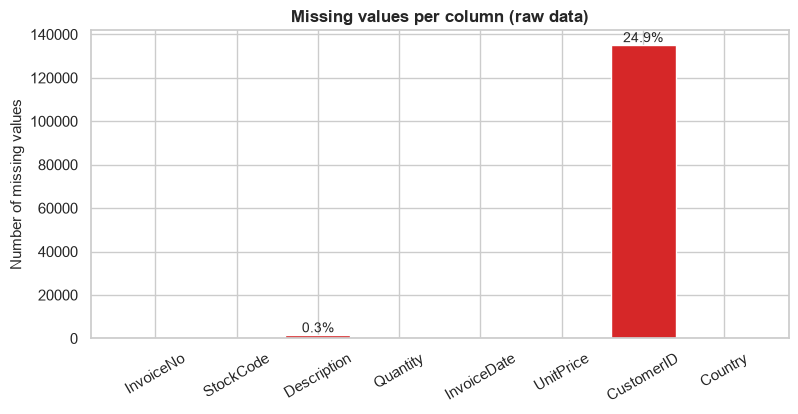

In [8]:
# =====================================================================
# 4.2  MISSING VALUES: table and chart
# =====================================================================
missing_table = pd.DataFrame({"Missing values": df_raw.isna().sum(),
                              "Missing (%)": (df_raw.isna().mean() * 100).round(2)})
display(missing_table)

both_missing = int((df_raw["Description"].isna() & df_raw["CustomerID"].isna()).sum())
print(f"Rows where BOTH Description and CustomerID are missing: {both_missing:,} "
      f"(of {int(df_raw['Description'].isna().sum()):,} rows with a missing Description)")

fig, ax = plt.subplots(figsize=(9, 4))
bars = ax.bar(missing_table.index, missing_table["Missing values"],
              color=["#d62728" if v > 0 else "#9e9e9e" for v in missing_table["Missing values"]])
for bar, pct in zip(bars, missing_table["Missing (%)"]):
    if pct > 0:
        ax.annotate(f"{pct:.1f}%", (bar.get_x() + bar.get_width() / 2, bar.get_height()),
                    ha="center", va="bottom", fontsize=10)
ax.set_title("Missing values per column (raw data)")
ax.set_ylabel("Number of missing values")
ax.tick_params(axis="x", rotation=30)
save_fig(fig, "fig_04_missing_values")

,Rows
First character of InvoiceNo,
digit (normal invoice),532618
C,9288
A,3


100.0% of the 'C' rows have a NEGATIVE Quantity → 'C' marks a cancellation (evidence for the rule).

Other non-numeric invoices (3 rows): these are accounting adjustments. They have no CustomerID and are removed by the cleaning steps anyway:


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
299982,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom
299983,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom
299984,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom


Rows with negative Quantity that are NOT 'C' invoices: 1,336 (100% of them have no CustomerID, e.g. stock adjustments)

Number of countries: 38. Top 10 by number of transaction rows:


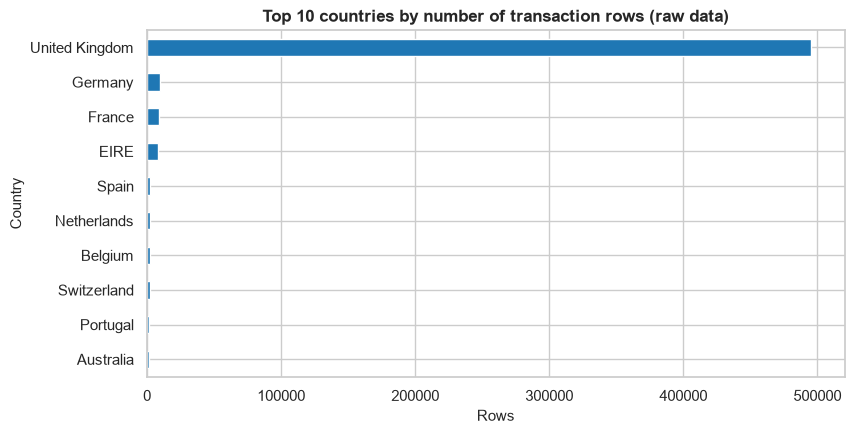

In [9]:
# =====================================================================
# 4.3  ARE "C" INVOICES REALLY CANCELLATIONS? + COUNTRIES
# =====================================================================
first_char = invoice_text.str[0]
prefix_type = first_char.where(~first_char.str.isdigit(), "digit (normal invoice)")
display(prefix_type.value_counts().rename_axis("First character of InvoiceNo").to_frame("Rows"))

share_negative = (df_raw.loc[is_cancelled_row, "Quantity"] < 0).mean()
print(f"{share_negative:.1%} of the 'C' rows have a NEGATIVE Quantity → 'C' marks a cancellation (evidence for the rule).")

other_prefix_rows = df_raw[~is_cancelled_row & ~first_char.str.isdigit()]
if len(other_prefix_rows) > 0:
    print(f"\nOther non-numeric invoices ({len(other_prefix_rows)} rows): these are accounting adjustments. "
          "They have no CustomerID and are removed by the cleaning steps anyway:")
    display(other_prefix_rows)

negative_not_cancelled = df_raw[(df_raw["Quantity"] < 0) & ~is_cancelled_row]
print(f"Rows with negative Quantity that are NOT 'C' invoices: {len(negative_not_cancelled):,} "
      f"({negative_not_cancelled['CustomerID'].isna().mean():.0%} of them have no CustomerID, e.g. stock adjustments)")

country_counts = df_raw["Country"].value_counts()
print(f"\nNumber of countries: {country_counts.size}. Top 10 by number of transaction rows:")
fig, ax = plt.subplots(figsize=(9, 4.5))
country_counts.head(10).sort_values().plot(kind="barh", ax=ax, color="#1f77b4")
ax.set_title("Top 10 countries by number of transaction rows (raw data)")
ax.set_xlabel("Rows")
save_fig(fig, "fig_04_top_countries")


Preprocessing


0. Raw data                                rows = 541,909  (removed       0)  customers = 4,372  invoices = 25,900


1. Remove missing CustomerID               rows = 406,829  (removed 135,080)  customers = 4,372  invoices = 22,190
2. Convert InvoiceDate to datetime         rows = 406,829  (removed       0)  customers = 4,372  invoices = 22,190


3. Remove cancelled invoices ('C...')      rows = 397,924  (removed   8,905)  customers = 4,339  invoices = 18,536
4. Keep Quantity > 0                       rows = 397,924  (removed       0)  customers = 4,339  invoices = 18,536


5. Keep UnitPrice > 0                      rows = 397,884  (removed      40)  customers = 4,338  invoices = 18,532


6. Remove exact duplicate rows             rows = 392,692  (removed   5,192)  customers = 4,338  invoices = 18,532

Rows with a missing Description but a valid CustomerID: 0


Rows after df.dropna() on ALL columns: 406,829 | after dropping missing CustomerID: 406,829 → the two rules are identical here.

PREPROCESSING SUMMARY


,Step,Rows Remaining,Rows Removed,Customers,Invoices
0,0. Raw data,541909,0,4372,25900
1,1. Remove missing CustomerID,406829,135080,4372,22190
2,2. Convert InvoiceDate to datetime,406829,0,4372,22190
3,3. Remove cancelled invoices ('C...'),397924,8905,4339,18536
4,4. Keep Quantity > 0,397924,0,4339,18536
5,5. Keep UnitPrice > 0,397884,40,4338,18532
6,6. Remove exact duplicate rows,392692,5192,4338,18532


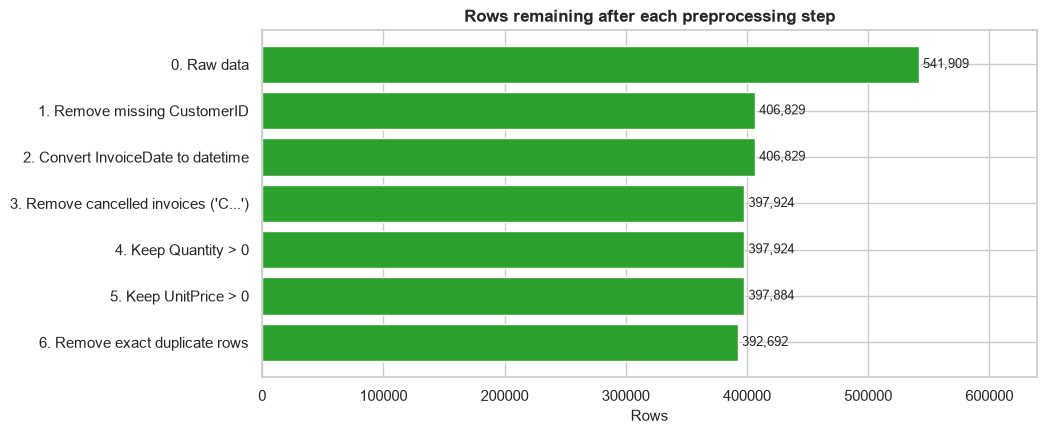

In [10]:
# =====================================================================
# 5.1  CLEANING FUNCTION + PREPROCESSING SUMMARY TABLE
# =====================================================================
def dataset_counts(step, data, rows_removed=0):
    """One row of the preprocessing summary table."""
    return {"Step": step, "Rows Remaining": len(data), "Rows Removed": rows_removed,
            "Customers": int(data["CustomerID"].nunique()), "Invoices": int(data["InvoiceNo"].nunique())}

def clean_online_retail(raw_df, remove_duplicates=True):
    """Apply the paper's preprocessing steps (+ optional duplicate removal).

    Returns
    -------
    clean_df       : cleaned transactions (used for RFM and CLV)
    cancellations  : the removed 'C' rows that have a CustomerID (used later for the CLV target)
    summary        : Step | Rows Remaining | Rows Removed | Customers | Invoices
    """
    steps = []

    def log(step, data, removed):
        steps.append(dataset_counts(step, data, removed))
        s = steps[-1]
        print(f"{step:<42} rows = {s['Rows Remaining']:>7,}  (removed {removed:>7,})  "
              f"customers = {s['Customers']:>5,}  invoices = {s['Invoices']:>6,}")

    df = raw_df.copy()
    df["InvoiceNo"] = df["InvoiceNo"].astype(str).str.strip()
    df["StockCode"] = df["StockCode"].astype(str).str.strip()
    log("0. Raw data", df, 0)

    # Step 1: rows without a customer cannot be used for customer-level RFM
    before = len(df)
    df = df.dropna(subset=["CustomerID"]).copy()
    log("1. Remove missing CustomerID", df, before - len(df))

    # Step 2: correct data types (dates as datetime, customer IDs as whole numbers)
    df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"])
    df["CustomerID"] = df["CustomerID"].astype("int64")
    log("2. Convert InvoiceDate to datetime", df, 0)

    # Step 3: cancelled invoices start with 'C' (verified in Section 4.3)
    is_cancelled = df["InvoiceNo"].str.upper().str.startswith("C")
    cancellations = df[is_cancelled].copy()
    before = len(df)
    df = df[~is_cancelled]
    log("3. Remove cancelled invoices ('C...')", df, before - len(df))

    # Steps 4 and 5: only real sales (positive quantity and positive price)
    before = len(df)
    df = df[df["Quantity"] > 0]
    log("4. Keep Quantity > 0", df, before - len(df))
    before = len(df)
    df = df[df["UnitPrice"] > 0]
    log("5. Keep UnitPrice > 0", df, before - len(df))

    # Step 6 (optional): exact duplicate rows
    if remove_duplicates:
        before = len(df)
        df = df.drop_duplicates()
        log("6. Remove exact duplicate rows", df, before - len(df))
        cancellations = cancellations.drop_duplicates()

    return df.reset_index(drop=True), cancellations.reset_index(drop=True), pd.DataFrame(steps)

banner("Preprocessing")
df_clean, df_cancellations, preprocessing_summary = clean_online_retail(df_raw, REMOVE_DUPLICATES)

# The paper drops every row with a NaN. Check that this equals "drop missing CustomerID" in this file:
desc_missing_only = int((df_raw["Description"].isna() & df_raw["CustomerID"].notna()).sum())
print(f"\nRows with a missing Description but a valid CustomerID: {desc_missing_only}")
print(f"Rows after df.dropna() on ALL columns: {len(df_raw.dropna()):,} | after dropping missing CustomerID: "
      f"{preprocessing_summary.loc[1, 'Rows Remaining']:,} → the two rules are "
      f"{'identical' if len(df_raw.dropna()) == preprocessing_summary.loc[1, 'Rows Remaining'] else 'NOT identical'} here.")

print("\nPREPROCESSING SUMMARY")
display(preprocessing_summary)

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(preprocessing_summary["Step"], preprocessing_summary["Rows Remaining"], color="#2ca02c")
ax.invert_yaxis()
for i, v in enumerate(preprocessing_summary["Rows Remaining"]):
    ax.text(v, i, f" {v:,}", va="center", fontsize=9)
ax.set_title("Rows remaining after each preprocessing step")
ax.set_xlabel("Rows")
ax.set_xlim(0, preprocessing_summary["Rows Remaining"].max() * 1.18)
save_fig(fig, "fig_05_preprocessing_rows")

Examples:


,InvoiceNo,CustomerID,Description,Quantity,UnitPrice,Revenue
0,536365,17850,WHITE HANGING HEART T-LIGHT HOLDER,6,2.55,15.30
1,536365,17850,WHITE METAL LANTERN,6,3.39,20.34
2,536365,17850,CREAM CUPID HEARTS COAT HANGER,8,2.75,22.00
3,536365,17850,KNITTED UNION FLAG HOT WATER BOTTLE,6,3.39,20.34
4,536365,17850,RED WOOLLY HOTTIE WHITE HEART.,6,3.39,20.34


,Metric,Value (£)
0,Total revenue,"8,887,208.89"
1,Average revenue per transaction line,22.63
2,Median revenue per transaction line,12.45
3,Average revenue per invoice (order),479.56
4,Median revenue per invoice (order),302.57


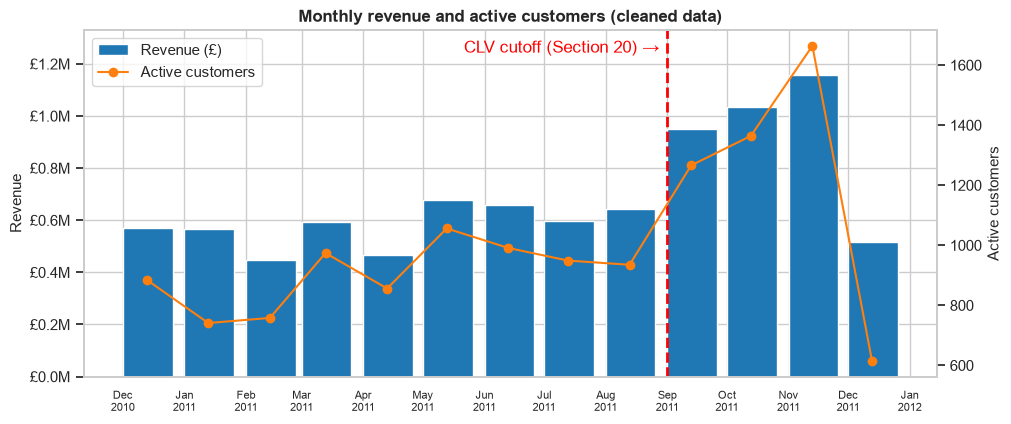

Note: the last month is incomplete, because the data stops at 2011-12-09


In [11]:
# =====================================================================
# 6.1  REVENUE = QUANTITY × UNIT PRICE
# =====================================================================
df_clean["Revenue"] = df_clean["Quantity"] * df_clean["UnitPrice"]

print("Examples:")
display(df_clean[["InvoiceNo", "CustomerID", "Description", "Quantity", "UnitPrice", "Revenue"]].head())

invoice_revenue = df_clean.groupby("InvoiceNo")["Revenue"].sum()
revenue_summary = pd.DataFrame({
    "Metric": ["Total revenue", "Average revenue per transaction line", "Median revenue per transaction line",
               "Average revenue per invoice (order)", "Median revenue per invoice (order)"],
    "Value (£)": [df_clean["Revenue"].sum(), df_clean["Revenue"].mean(), df_clean["Revenue"].median(),
                  invoice_revenue.mean(), invoice_revenue.median()],
})
revenue_summary["Value (£)"] = revenue_summary["Value (£)"].map(lambda v: f"{v:,.2f}")
display(revenue_summary)

# Monthly revenue and active customers (also shows where the CLV cutoff of Section 20 lies)
monthly = (df_clean.set_index("InvoiceDate")
           .groupby(pd.Grouper(freq="MS"))
           .agg(Revenue=("Revenue", "sum"), ActiveCustomers=("CustomerID", "nunique")))
fig, ax1 = plt.subplots(figsize=(11, 4.5))
ax1.bar(monthly.index, monthly["Revenue"], width=25, align="edge", color="#1f77b4", label="Revenue (£)")
ax1.set_ylabel("Revenue")
ax1.yaxis.set_major_formatter(mticker.FuncFormatter(lambda v, _: f"£{v / 1e6:.1f}M"))
ax1.set_ylim(0, monthly["Revenue"].max() * 1.15)
ax2 = ax1.twinx()
ax2.plot(monthly.index + pd.Timedelta(days=12), monthly["ActiveCustomers"], color="#ff7f0e", marker="o",
         label="Active customers")
ax2.set_ylabel("Active customers")
ax2.grid(False)
cutoff_line = pd.Timestamp(CLV_CUTOFF_DATE)
ax1.axvline(cutoff_line, color="red", linestyle="--", linewidth=2)
ax1.text(cutoff_line - pd.Timedelta(days=4), ax1.get_ylim()[1] * 0.97, "CLV cutoff (Section 20) →",
         color="red", ha="right", va="top")
ax1.xaxis.set_major_locator(mdates.MonthLocator())
ax1.xaxis.set_major_formatter(mdates.DateFormatter("%b\n%Y"))
ax1.tick_params(axis="x", labelsize=8)
ax1.set_title("Monthly revenue and active customers (cleaned data)")
handles1, labels1 = ax1.get_legend_handles_labels()
handles2, labels2 = ax2.get_legend_handles_labels()
ax2.legend(handles1 + handles2, labels1 + labels2, loc="upper left")
save_fig(fig, "fig_06_monthly_revenue")
print("Note: the last month is incomplete, because the data stops at", df_clean["InvoiceDate"].max().date())

In [12]:
# =====================================================================
# 6.2  WERE THE LARGEST ORDER LINES REVERSED BY A CANCELLATION?
# =====================================================================
cancel_keys = df_cancellations[["CustomerID", "StockCode", "Quantity", "UnitPrice", "InvoiceNo", "InvoiceDate"]].copy()
cancel_keys["Quantity"] = -cancel_keys["Quantity"]                     # cancellation quantity is negative
cancel_keys = cancel_keys.rename(columns={"InvoiceNo": "CancelInvoice", "InvoiceDate": "CancelDate"})

largest_lines = df_clean.nlargest(5, "Revenue").reset_index(drop=True)
largest_lines["Line"] = range(1, len(largest_lines) + 1)
reversal_check = largest_lines.merge(cancel_keys, on=["CustomerID", "StockCode", "Quantity", "UnitPrice"], how="left")
# A reversal is a matching cancellation made AFTER the purchase (a match made before it is a different event)
reversal_check["Reversed by a cancellation?"] = reversal_check["CancelDate"] >= reversal_check["InvoiceDate"]
reversal_check = (reversal_check.sort_values(["Line", "Reversed by a cancellation?"], ascending=[True, False])
                  .drop_duplicates("Line"))
reversal_check["Minutes until cancelled"] = np.where(
    reversal_check["Reversed by a cancellation?"],
    ((reversal_check["CancelDate"] - reversal_check["InvoiceDate"]).dt.total_seconds() / 60).round(0), np.nan)
reversal_check["CancelInvoice"] = reversal_check["CancelInvoice"].where(reversal_check["Reversed by a cancellation?"], "")
display(reversal_check[["InvoiceNo", "CustomerID", "Description", "Quantity", "UnitPrice", "Revenue",
                        "InvoiceDate", "CancelInvoice", "Minutes until cancelled", "Reversed by a cancellation?"]])
print(f"{int(reversal_check['Reversed by a cancellation?'].sum())} of the 5 largest revenue lines were reversed by an "
      "identical cancellation.")

,InvoiceNo,CustomerID,Description,Quantity,UnitPrice,Revenue,InvoiceDate,CancelInvoice,Minutes until cancelled,Reversed by a cancellation?
0,581483,16446,"PAPER CRAFT , LITTLE BIRDIE",80995,2.08,168469.60,2011-12-09 09:15:00,C581484,12.0,True
1,541431,12346,MEDIUM CERAMIC TOP STORAGE JAR,74215,1.04,77183.60,2011-01-18 10:01:00,C541433,16.0,True
2,556444,15098,PICNIC BASKET WICKER 60 PIECES,60,649.50,38970.00,2011-06-10 15:28:00,,NaN,False
3,551697,16029,POSTAGE,1,8142.75,8142.75,2011-05-03 13:46:00,,NaN,False
4,567423,17450,SET OF TEA COFFEE SUGAR TINS PANTRY,1412,5.06,7144.72,2011-09-20 11:05:00,,NaN,False


2 of the 5 largest revenue lines were reversed by an identical cancellation.


In [13]:
# =====================================================================
# 7.1  CREATE THE CUSTOMER-LEVEL RFM TABLE
# =====================================================================
def create_rfm(transactions, snapshot_date=None):
    """One row per customer: Recency (days), Frequency (unique invoices), Monetary (total revenue)."""
    if snapshot_date is None:
        snapshot_date = transactions["InvoiceDate"].max() + pd.Timedelta(days=1)
    rfm = (transactions.groupby("CustomerID")
           .agg(LastPurchase=("InvoiceDate", "max"),
                Frequency=("InvoiceNo", "nunique"),
                Monetary=("Revenue", "sum"))
           .reset_index())
    rfm["Recency"] = (snapshot_date - rfm["LastPurchase"]).dt.days
    return rfm[["CustomerID", "Recency", "Frequency", "Monetary"]]

snapshot_date = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)
rfm_raw = create_rfm(df_clean, snapshot_date)

print("Snapshot date (last InvoiceDate + 1 day):", snapshot_date)
print("RFM shape (customers, columns):", rfm_raw.shape)
display(rfm_raw.head())
print("Descriptive statistics:")
display(rfm_raw[RFM_COLS].describe().round(2))

print("Check: total Monetary equals total revenue →",
      np.isclose(rfm_raw["Monetary"].sum(), df_clean["Revenue"].sum()))
example = rfm_raw.iloc[0]
print(f"\nExample: customer {int(example['CustomerID'])} last bought {int(example['Recency'])} days before the snapshot, "
      f"placed {int(example['Frequency'])} order(s) and spent £{example['Monetary']:,.2f} in total.")

Snapshot date (last InvoiceDate + 1 day): 2011-12-10 12:50:00
RFM shape (customers, columns): (4338, 4)


,CustomerID,Recency,Frequency,Monetary
0,12346,326,1,77183.60
1,12347,2,7,4310.00
2,12348,75,4,1797.24
3,12349,19,1,1757.55
4,12350,310,1,334.40


Descriptive statistics:


,Recency,Frequency,Monetary
count,4338.00,4338.00,4338.00
mean,92.54,4.27,2048.69
std,100.01,7.70,8985.23
min,1.00,1.00,3.75
25%,18.00,1.00,306.48
50%,51.00,2.00,668.57
75%,142.00,5.00,1660.60
max,374.00,209.00,280206.02


Check: total Monetary equals total revenue → True

Example: customer 12346 last bought 326 days before the snapshot, placed 1 order(s) and spent £77,183.60 in total.


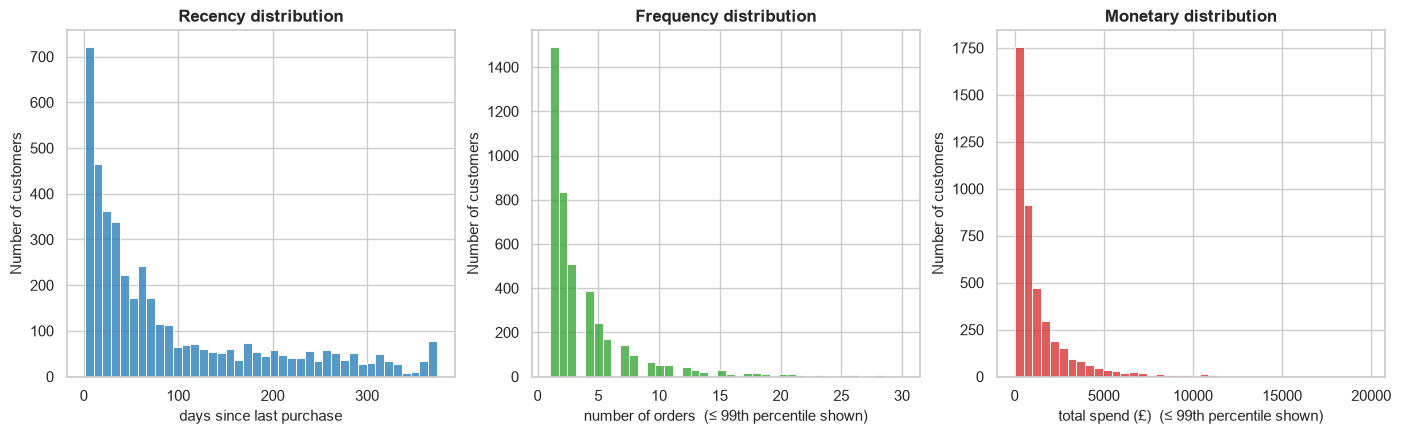

Frequency and Monetary x-axes stop at the 99th percentile for readability. The boxplots below show the full range.


In [14]:
# =====================================================================
# 8.1  HISTOGRAMS OF R, F, M
# =====================================================================
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
colors = {"Recency": "#1f77b4", "Frequency": "#2ca02c", "Monetary": "#d62728"}
units = {"Recency": "days since last purchase", "Frequency": "number of orders", "Monetary": "total spend (£)"}
for ax, col in zip(axes, RFM_COLS):
    upper = rfm_raw[col].quantile(0.99) if col != "Recency" else rfm_raw[col].max()
    shown = rfm_raw.loc[rfm_raw[col] <= upper, col]
    sns.histplot(shown, bins=40, ax=ax, color=colors[col], edgecolor="white")
    ax.set_title(f"{col} distribution")
    ax.set_xlabel(units[col] + ("" if col == "Recency" else "  (≤ 99th percentile shown)"))
    ax.set_ylabel("Number of customers")
save_fig(fig, "fig_08_rfm_histograms")
print("Frequency and Monetary x-axes stop at the 99th percentile for readability. The boxplots below show the full range.")

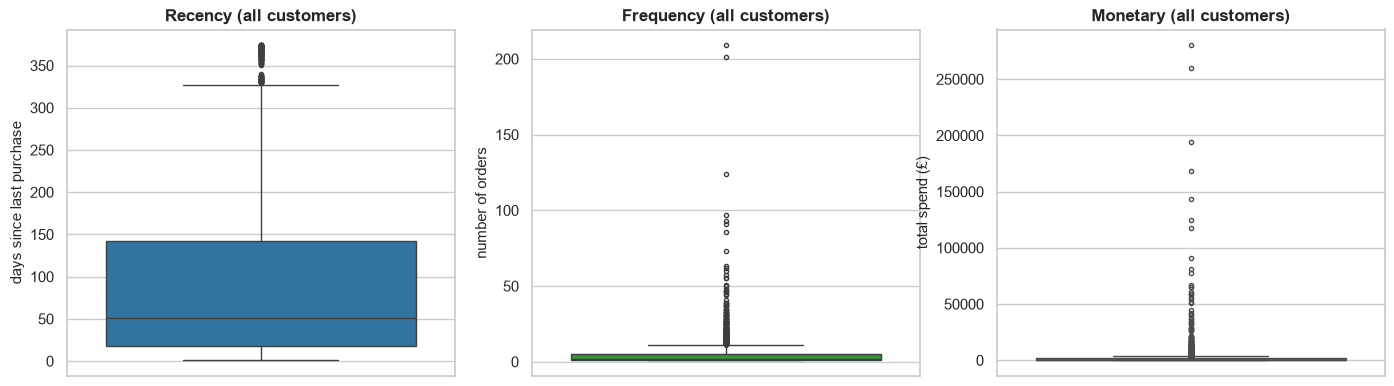

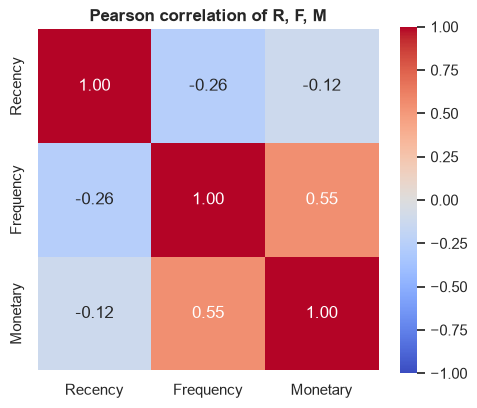

In [15]:
# =====================================================================
# 8.2  BOXPLOTS AND CORRELATION HEATMAP
# =====================================================================
fig, axes = plt.subplots(1, 3, figsize=(17, 4.5))
for ax, col in zip(axes, RFM_COLS):
    sns.boxplot(y=rfm_raw[col], ax=ax, color=colors[col], flierprops={"markersize": 3})
    ax.set_title(f"{col} (all customers)")
    ax.set_ylabel(units[col])
save_fig(fig, "fig_08_rfm_boxplots")

fig, ax = plt.subplots(figsize=(5.5, 4.5))
sns.heatmap(rfm_raw[RFM_COLS].corr(), annot=True, fmt=".2f", cmap="coolwarm", vmin=-1, vmax=1, ax=ax, square=True)
ax.set_title("Pearson correlation of R, F, M")
save_fig(fig, "fig_08_rfm_correlation")

IQR bounds (computed on all customers):


,Q1,Q3,IQR,Lower Bound,Upper Bound,Outliers (customers)
Feature,,,,,,
Recency,18.00,142.0,124.00,-168.00,328.00,155
Frequency,1.00,5.0,4.00,-5.00,11.00,285
Monetary,306.48,1660.6,1354.11,-1724.69,3691.77,425


RFM rows before outlier removal : 4,338
RFM rows after outlier removal  : 3,710
Customers removed               : 628  (14.48%)
Note: the lower bounds of Frequency and Monetary are negative, so only unusually HIGH values are removed there.


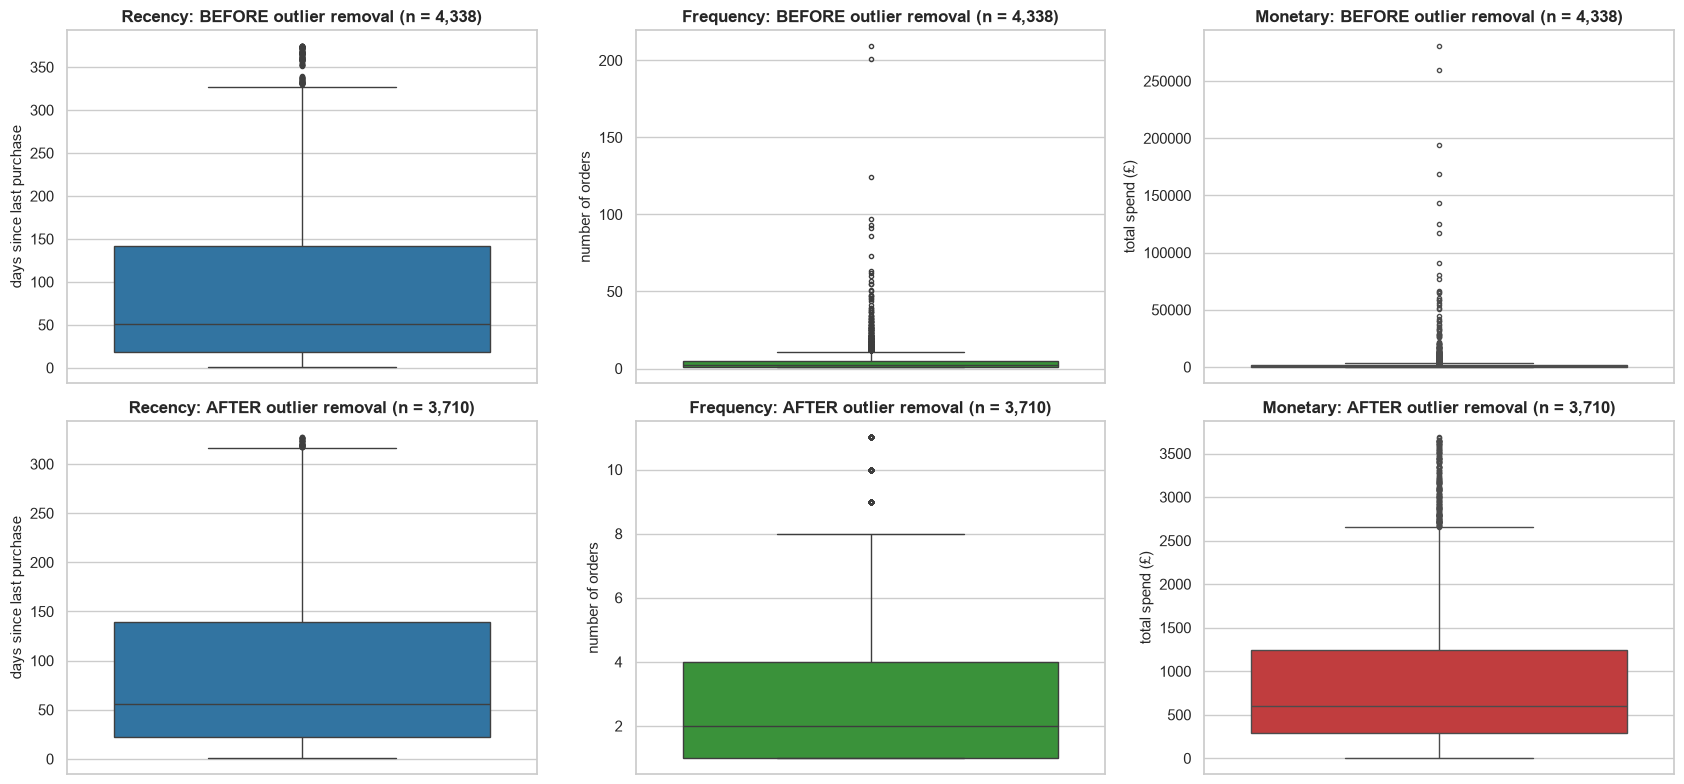

A few points can still appear as 'outliers' in the AFTER plots: the boxplot recomputes its whiskers on the
reduced data. All remaining values are inside the bounds that were computed on the full table.


,Recency,Frequency,Monetary
count,3710.00,3710.00,3710.00
mean,90.23,2.83,883.21
std,88.97,2.19,810.84
min,1.00,1.00,3.75
25%,22.00,1.00,293.19
50%,56.00,2.00,599.16
75%,139.75,4.00,1239.15
max,327.00,11.00,3683.86


In [16]:
# =====================================================================
# 9.1  IQR BOUNDS AND OUTLIER REMOVAL
# =====================================================================
def compute_iqr_bounds(rfm, columns=RFM_COLS, factor=IQR_FACTOR):
    """Q1, Q3, IQR, lower/upper bounds and the number of outliers for each feature."""
    rows = []
    for col in columns:
        q1, q3 = rfm[col].quantile(0.25), rfm[col].quantile(0.75)
        iqr = q3 - q1
        lower, upper = q1 - factor * iqr, q3 + factor * iqr
        rows.append({"Feature": col, "Q1": q1, "Q3": q3, "IQR": iqr, "Lower Bound": lower, "Upper Bound": upper,
                     "Outliers (customers)": int(((rfm[col] < lower) | (rfm[col] > upper)).sum())})
    return pd.DataFrame(rows).set_index("Feature")

def remove_iqr_outliers(rfm, columns=RFM_COLS, factor=IQR_FACTOR):
    """Keep only customers whose R, F and M values are ALL inside their IQR bounds."""
    bounds = compute_iqr_bounds(rfm, columns, factor)
    keep = pd.Series(True, index=rfm.index)
    for col in columns:
        keep &= rfm[col].between(bounds.loc[col, "Lower Bound"], bounds.loc[col, "Upper Bound"])
    return rfm[keep].reset_index(drop=True), bounds

rfm_clean, iqr_bounds = remove_iqr_outliers(rfm_raw)
print("IQR bounds (computed on all customers):")
display(iqr_bounds.round(2))

n_before, n_after = len(rfm_raw), len(rfm_clean)
print(f"RFM rows before outlier removal : {n_before:,}")
print(f"RFM rows after outlier removal  : {n_after:,}")
print(f"Customers removed               : {n_before - n_after:,}  ({(n_before - n_after) / n_before:.2%})")
print("Note: the lower bounds of Frequency and Monetary are negative, so only unusually HIGH values are removed there.")

fig, axes = plt.subplots(2, 3, figsize=(17, 8))
for j, col in enumerate(RFM_COLS):
    sns.boxplot(y=rfm_raw[col], ax=axes[0, j], color=colors[col], flierprops={"markersize": 3})
    axes[0, j].set_title(f"{col}: BEFORE outlier removal (n = {n_before:,})")
    sns.boxplot(y=rfm_clean[col], ax=axes[1, j], color=colors[col], flierprops={"markersize": 3})
    axes[1, j].set_title(f"{col}: AFTER outlier removal (n = {n_after:,})")
    for i in range(2):
        axes[i, j].set_ylabel(units[col])
fig.tight_layout()
save_fig(fig, "fig_09_outlier_boxplots")
print("A few points can still appear as 'outliers' in the AFTER plots: the boxplot recomputes its whiskers on the")
print("reduced data. All remaining values are inside the bounds that were computed on the full table.")
display(rfm_clean[RFM_COLS].describe().round(2))

BEFORE scaling (original units):


,CustomerID,Recency,Frequency,Monetary
0,12348,75,4,1797.24
1,12349,19,1,1757.55
2,12350,310,1,334.40
3,12352,36,8,2506.04
4,12353,204,1,89.00


AFTER Min-Max scaling (0 … 1):


,CustomerID,Recency,Frequency,Monetary
0,12348,0.2270,0.3,0.4873
1,12349,0.0552,0.0,0.4766
2,12350,0.9479,0.0,0.0898
3,12352,0.1074,0.7,0.6799
4,12353,0.6227,0.0,0.0232


Min / max of the scaled features:


,Recency,Frequency,Monetary
min,0.0,0.0,0.0
max,1.0,1.0,1.0


Clustering matrix X_rfm shape: (3710, 3) (customers × features)


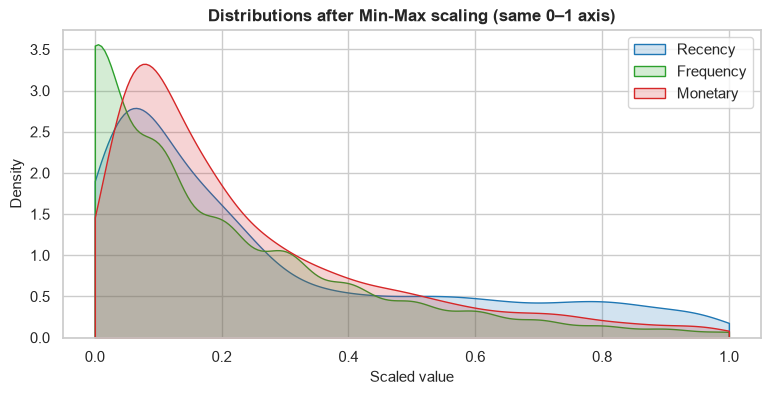

In [17]:
# =====================================================================
# 10.1  MIN-MAX SCALING OF R, F, M
# =====================================================================
def scale_rfm(rfm, columns=RFM_COLS):
    """Return a scaled copy of the RFM features (values in [0, 1]) and the fitted scaler."""
    scaler = MinMaxScaler()
    scaled = pd.DataFrame(scaler.fit_transform(rfm[columns]), columns=columns, index=rfm.index)
    scaled.insert(0, "CustomerID", rfm["CustomerID"].values)
    return scaled, scaler

rfm_scaled, rfm_scaler = scale_rfm(rfm_clean)
X_rfm = rfm_scaled[RFM_COLS].to_numpy()          # the matrix used by ALL clustering algorithms

print("BEFORE scaling (original units):")
display(rfm_clean.head())
print("AFTER Min-Max scaling (0 … 1):")
display(rfm_scaled.head().round(4))
print("Min / max of the scaled features:")
display(rfm_scaled[RFM_COLS].agg(["min", "max"]).round(4))
print("Clustering matrix X_rfm shape:", X_rfm.shape, "(customers × features)")

fig, ax = plt.subplots(figsize=(9, 4))
for col in RFM_COLS:
    sns.kdeplot(rfm_scaled[col], ax=ax, label=col, color=colors[col], fill=True, alpha=0.2, cut=0)
ax.set_title("Distributions after Min-Max scaling (same 0–1 axis)")
ax.set_xlabel("Scaled value")
ax.legend()
save_fig(fig, "fig_10_scaled_distributions")

,K,Inertia (WCSS),Decrease vs previous K (%)
0,2,373.035,NaN
1,3,190.557,48.9
2,4,152.456,20.0
3,5,128.906,15.4
4,6,110.439,14.3
5,7,98.852,10.5
6,8,90.256,8.7
7,9,82.884,8.2
8,10,76.614,7.6


Automatic elbow, rule 1 (max distance to the first-last line): K = 4
Automatic elbow, rule 2 (sharpest bend / 2nd difference)     : K = 3
→ The rules disagree: the elbow is ambiguous here, so Silhouette and Davies–Bouldin decide (Sections 12–16).


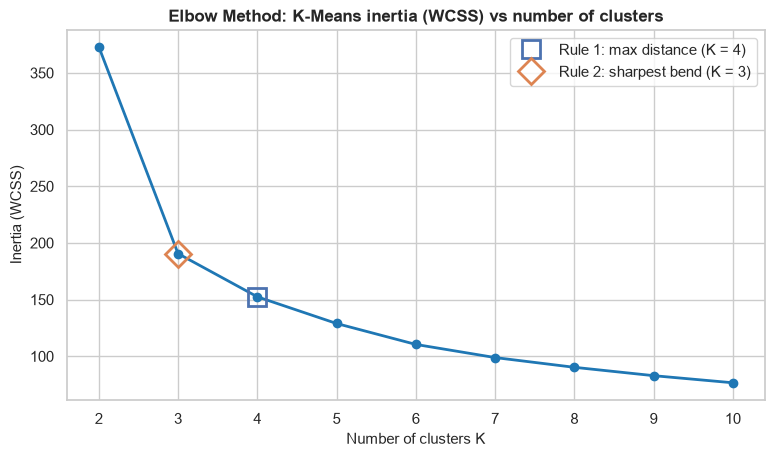

In [18]:
# =====================================================================
# 11.1  WCSS (INERTIA) FOR K = 2 … 10 AND ELBOW DETECTION
# =====================================================================
def find_kmeans_inertia(X, k_values=K_RANGE, init="random", n_init=10, random_state=RANDOM_STATE):
    """Run K-Means for every K and return a table of K and inertia (WCSS)."""
    rows = []
    for k in k_values:
        model = KMeans(n_clusters=k, init=init, n_init=n_init, random_state=random_state).fit(X)
        rows.append({"K": k, "Inertia (WCSS)": model.inertia_})
    return pd.DataFrame(rows)

def elbow_by_max_distance(k_values, inertias):
    """Rule 1 (Kneedle idea): the point farthest from the straight line joining the first and last points."""
    k = np.asarray(k_values, dtype=float)
    y = np.asarray(inertias, dtype=float)
    k_norm = (k - k.min()) / (k.max() - k.min())
    y_norm = (y - y.min()) / (y.max() - y.min())
    distance = np.abs(k_norm + y_norm - 1) / np.sqrt(2)      # the line goes through (0, 1) and (1, 0)
    return int(k[np.argmax(distance)])

def elbow_by_sharpest_bend(k_values, inertias):
    """Rule 2: the K where the curve bends most sharply (largest second difference of WCSS)."""
    y = np.asarray(inertias, dtype=float)
    bend = y[:-2] - 2 * y[1:-1] + y[2:]
    return int(np.asarray(k_values)[1:-1][np.argmax(bend)])

elbow_table = find_kmeans_inertia(X_rfm)                     # standard K-Means (random initial centroids)
elbow_table["Decrease vs previous K (%)"] = (-elbow_table["Inertia (WCSS)"].pct_change() * 100).round(1)
display(elbow_table.round(3))

elbow_k_distance = elbow_by_max_distance(elbow_table["K"], elbow_table["Inertia (WCSS)"])
elbow_k_bend = elbow_by_sharpest_bend(elbow_table["K"], elbow_table["Inertia (WCSS)"])
print(f"Automatic elbow, rule 1 (max distance to the first-last line): K = {elbow_k_distance}")
print(f"Automatic elbow, rule 2 (sharpest bend / 2nd difference)     : K = {elbow_k_bend}")
if elbow_k_distance == elbow_k_bend:
    print("→ Both rules agree. This K is still checked with Silhouette and Davies–Bouldin below.")
else:
    print("→ The rules disagree: the elbow is ambiguous here, so Silhouette and Davies–Bouldin decide (Sections 12–16).")

fig, ax = plt.subplots(figsize=(9, 4.8))
ax.plot(elbow_table["K"], elbow_table["Inertia (WCSS)"], "o-", color="#1f77b4", linewidth=2)
for k_mark, style, label in [(elbow_k_distance, "s", "Rule 1: max distance"), (elbow_k_bend, "D", "Rule 2: sharpest bend")]:
    y_mark = elbow_table.set_index("K").loc[k_mark, "Inertia (WCSS)"]
    ax.plot(k_mark, y_mark, style, markersize=13, markerfacecolor="none", markeredgewidth=2, label=f"{label} (K = {k_mark})")
ax.set_title("Elbow Method: K-Means inertia (WCSS) vs number of clusters")
ax.set_xlabel("Number of clusters K")
ax.set_ylabel("Inertia (WCSS)")
ax.set_xticks(K_RANGE)
ax.legend()
save_fig(fig, "fig_11_elbow")

In [19]:
# =====================================================================
# 12.1  REUSABLE CLUSTERING HELPERS (used by all five algorithms)
# =====================================================================
cluster_results = {}          # model name -> final labels, metrics and settings

def evaluate_clusters(X, labels):
    """Number of clusters, Silhouette Score and Davies-Bouldin Index.
    Both metrics need at least 2 clusters, so NaN is returned when there is only one."""
    labels = np.asarray(labels)
    n_clusters = len(np.unique(labels))
    if n_clusters < 2 or n_clusters >= len(labels):
        return {"Number of Clusters": n_clusters, "Silhouette Score": np.nan, "Davies-Bouldin Index": np.nan}
    return {"Number of Clusters": n_clusters,
            "Silhouette Score": silhouette_score(X, labels),
            "Davies-Bouldin Index": davies_bouldin_score(X, labels)}

def cluster_sizes_text(labels):
    """Cluster sizes from largest to smallest, e.g. '1964 / 918 / 828'."""
    return " / ".join(str(v) for v in pd.Series(labels).value_counts().tolist())

def monetary_order_mapping(labels, monetary):
    """Cluster numbers are arbitrary. Renumber them so that cluster 0 has the HIGHEST mean Monetary,
    cluster 1 the next highest, and so on. This does NOT change which customers are grouped together."""
    means = pd.Series(np.asarray(monetary, dtype=float)).groupby(np.asarray(labels)).mean()
    return {old: new for new, old in enumerate(means.sort_values(ascending=False).index)}

def relabel_by_monetary(labels, monetary):
    return pd.Series(labels).map(monetary_order_mapping(labels, monetary)).to_numpy()

def cluster_size_table(labels):
    sizes = pd.Series(labels).value_counts().sort_index()
    return pd.DataFrame({"Cluster": sizes.index, "Customers": sizes.values,
                         "% of Customers": (100 * sizes.values / sizes.sum()).round(2)})

def select_k(sweep, model_name):
    """Paper's rule: highest Silhouette first; Davies-Bouldin is reported as the second check."""
    valid = sweep.dropna(subset=["Silhouette Score"])
    k_by_silhouette = int(valid.loc[valid["Silhouette Score"].idxmax(), "K"])
    k_by_dbi = int(valid.loc[valid["Davies-Bouldin Index"].idxmin(), "K"])
    chosen = K_OVERRIDES.get(model_name) or k_by_silhouette
    print(f"Highest Silhouette Score at K = {k_by_silhouette}; lowest Davies–Bouldin Index at K = {k_by_dbi}.")
    print("→ Both metrics point to the same K." if k_by_silhouette == k_by_dbi
          else "→ The metrics disagree; following the paper, the Silhouette Score is prioritised.")
    if K_OVERRIDES.get(model_name):
        print(f"→ Manual override from K_OVERRIDES is used: K = {chosen}.")
    print(f"Selected K for {model_name}: {chosen}")
    return chosen

def plot_k_sweep(sweep, model_name, cost_column, cost_label, selected_k, file_name):
    """Cost curve + Silhouette + Davies-Bouldin vs K, with the paper's values (if any) for comparison."""
    paper_values = PAPER_K_TABLES.get(model_name, {})
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.3))
    axes[0].plot(sweep["K"], sweep[cost_column], "o-", color="#1f77b4", label="Our reproduction")
    axes[1].plot(sweep["K"], sweep["Silhouette Score"], "o-", color="#2ca02c", label="Our reproduction")
    axes[2].plot(sweep["K"], sweep["Davies-Bouldin Index"], "o-", color="#d62728", label="Our reproduction")
    if paper_values:
        paper_k = sorted(paper_values)
        axes[1].plot(paper_k, [paper_values[k][0] for k in paper_k], "s--", color="gray", label="Reference paper (Dataset 1)")
        axes[2].plot(paper_k, [paper_values[k][1] for k in paper_k], "s--", color="gray", label="Reference paper (Dataset 1)")
    axes[0].set_title(f"{model_name}: {cost_label}")
    axes[1].set_title(f"{model_name}: Silhouette Score (higher = better)")
    axes[2].set_title(f"{model_name}: Davies–Bouldin Index (lower = better)")
    axes[0].set_ylabel(cost_label)
    axes[1].set_ylabel("Silhouette Score")
    axes[2].set_ylabel("Davies–Bouldin Index")
    for ax in axes:
        ax.axvline(selected_k, color="black", linestyle=":", label=f"Selected K = {selected_k}")
        ax.set_xlabel("Number of clusters K")
        ax.set_xticks(list(sweep["K"]))
        ax.legend(fontsize=8)
    fig.tight_layout()
    save_fig(fig, file_name)

def plot_cluster_views(rfm_values, labels, title, file_name):
    """(1) Frequency vs Monetary, (2) Recency vs Monetary, (3) cluster sizes, all in ORIGINAL units."""
    labels = np.asarray(labels)
    clusters = np.sort(np.unique(labels))
    palette = cluster_palette(len(clusters))
    rng = np.random.default_rng(RANDOM_STATE)
    frequency_jittered = rfm_values["Frequency"].to_numpy() + rng.uniform(-0.25, 0.25, len(labels))
    fig, axes = plt.subplots(1, 3, figsize=(18, 4.8))
    for color, c in zip(palette, clusters):
        mask = labels == c
        axes[0].scatter(frequency_jittered[mask], rfm_values["Monetary"].to_numpy()[mask], s=9, alpha=0.55,
                        color=color, label=f"Cluster {c}")
        axes[1].scatter(rfm_values["Recency"].to_numpy()[mask], rfm_values["Monetary"].to_numpy()[mask], s=9,
                        alpha=0.55, color=color, label=f"Cluster {c}")
    sizes = pd.Series(labels).value_counts().sort_index()
    axes[2].bar([f"C{c}" for c in sizes.index], sizes.values, color=palette)
    for i, v in enumerate(sizes.values):
        axes[2].text(i, v, f"{v:,}\n({v / sizes.sum():.0%})", ha="center", va="bottom", fontsize=8)
    axes[0].set_title("Frequency vs Monetary")
    axes[0].set_xlabel("Frequency (orders; jittered ±0.25 for visibility)")
    axes[1].set_title("Recency vs Monetary")
    axes[1].set_xlabel("Recency (days since last purchase)")
    for ax in axes[:2]:
        ax.set_ylabel("Monetary (£)")
    axes[1].legend(markerscale=2, fontsize=8, loc="upper right")
    axes[2].set_title("Cluster sizes")
    axes[2].set_ylabel("Customers")
    axes[2].set_ylim(0, sizes.max() * 1.25)
    fig.suptitle(title, fontweight="bold", fontsize=13)
    fig.tight_layout()
    save_fig(fig, file_name)

def register_result(model_name, labels, setting, column_name, model=None, sweep=None):
    """Store the final labels + metrics of an algorithm and add the labels as a column of rfm_clean."""
    metrics = evaluate_clusters(X_rfm, labels)
    cluster_results[model_name] = {"labels": np.asarray(labels), "setting": setting, "model": model,
                                   "sweep": sweep, **metrics}
    rfm_clean[column_name] = np.asarray(labels)
    return metrics

def compare_with_paper(model_name, sweep=None):
    """Print 'Reference Paper Result' vs 'Our Reproduction Result' for one algorithm."""
    paper = PAPER_CLUSTERING.set_index("Model").loc[model_name]
    ours = cluster_results[model_name]
    print(f"Reference Paper Result (Dataset 1, {paper['Paper Source']}): K = {int(paper['Paper K'])}, "
          f"Silhouette = {paper['Paper Silhouette']:.4f}, Davies–Bouldin = {paper['Paper Davies-Bouldin']:.4f}")
    print(f"Our Reproduction Result: K = {ours['Number of Clusters']}, Silhouette = {ours['Silhouette Score']:.4f}, "
          f"Davies–Bouldin = {ours['Davies-Bouldin Index']:.4f}")
    if sweep is not None and int(paper["Paper K"]) in set(sweep["K"]):
        row = sweep.set_index("K").loc[int(paper["Paper K"])]
        print(f"Our result at the paper's K (K = {int(paper['Paper K'])}): Silhouette = {row['Silhouette Score']:.4f}, "
              f"Davies–Bouldin = {row['Davies-Bouldin Index']:.4f}")

print("Clustering helper functions are ready.")

Clustering helper functions are ready.



K-Means (init='random', n_init=10): K = 2 … 10


,K,Inertia (WCSS),Number of Clusters,Silhouette Score,Davies-Bouldin Index,Cluster sizes (largest → smallest)
0,2,373.0354,2,0.4020,0.9964,2602 / 1108
1,3,190.5565,3,0.4787,0.7591,1964 / 918 / 828
2,4,152.4562,4,0.4076,0.9162,1474 / 893 / 879 / 464
3,5,128.9062,5,0.3808,0.9403,1303 / 828 / 601 / 508 / 470
4,6,110.4386,6,0.3725,0.9885,1241 / 736 / 596 / 507 / 350 / 280
5,7,98.8522,7,0.3521,0.9874,1087 / 706 / 579 / 508 / 321 / 274 / 235
6,8,90.2559,8,0.3486,1.0034,1056 / 613 / 499 / 464 / 346 / 288 / 232 / 212
7,9,82.8838,9,0.3194,0.9925,743 / 606 / 538 / 452 / 437 / 291 / 251 / 199 ...
8,10,76.6138,10,0.3204,1.0056,734 / 526 / 450 / 423 / 421 / 304 / 304 / 192 ...


Highest Silhouette Score at K = 3; lowest Davies–Bouldin Index at K = 3.
→ Both metrics point to the same K.
Selected K for K-Means: 3
(Elbow rules from Section 11: K = 4 and K = 3)


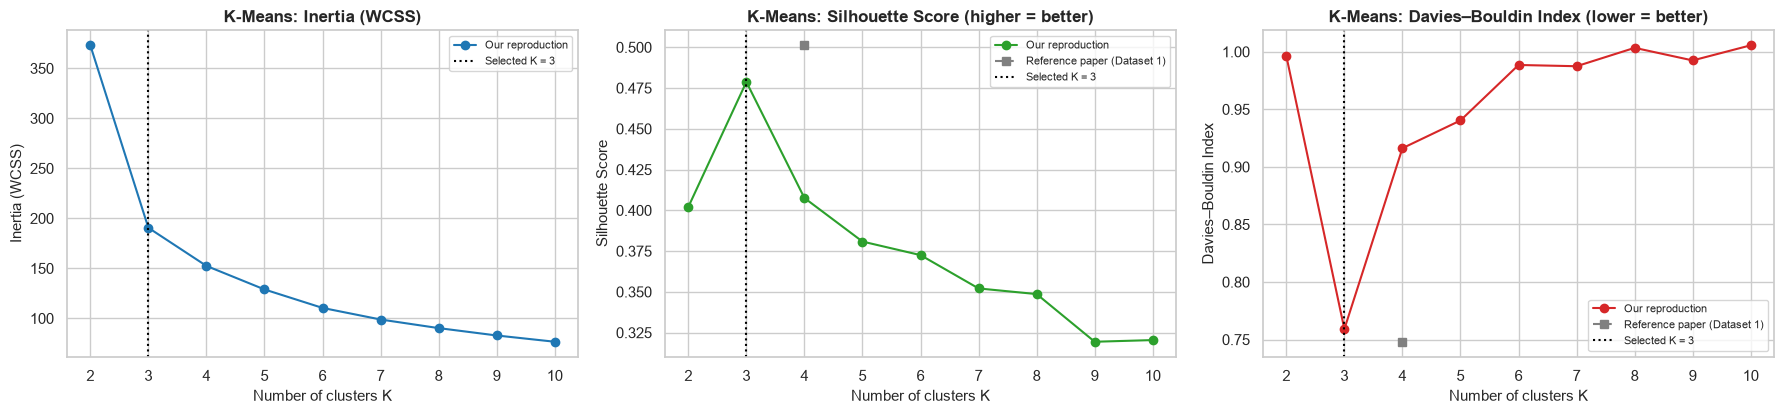

In [20]:
# =====================================================================
# 12.2  K-MEANS (random initialisation): evaluate K = 2 … 10
# =====================================================================
def run_kmeans(X, n_clusters, init="random", n_init=10, random_state=RANDOM_STATE):
    """Fit K-Means and return (model, labels)."""
    model = KMeans(n_clusters=n_clusters, init=init, n_init=n_init, random_state=random_state)
    return model, model.fit_predict(X)

def kmeans_k_sweep(X, init, k_values=K_RANGE):
    """Inertia, Silhouette and Davies-Bouldin for every K."""
    rows = []
    for k in k_values:
        model, labels = run_kmeans(X, k, init=init)
        rows.append({"K": k, "Inertia (WCSS)": model.inertia_, **evaluate_clusters(X, labels),
                     "Cluster sizes (largest → smallest)": cluster_sizes_text(labels)})
    return pd.DataFrame(rows)

banner("K-Means (init='random', n_init=10): K = 2 … 10")
kmeans_sweep = kmeans_k_sweep(X_rfm, init="random")
display(kmeans_sweep.round(4))
k_kmeans = select_k(kmeans_sweep, "K-Means")
print(f"(Elbow rules from Section 11: K = {elbow_k_distance} and K = {elbow_k_bend})")
plot_k_sweep(kmeans_sweep, "K-Means", "Inertia (WCSS)", "Inertia (WCSS)", k_kmeans, "fig_12_kmeans_k_sweep")


K-Means result (K = 3)


,Cluster,Customers,% of Customers
0,0,828,22.32
1,1,1964,52.94
2,2,918,24.74


Reference Paper Result (Dataset 1, Table 25 (Method 1, K-Means)): K = 4, Silhouette = 0.5012, Davies–Bouldin = 0.7481
Our Reproduction Result: K = 3, Silhouette = 0.4787, Davies–Bouldin = 0.7591
Our result at the paper's K (K = 4): Silhouette = 0.4076, Davies–Bouldin = 0.9162


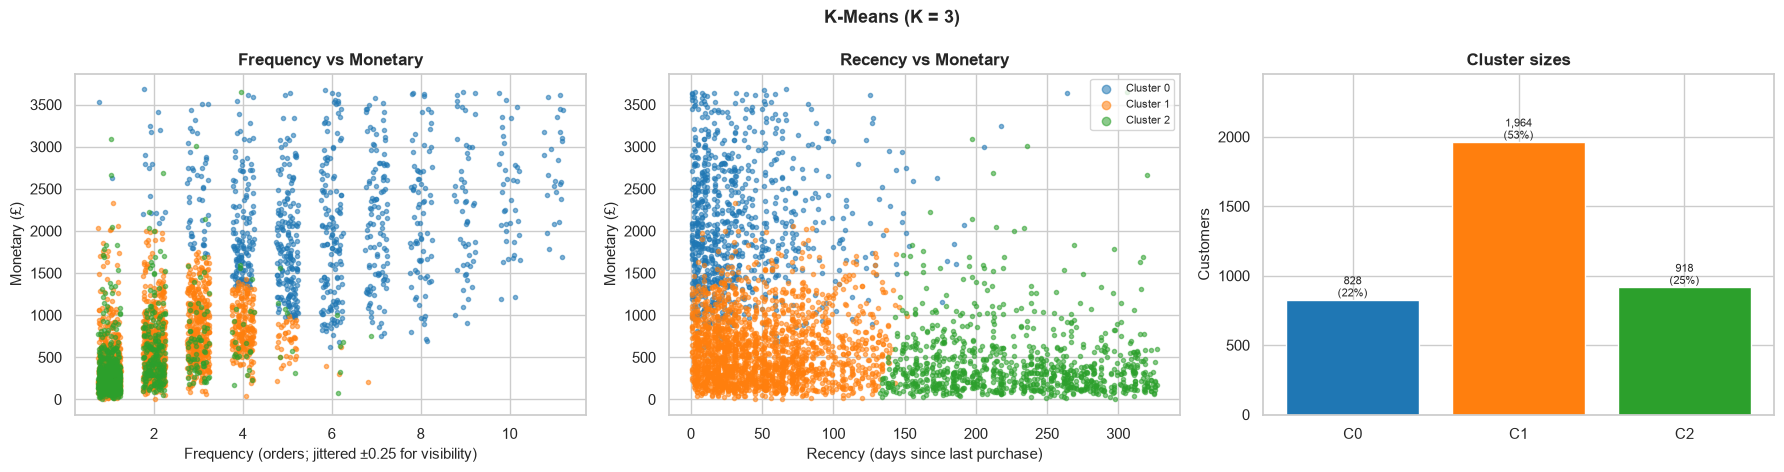

In [21]:
# =====================================================================
# 12.3  FINAL K-MEANS MODEL WITH THE SELECTED K
# =====================================================================
kmeans_model, kmeans_raw_labels = run_kmeans(X_rfm, k_kmeans, init="random")
kmeans_labels = relabel_by_monetary(kmeans_raw_labels, rfm_clean["Monetary"])
register_result("K-Means", kmeans_labels, f"K = {k_kmeans}, init='random', n_init=10",
                "KMeans_Cluster", kmeans_model, kmeans_sweep)

banner(f"K-Means result (K = {k_kmeans})")
display(cluster_size_table(kmeans_labels))
compare_with_paper("K-Means", kmeans_sweep)
plot_cluster_views(rfm_clean, kmeans_labels, f"K-Means (K = {k_kmeans})", "fig_12_kmeans_clusters")


K-Means++ (init='k-means++', n_init=10): K = 2 … 10


,K,Inertia (WCSS),Number of Clusters,Silhouette Score,Davies-Bouldin Index,Cluster sizes (largest → smallest)
0,2,373.0354,2,0.4020,0.9964,2602 / 1108
1,3,190.5565,3,0.4787,0.7591,1964 / 918 / 828
2,4,152.4562,4,0.4076,0.9162,1474 / 893 / 879 / 464
3,5,128.9021,5,0.3808,0.9393,1300 / 825 / 607 / 508 / 470
4,6,110.4389,6,0.3725,0.9885,1241 / 736 / 596 / 507 / 350 / 280
5,7,98.9075,7,0.3533,0.9897,1102 / 702 / 583 / 508 / 317 / 288 / 210
6,8,90.2565,8,0.3489,1.0033,1062 / 607 / 499 / 464 / 347 / 288 / 231 / 212
7,9,82.8811,9,0.3196,0.9948,754 / 606 / 544 / 453 / 439 / 284 / 245 / 195 ...
8,10,76.6229,10,0.3205,1.0034,740 / 527 / 441 / 418 / 415 / 315 / 304 / 192 ...


Highest Silhouette Score at K = 3; lowest Davies–Bouldin Index at K = 3.
→ Both metrics point to the same K.
Selected K for K-Means++: 3


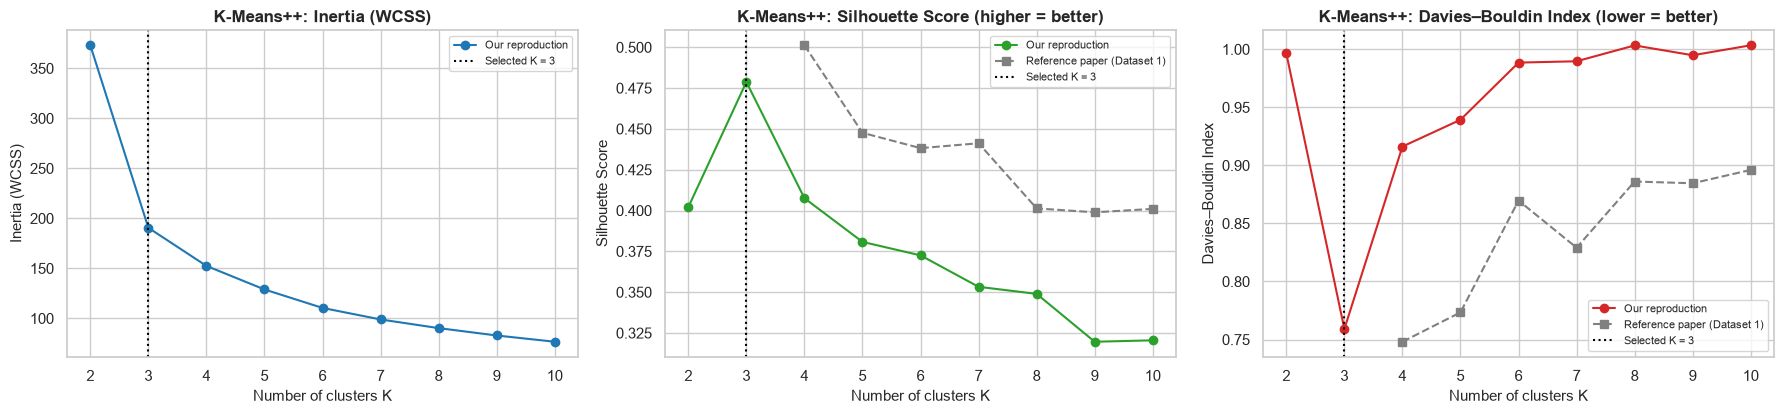


K-Means++ result (K = 3)


,Cluster,Customers,% of Customers
0,0,828,22.32
1,1,1964,52.94
2,2,918,24.74


Reference Paper Result (Dataset 1, Tables 4, 24, 25): K = 4, Silhouette = 0.5012, Davies–Bouldin = 0.7481
Our Reproduction Result: K = 3, Silhouette = 0.4787, Davies–Bouldin = 0.7591
Our result at the paper's K (K = 4): Silhouette = 0.4076, Davies–Bouldin = 0.9162


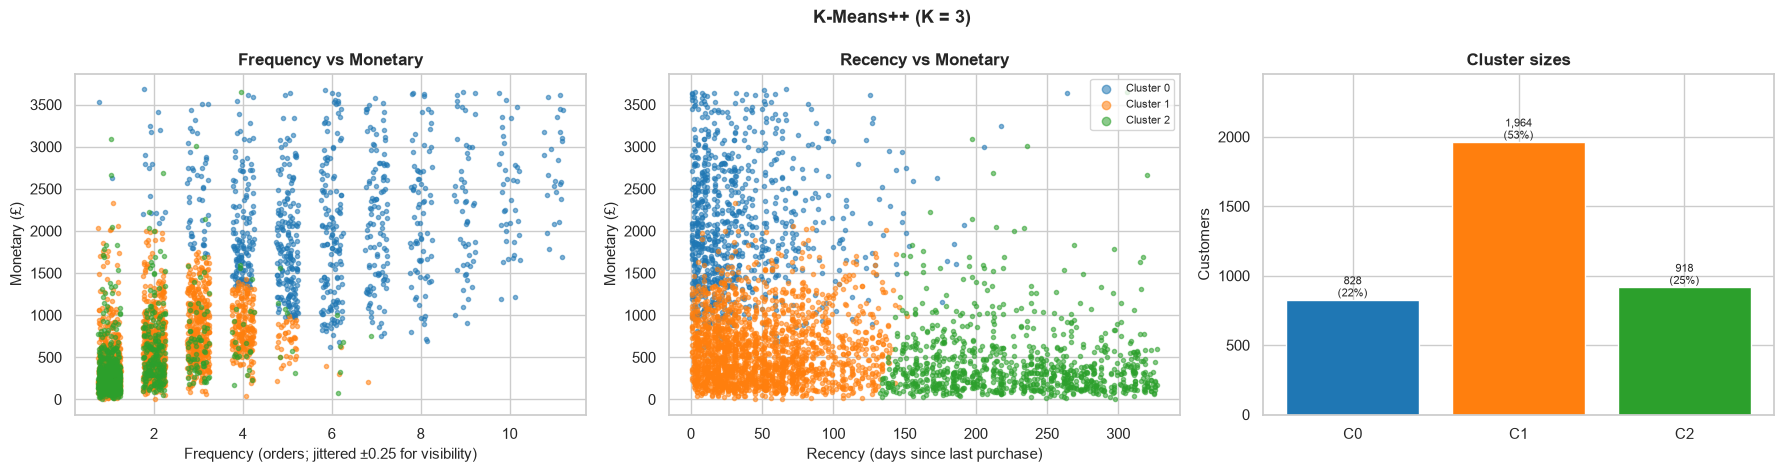

In [22]:
# =====================================================================
# 13.1  K-MEANS++: evaluate K = 2 … 10, choose K, fit the final model
# =====================================================================
banner("K-Means++ (init='k-means++', n_init=10): K = 2 … 10")
kmeanspp_sweep = kmeans_k_sweep(X_rfm, init="k-means++")
display(kmeanspp_sweep.round(4))
k_kmeanspp = select_k(kmeanspp_sweep, "K-Means++")
plot_k_sweep(kmeanspp_sweep, "K-Means++", "Inertia (WCSS)", "Inertia (WCSS)", k_kmeanspp, "fig_13_kmeanspp_k_sweep")

kmeanspp_model, kmeanspp_raw_labels = run_kmeans(X_rfm, k_kmeanspp, init="k-means++")
kmeanspp_labels = relabel_by_monetary(kmeanspp_raw_labels, rfm_clean["Monetary"])
register_result("K-Means++", kmeanspp_labels, f"K = {k_kmeanspp}, init='k-means++', n_init=10",
                "KMeansPlusPlus_Cluster", kmeanspp_model, kmeanspp_sweep)

banner(f"K-Means++ result (K = {k_kmeanspp})")
display(cluster_size_table(kmeanspp_labels))
compare_with_paper("K-Means++", kmeanspp_sweep)
plot_cluster_views(rfm_clean, kmeanspp_labels, f"K-Means++ (K = {k_kmeanspp})", "fig_13_kmeanspp_clusters")

Runs  Runs_Reaching_Best  Mean_Inertia  Std_Inertia  Worst_Inertia  Mean_Silhouette  Std_Silhouette  Mean_Iterations
K Initialisation                                                                                                                      
3 k-means++         20                  20      190.5627       0.0028       190.5652           0.4790          0.0001             7.00
  random            20                  20      190.5607       0.0032       190.5652           0.4788          0.0002             8.85
4 k-means++         20                  18      153.6900       3.7706       164.7154           0.4060          0.0032            10.95
  random            20                   9      159.2040       6.2541       164.7228           0.4009          0.0061            14.90

K = 3: the best solution was reached in 20/20 runs with k-means++ vs 20/20 with random initialisation; mean iterations 7.0 vs 8.8.
K = 4: the best solution was reached in 18/20 runs with k-means++ vs 9/20 with random initialisation; mean iterations 10.9 vs 14.9.


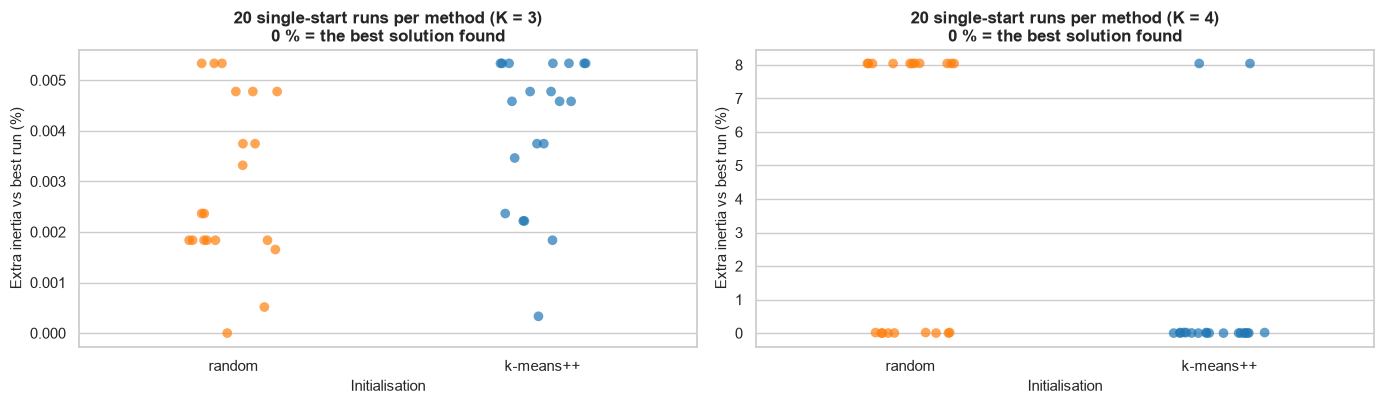

Agreement between the final K-Means and K-Means++ segmentations (Adjusted Rand Index, 1 = identical): 1.0000


In [23]:
# =====================================================================
# 13.2  INITIALISATION STABILITY: random vs k-means++ (one start per run)
# =====================================================================
# With n_init=10, both methods keep their best of 10 starts, so they usually end up identical.
# To see the effect of the INITIALISATION itself, we run each method 20 times with n_init=1 and
# different seeds (42, 43, …, 61) and measure how much the final inertia and silhouette vary.
def initialization_stability(X, k, n_runs=20):
    rows = []
    for init in ["random", "k-means++"]:
        for seed in range(RANDOM_STATE, RANDOM_STATE + n_runs):
            model = KMeans(n_clusters=k, init=init, n_init=1, random_state=seed).fit(X)
            rows.append({"K": k, "Initialisation": init, "Seed": seed, "Inertia": model.inertia_,
                         "Silhouette": silhouette_score(X, model.labels_), "Iterations": model.n_iter_})
    return pd.DataFrame(rows)

paper_k_kmeanspp = int(PAPER_CLUSTERING.set_index("Model").loc["K-Means++", "Paper K"])
stability_ks = sorted({k_kmeanspp, paper_k_kmeanspp})            # our K and the paper's K
stability_runs = pd.concat([initialization_stability(X_rfm, k) for k in stability_ks], ignore_index=True)
best_inertia = stability_runs.groupby("K")["Inertia"].transform("min")           # best of all 40 runs for this K
stability_runs["Extra inertia vs best run (%)"] = 100 * (stability_runs["Inertia"] / best_inertia - 1)
stability_runs["Reached best solution"] = stability_runs["Extra inertia vs best run (%)"] < 0.05   # within 0.05 %
stability_summary = (stability_runs.groupby(["K", "Initialisation"])
                     .agg(Runs=("Seed", "size"),
                          Runs_Reaching_Best=("Reached best solution", "sum"),
                          Mean_Inertia=("Inertia", "mean"), Std_Inertia=("Inertia", "std"),
                          Worst_Inertia=("Inertia", "max"),
                          Mean_Silhouette=("Silhouette", "mean"), Std_Silhouette=("Silhouette", "std"),
                          Mean_Iterations=("Iterations", "mean")))
display(stability_summary.round(4))
for k in stability_ks:
    rnd, kpp = stability_summary.loc[(k, "random")], stability_summary.loc[(k, "k-means++")]
    print(f"K = {k}: the best solution was reached in {int(kpp['Runs_Reaching_Best'])}/{int(kpp['Runs'])} runs with "
          f"k-means++ vs {int(rnd['Runs_Reaching_Best'])}/{int(rnd['Runs'])} with random initialisation; "
          f"mean iterations {kpp['Mean_Iterations']:.1f} vs {rnd['Mean_Iterations']:.1f}.")

fig, axes = plt.subplots(1, len(stability_ks), figsize=(7 * len(stability_ks), 4.2), squeeze=False)
for ax, k in zip(axes[0], stability_ks):
    subset = stability_runs[stability_runs["K"] == k]
    sns.stripplot(data=subset, x="Initialisation", y="Extra inertia vs best run (%)", ax=ax, size=7, alpha=0.7,
                  jitter=0.15, hue="Initialisation", palette={"random": "#ff7f0e", "k-means++": "#1f77b4"},
                  legend=False)
    ax.set_title(f"20 single-start runs per method (K = {k})\n0 % = the best solution found")
fig.tight_layout()
save_fig(fig, "fig_13_init_stability")

agreement = adjusted_rand_score(cluster_results["K-Means"]["labels"], cluster_results["K-Means++"]["labels"])
print(f"Agreement between the final K-Means and K-Means++ segmentations (Adjusted Rand Index, 1 = identical): {agreement:.4f}")

In [24]:
# =====================================================================
# 14.1  K-MEDOIDS (PAM) IMPLEMENTATION + BACKEND SELECTION
# =====================================================================
class SimpleKMedoids:
    """K-Medoids with the classic PAM algorithm (BUILD + SWAP) on a precomputed distance matrix.
    Mirrors sklearn_extra.cluster.KMedoids(method="pam", init="build"). Deterministic (no randomness)."""

    def __init__(self, n_clusters, max_iter=300):
        self.n_clusters = n_clusters
        self.max_iter = max_iter

    def fit(self, distance_matrix):
        D = np.asarray(distance_matrix, dtype=float)
        medoids = self._build(D)
        self.medoid_indices_, self.n_iter_ = self._swap(D, medoids)
        self.labels_ = np.argmin(D[self.medoid_indices_], axis=0)      # nearest medoid for every customer
        self.inertia_ = D[self.medoid_indices_].min(axis=0).sum()      # total distance to the nearest medoid
        return self

    def _build(self, D, block=1024):
        """BUILD: greedy choice of the starting medoids."""
        n = D.shape[0]
        medoids = [int(np.argmin(D.sum(axis=0)))]           # 1st medoid: the most central customer
        nearest = D[medoids[0]].copy()                      # each customer's distance to its closest medoid
        for _ in range(1, self.n_clusters):
            gain = np.zeros(n)                              # total distance saved if customer c became a medoid
            for start in range(0, n, block):                # work in blocks to save memory
                gain[start:start + block] = np.maximum(nearest - D[start:start + block], 0).sum(axis=1)
            gain[medoids] = -np.inf                         # an existing medoid cannot be chosen again
            best = n - 1 - int(np.argmax(gain[::-1]))       # ties → last index (same as scikit-learn-extra)
            medoids.append(best)
            nearest = np.minimum(nearest, D[best])
        return np.array(medoids)

    def _swap(self, D, medoids, block=1024):
        """SWAP: repeatedly apply the (medoid, non-medoid) swap that lowers the total distance the most."""
        n, k = D.shape[0], len(medoids)
        medoids = medoids.copy()
        for iteration in range(1, self.max_iter + 1):
            dist_to_medoids = D[medoids]                                 # shape (k, n)
            order = np.argsort(dist_to_medoids, axis=0)
            d1 = dist_to_medoids[order[0], np.arange(n)]                 # distance to the nearest medoid
            d2 = dist_to_medoids[order[1], np.arange(n)]                 # distance to the 2nd-nearest medoid
            served_by = np.eye(k)[order[0]]                              # one-hot: which medoid serves each customer
            change = np.empty((n, k))                                    # change[h, i]: replace medoid i by customer h
            for start in range(0, n, block):
                Dh = D[start:start + block]                              # distances from candidates h to everyone
                moves_to_h = np.minimum(Dh - d1, 0).sum(axis=1)          # customers for whom h is closer: cost falls
                lost_medoid = np.where(Dh >= d1, np.minimum(Dh, d2) - d1, 0) @ served_by   # customers of medoid i move away
                change[start:start + block] = moves_to_h[:, None] + lost_medoid
            change[medoids, :] = np.inf                                  # a medoid cannot replace a medoid
            h, i = np.unravel_index(np.argmin(change), change.shape)
            if change[h, i] >= -1e-12:                                   # no swap improves the total distance → stop
                return medoids, iteration
            medoids[i] = h
        return medoids, self.max_iter

KMEDOIDS_BACKEND = "scikit-learn-extra" if SKLEARN_EXTRA_AVAILABLE else "built-in PAM (SimpleKMedoids)"

def run_kmedoids(n_clusters, distance_matrix):
    """K-Medoids (PAM, BUILD initialisation) on a precomputed Euclidean distance matrix → (model, labels)."""
    global KMEDOIDS_BACKEND
    if KMEDOIDS_BACKEND == "scikit-learn-extra":
        try:
            model = SklearnExtraKMedoids(n_clusters=n_clusters, metric="precomputed", method="pam", init="build",
                                         max_iter=300, random_state=RANDOM_STATE).fit(distance_matrix)
            return model, np.asarray(model.labels_)
        except Exception as error:                   # e.g. an incompatible scikit-learn version
            print(f"scikit-learn-extra failed ({type(error).__name__}); switching to the built-in PAM implementation.")
            KMEDOIDS_BACKEND = "built-in PAM (SimpleKMedoids)"
    model = SimpleKMedoids(n_clusters=n_clusters).fit(distance_matrix)
    return model, model.labels_

print("K-Medoids backend:", KMEDOIDS_BACKEND)

K-Medoids backend: built-in PAM (SimpleKMedoids)


Euclidean distance matrix: 3,710 × 3,710 (110 MB)

K-Medoids (PAM, backend: built-in PAM (SimpleKMedoids)): K = 2 … 10


  K =  2: cost =   1004.55 | Silhouette = 0.4291 | Davies–Bouldin = 0.8303 |   1.2 s


  K =  3: cost =    752.78 | Silhouette = 0.4775 | Davies–Bouldin = 0.7621 |   1.7 s


  K =  4: cost =    683.37 | Silhouette = 0.3947 | Davies–Bouldin = 0.8990 |   3.3 s


  K =  5: cost =    610.41 | Silhouette = 0.3705 | Davies–Bouldin = 0.9211 |   3.9 s


...

  K =  8: cost =    513.97 | Silhouette = 0.2913 | Davies–Bouldin = 1.0860 |   4.3 s


  K =  9: cost =    497.55 | Silhouette = 0.2638 | Davies–Bouldin = 1.1409 |   5.3 s


  K = 10: cost =    474.88 | Silhouette = 0.2713 | Davies–Bouldin = 1.0787 |   5.5 s


,K,Total distance to medoids (cost),Number of Clusters,Silhouette Score,Davies-Bouldin Index,Cluster sizes (largest → smallest)
0,2,1004.5463,2,0.4291,0.8303,2750 / 960
1,3,752.7771,3,0.4775,0.7621,1943 / 918 / 849
2,4,683.3664,4,0.3947,0.8990,1677 / 844 / 653 / 536
3,5,610.4088,5,0.3705,0.9211,1144 / 919 / 610 / 520 / 517
4,6,570.3807,6,0.2852,1.0793,764 / 750 / 640 / 569 / 496 / 491
5,7,538.4743,7,0.2902,1.1235,734 / 632 / 627 / 555 / 489 / 348 / 325
6,8,513.9680,8,0.2913,1.0860,598 / 532 / 514 / 498 / 482 / 404 / 403 / 279
7,9,497.5480,9,0.2638,1.1409,609 / 514 / 507 / 403 / 401 / 385 / 308 / 304 ...
8,10,474.8799,10,0.2713,1.0787,609 / 507 / 463 / 400 / 373 / 316 / 308 / 304 ...


Highest Silhouette Score at K = 3; lowest Davies–Bouldin Index at K = 3.
→ Both metrics point to the same K.
Selected K for K-Medoids: 3


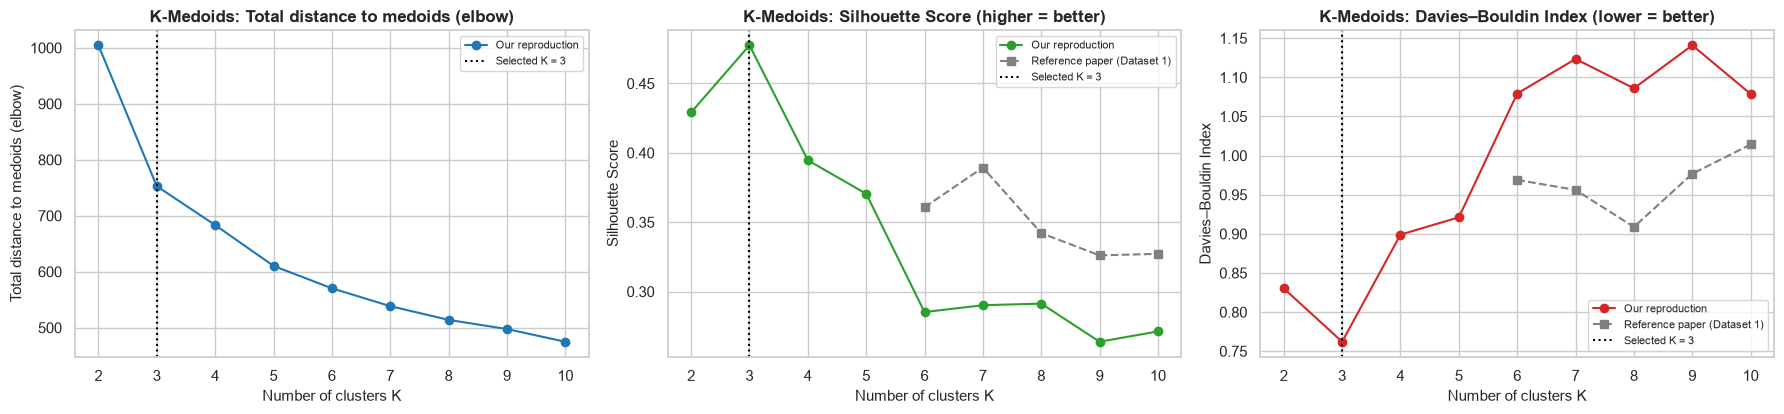

In [25]:
# =====================================================================
# 14.2  K-MEDOIDS: evaluate K = 2 … 10 (with progress messages)
# =====================================================================
distance_matrix = pairwise_distances(X_rfm, metric="euclidean")      # computed once, reused for every K
print(f"Euclidean distance matrix: {distance_matrix.shape[0]:,} × {distance_matrix.shape[1]:,} "
      f"({distance_matrix.nbytes / 1e6:.0f} MB)")

banner(f"K-Medoids (PAM, backend: {KMEDOIDS_BACKEND}): K = 2 … 10")
kmedoids_rows = []
for k in K_RANGE:
    start = time.time()
    model, labels = run_kmedoids(k, distance_matrix)
    scores = evaluate_clusters(X_rfm, labels)
    kmedoids_rows.append({"K": k, "Total distance to medoids (cost)": model.inertia_, **scores,
                          "Cluster sizes (largest → smallest)": cluster_sizes_text(labels)})
    print(f"  K = {k:>2}: cost = {model.inertia_:9.2f} | Silhouette = {scores['Silhouette Score']:.4f} | "
          f"Davies–Bouldin = {scores['Davies-Bouldin Index']:.4f} | {time.time() - start:5.1f} s")
kmedoids_sweep = pd.DataFrame(kmedoids_rows)
display(kmedoids_sweep.round(4))

k_kmedoids = select_k(kmedoids_sweep, "K-Medoids")
plot_k_sweep(kmedoids_sweep, "K-Medoids", "Total distance to medoids (cost)", "Total distance to medoids (elbow)",
             k_kmedoids, "fig_14_kmedoids_k_sweep")


K-Medoids result (K = 3)


,Cluster,Customers,% of Customers
0,0,849,22.88
1,1,1943,52.37
2,2,918,24.74


Medoids = real customers that represent each cluster (original units):


,Cluster,CustomerID,Recency,Frequency,Monetary
0,0,14188,31,6,2054.36
1,1,15068,46,2,553.36
2,2,16823,227,1,358.38


Reference Paper Result (Dataset 1, Tables 5, 24, 27): K = 7, Silhouette = 0.3894, Davies–Bouldin = 0.9561
Our Reproduction Result: K = 3, Silhouette = 0.4775, Davies–Bouldin = 0.7621
Our result at the paper's K (K = 7): Silhouette = 0.2902, Davies–Bouldin = 1.1235


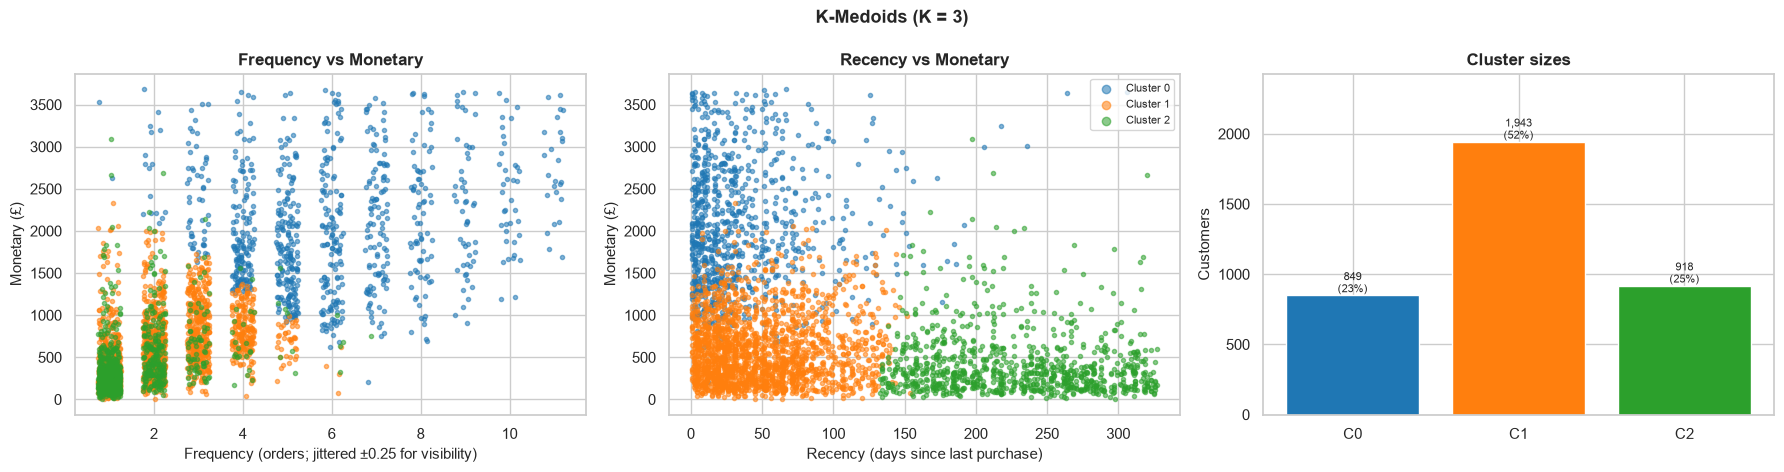

In [26]:
# =====================================================================
# 14.3  FINAL K-MEDOIDS MODEL + THE MEDOID CUSTOMERS
# =====================================================================
kmedoids_model, kmedoids_raw_labels = run_kmedoids(k_kmedoids, distance_matrix)
kmedoids_mapping = monetary_order_mapping(kmedoids_raw_labels, rfm_clean["Monetary"])
kmedoids_labels = pd.Series(kmedoids_raw_labels).map(kmedoids_mapping).to_numpy()
register_result("K-Medoids", kmedoids_labels, f"K = {k_kmedoids}, PAM (BUILD + SWAP), backend: {KMEDOIDS_BACKEND}",
                "KMedoids_Cluster", kmedoids_model, kmedoids_sweep)

banner(f"K-Medoids result (K = {k_kmedoids})")
display(cluster_size_table(kmedoids_labels))

medoid_idx = np.asarray(kmedoids_model.medoid_indices_)
medoid_table = rfm_clean.loc[medoid_idx, ["CustomerID"] + RFM_COLS].copy()
medoid_table.insert(0, "Cluster", [kmedoids_mapping[kmedoids_raw_labels[i]] for i in medoid_idx])
print("Medoids = real customers that represent each cluster (original units):")
display(medoid_table.sort_values("Cluster").reset_index(drop=True).round(2))

compare_with_paper("K-Medoids", kmedoids_sweep)
plot_cluster_views(rfm_clean, kmedoids_labels, f"K-Medoids (K = {k_kmedoids})", "fig_14_kmedoids_clusters")

In [27]:
# =====================================================================
# 14.4  CONSISTENCY CHECK: built-in PAM vs scikit-learn-extra (only if scikit-learn-extra works here)
# =====================================================================
if KMEDOIDS_BACKEND == "scikit-learn-extra":
    ours = SimpleKMedoids(n_clusters=k_kmedoids).fit(distance_matrix)
    same_medoids = set(ours.medoid_indices_.tolist()) == set(np.asarray(kmedoids_model.medoid_indices_).tolist())
    ari = adjusted_rand_score(ours.labels_, kmedoids_raw_labels)
    print(f"Built-in PAM vs scikit-learn-extra at K = {k_kmedoids}: same medoids = {same_medoids}, "
          f"ARI = {ari:.4f}, cost = {ours.inertia_:.4f} vs {kmedoids_model.inertia_:.4f}")
else:
    print("scikit-learn-extra is not usable in this runtime, so this comparison is skipped.")
    print("All K-Medoids results above come from the built-in PAM implementation (BUILD + SWAP, Euclidean distance).")

scikit-learn-extra is not usable in this runtime, so this comparison is skipped.
All K-Medoids results above come from the built-in PAM implementation (BUILD + SWAP, Euclidean distance).



Gaussian Mixture Model: n_components = 2 … 10


,K,BIC (information only),Number of Clusters,Silhouette Score,Davies-Bouldin Index,Cluster sizes (largest → smallest)
0,2,-8783.9635,2,0.3222,1.1990,2034 / 1676
1,3,-10394.5479,3,0.2094,1.2767,1331 / 1209 / 1170
2,4,-11269.1080,4,0.3294,1.1936,1218 / 1041 / 801 / 650
3,5,-11718.7828,5,0.2609,1.2945,872 / 843 / 836 / 660 / 499
4,6,-28723.7451,6,0.0402,2.3791,1313 / 796 / 494 / 475 / 345 / 287
5,7,-31130.2821,7,0.0356,2.5288,1314 / 804 / 489 / 364 / 346 / 211 / 182
6,8,-31111.7094,8,0.0238,2.3188,1312 / 800 / 483 / 364 / 320 / 186 / 146 / 99
7,9,-31222.8738,9,0.0176,2.6987,1313 / 800 / 483 / 364 / 227 / 196 / 182 / 81 ...
8,10,-31654.4266,10,-0.0543,2.5407,1310 / 483 / 412 / 397 / 362 / 269 / 223 / 165...


BIC (Bayesian Information Criterion) is GMM's own model-fit measure (lower = better fit). It is shown for
information only: like the paper, we choose K with the Silhouette Score / Davies–Bouldin Index.
Highest Silhouette Score at K = 4; lowest Davies–Bouldin Index at K = 4.
→ Both metrics point to the same K.
Selected K for GMM: 4


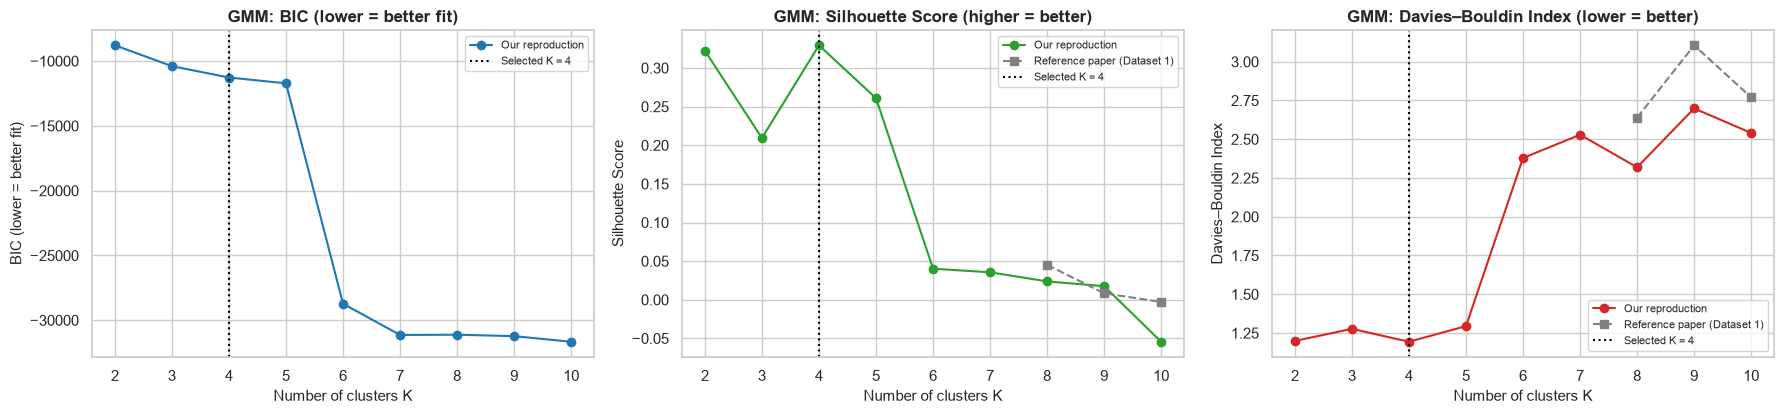


GMM result (K = 4)


,Cluster,Customers,% of Customers
0,0,1041,28.06
1,1,650,17.52
2,2,1218,32.83
3,3,801,21.59


Reference Paper Result (Dataset 1, Tables 6, 24): K = 8, Silhouette = 0.0452, Davies–Bouldin = 2.6394
Our Reproduction Result: K = 4, Silhouette = 0.3294, Davies–Bouldin = 1.1936
Our result at the paper's K (K = 8): Silhouette = 0.0238, Davies–Bouldin = 2.3188


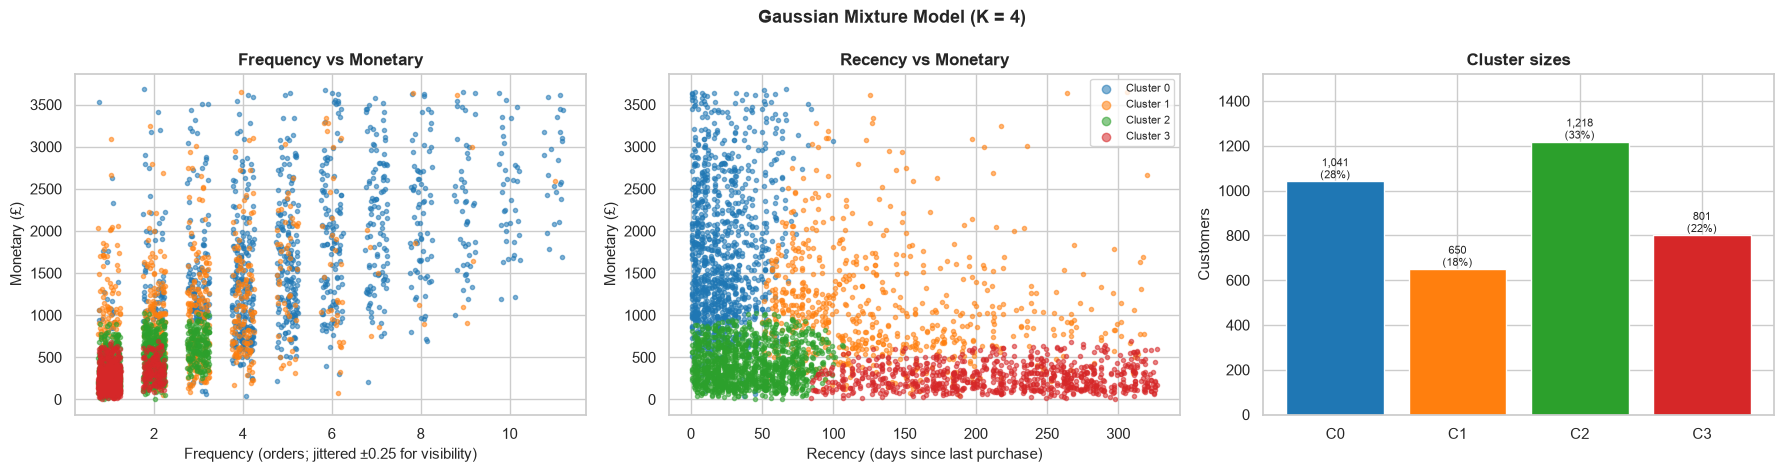

In [28]:
# =====================================================================
# 15.1  GMM: evaluate n_components = 2 … 10, choose K, fit the final model
# =====================================================================
def run_gmm(X, n_components, random_state=RANDOM_STATE):
    """Fit a Gaussian Mixture Model and return (model, most-probable component for each customer)."""
    model = GaussianMixture(n_components=n_components, covariance_type="full", random_state=random_state)
    return model, model.fit_predict(X)

banner("Gaussian Mixture Model: n_components = 2 … 10")
gmm_rows = []
for k in K_RANGE:
    model, labels = run_gmm(X_rfm, k)
    gmm_rows.append({"K": k, "BIC (information only)": model.bic(X_rfm), **evaluate_clusters(X_rfm, labels),
                     "Cluster sizes (largest → smallest)": cluster_sizes_text(labels)})
gmm_sweep = pd.DataFrame(gmm_rows)
display(gmm_sweep.round(4))
print("BIC (Bayesian Information Criterion) is GMM's own model-fit measure (lower = better fit). It is shown for")
print("information only: like the paper, we choose K with the Silhouette Score / Davies–Bouldin Index.")

k_gmm = select_k(gmm_sweep, "GMM")
plot_k_sweep(gmm_sweep, "GMM", "BIC (information only)", "BIC (lower = better fit)", k_gmm, "fig_15_gmm_k_sweep")

gmm_model, gmm_raw_labels = run_gmm(X_rfm, k_gmm)
gmm_labels = relabel_by_monetary(gmm_raw_labels, rfm_clean["Monetary"])
register_result("GMM", gmm_labels, f"K = {k_gmm}, covariance='full'", "GMM_Cluster", gmm_model, gmm_sweep)

banner(f"GMM result (K = {k_gmm})")
display(cluster_size_table(gmm_labels))
compare_with_paper("GMM", gmm_sweep)
plot_cluster_views(rfm_clean, gmm_labels, f"Gaussian Mixture Model (K = {k_gmm})", "fig_15_gmm_clusters")

In [29]:
# =====================================================================
# 15.2  DIAGNOSTIC: why does GMM's Silhouette collapse at larger K? (checked at the paper's K)
# =====================================================================
paper_k_gmm = int(PAPER_CLUSTERING.set_index("Model").loc["GMM", "Paper K"])
diag_model, diag_labels = run_gmm(X_rfm, paper_k_gmm)
frequency_std = np.sqrt(diag_model.covariances_[:, 1, 1])        # spread of scaled Frequency in each component
diagnostic = pd.DataFrame({
    "Component": range(paper_k_gmm),
    "Customers": [int((diag_labels == c).sum()) for c in range(paper_k_gmm)],
    "Distinct Frequency values": [rfm_clean.loc[diag_labels == c, "Frequency"].nunique() for c in range(paper_k_gmm)],
    "Frequency range": [f"{rfm_clean.loc[diag_labels == c, 'Frequency'].min()}–{rfm_clean.loc[diag_labels == c, 'Frequency'].max()}"
                        if (diag_labels == c).any() else "empty" for c in range(paper_k_gmm)],
    "Std of scaled Frequency": frequency_std.round(4),
})
display(diagnostic)
single_value = int((diagnostic["Distinct Frequency values"] == 1).sum())
diag_scores = evaluate_clusters(X_rfm, diag_labels)
print(f"At K = {paper_k_gmm}: {single_value} of {paper_k_gmm} components contain customers with exactly ONE Frequency value,")
print("with an almost-zero spread along the Frequency axis. Frequency is a whole number (1, 2, 3, …), so a")
print("'full' Gaussian can fit a very narrow 'slice' at one Frequency value. That raises the likelihood (better BIC),")
print("but these slices overlap in Recency/Monetary, so the clusters are not geometrically separated:")
print(f"our Silhouette at K = {paper_k_gmm} is {diag_scores['Silhouette Score']:.4f} "
      f"(Reference Paper Result at K = 8: {PAPER_K_TABLES['GMM'][8][0]:.4f}).")

,Component,Customers,Distinct Frequency values,Frequency range,Std of scaled Frequency
0,0,364,1,4–4,0.0010
1,1,1312,1,1–1,0.0010
2,2,99,10,1–11,0.2414
3,3,146,7,5–11,0.1509
4,4,483,1,3–3,0.0010
5,5,320,10,1–11,0.2470
6,6,800,1,2–2,0.0010
7,7,186,2,5–6,0.0482


At K = 8: 4 of 8 components contain customers with exactly ONE Frequency value,
with an almost-zero spread along the Frequency axis. Frequency is a whole number (1, 2, 3, …), so a
'full' Gaussian can fit a very narrow 'slice' at one Frequency value. That raises the likelihood (better BIC),
but these slices overlap in Recency/Monetary, so the clusters are not geometrically separated:
our Silhouette at K = 8 is 0.0238 (Reference Paper Result at K = 8: 0.0452).



Mean Shift: bandwidth search


  quantile = 0.05 | bandwidth = 0.1495 | clusters = 25 |  9.2 s


  quantile = 0.10 | bandwidth = 0.2014 | clusters = 10 |  1.5 s


  quantile = 0.15 | bandwidth = 0.2452 | clusters =  6 |  1.6 s


  quantile = 0.20 | bandwidth = 0.2855 | clusters =  4 |  1.6 s


  quantile = 0.25 | bandwidth = 0.3258 | clusters =  2 |  1.7 s


  quantile = 0.30 | bandwidth = 0.3637 | clusters =  1 |  1.6 s  ← only ONE cluster: Silhouette/DBI undefined


,Quantile,Bandwidth,Number of Clusters,Silhouette Score,Davies-Bouldin Index,Largest cluster (%),Smallest cluster (customers),Cluster sizes (largest → smallest)
0,0.05,0.1495,25,0.3159,0.8742,45.9299,1,1704 / 500 / 412 / 394 / 178 / 146 / 70 / 66 /...
1,0.10,0.2014,10,0.2906,0.8903,55.3369,1,2053 / 591 / 537 / 223 / 171 / 115 / 13 / 5 / ...
2,0.15,0.2452,6,0.4003,1.3230,64.5553,10,2395 / 933 / 337 / 18 / 17 / 10
3,0.20,0.2855,4,0.4243,0.9320,64.0701,29,2377 / 967 / 337 / 29
4,0.25,0.3258,2,0.4246,0.8706,72.4798,1021,2689 / 1021
5,0.30,0.3637,1,NaN,NaN,100.0000,3710,3710


Highest Silhouette: quantile 0.25 (2 clusters); lowest Davies–Bouldin: quantile 0.25 (2 clusters).
Selected Mean Shift setting: quantile = 0.25, bandwidth = 0.3258


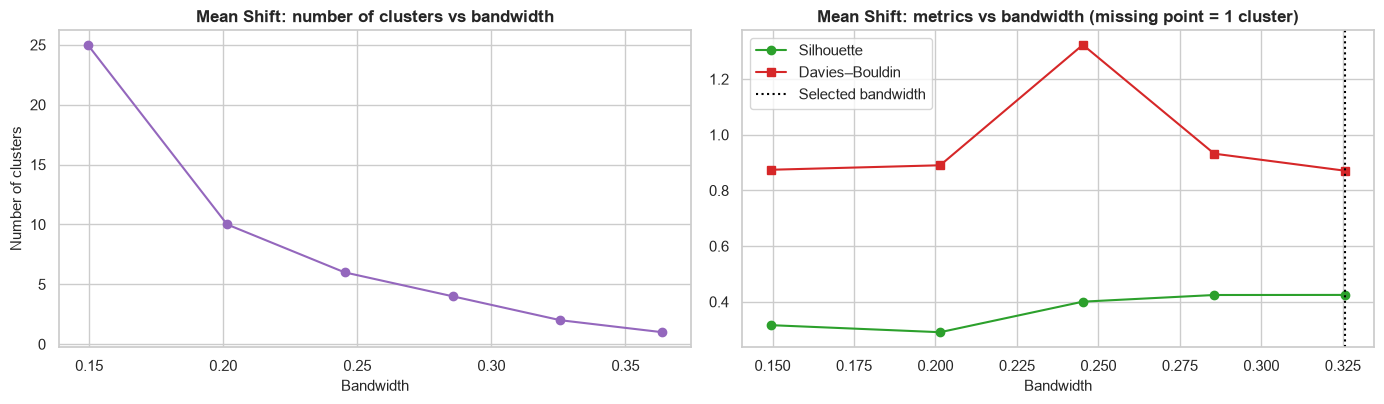


Mean Shift result (2 clusters)


,Cluster,Customers,% of Customers
0,0,2689,72.48
1,1,1021,27.52


Reference Paper Result (Dataset 1, Tables 7, 24): K = 5, Silhouette = 0.4027, Davies–Bouldin = 1.3553
Our Reproduction Result: K = 2, Silhouette = 0.4246, Davies–Bouldin = 0.8706
Our setting with the cluster count closest to the paper's 5: quantile 0.15 → 6 clusters, Silhouette = 0.4003, Davies–Bouldin = 1.3230


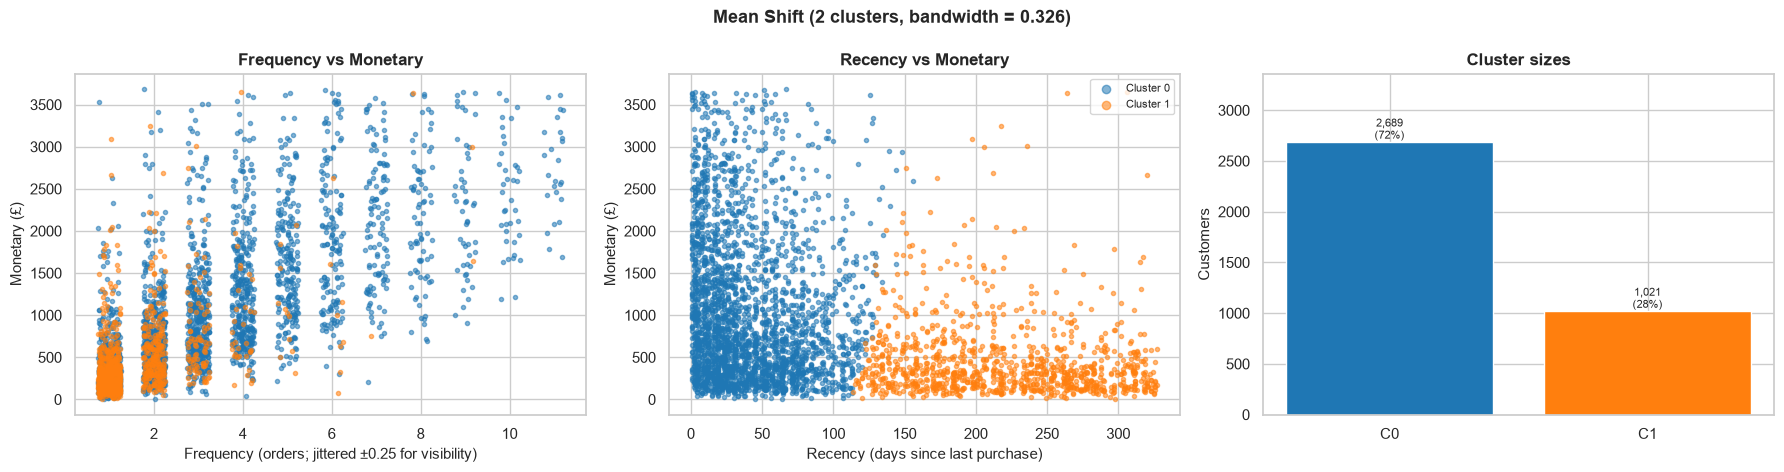

In [30]:
# =====================================================================
# 16.1  MEAN SHIFT: small bandwidth search, choose a setting, fit the final model
# =====================================================================
def run_mean_shift(X, quantile, random_state=RANDOM_STATE):
    """Estimate a bandwidth from the given quantile, fit Mean Shift, return (model, labels, bandwidth)."""
    bandwidth = estimate_bandwidth(X, quantile=quantile, random_state=random_state)
    model = MeanShift(bandwidth=bandwidth, bin_seeding=True, n_jobs=-1)
    return model, model.fit_predict(X), bandwidth

banner("Mean Shift: bandwidth search")
meanshift_rows, meanshift_fits = [], {}
for q in MEANSHIFT_QUANTILES:
    start = time.time()
    model, labels, bandwidth = run_mean_shift(X_rfm, q)
    scores = evaluate_clusters(X_rfm, labels)
    sizes = pd.Series(labels).value_counts()
    meanshift_fits[q] = (model, labels, bandwidth)
    meanshift_rows.append({"Quantile": q, "Bandwidth": bandwidth, **scores,
                           "Largest cluster (%)": 100 * sizes.max() / len(labels),
                           "Smallest cluster (customers)": int(sizes.min()),
                           "Cluster sizes (largest → smallest)": cluster_sizes_text(labels)})
    note = "  ← only ONE cluster: Silhouette/DBI undefined" if scores["Number of Clusters"] < 2 else ""
    print(f"  quantile = {q:.2f} | bandwidth = {bandwidth:.4f} | clusters = {scores['Number of Clusters']:>2} | "
          f"{time.time() - start:4.1f} s{note}")
meanshift_search = pd.DataFrame(meanshift_rows)
display(meanshift_search.round(4))

valid_settings = meanshift_search.dropna(subset=["Silhouette Score"])
if valid_settings.empty:
    print("Every bandwidth produced a single cluster; the default-quantile result is kept and the metrics are NaN.")
    chosen_setting = meanshift_search.iloc[-1]
else:
    chosen_setting = valid_settings.loc[valid_settings["Silhouette Score"].idxmax()]
    k_by_dbi = valid_settings.loc[valid_settings["Davies-Bouldin Index"].idxmin()]
    print(f"Highest Silhouette: quantile {chosen_setting['Quantile']:.2f} ({int(chosen_setting['Number of Clusters'])} clusters); "
          f"lowest Davies–Bouldin: quantile {k_by_dbi['Quantile']:.2f} ({int(k_by_dbi['Number of Clusters'])} clusters).")
meanshift_quantile = float(chosen_setting["Quantile"])
meanshift_model, meanshift_raw_labels, meanshift_bandwidth = meanshift_fits[meanshift_quantile]
print(f"Selected Mean Shift setting: quantile = {meanshift_quantile:.2f}, bandwidth = {meanshift_bandwidth:.4f}")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
axes[0].plot(meanshift_search["Bandwidth"], meanshift_search["Number of Clusters"], "o-", color="#9467bd")
axes[0].set_title("Mean Shift: number of clusters vs bandwidth")
axes[0].set_xlabel("Bandwidth")
axes[0].set_ylabel("Number of clusters")
axes[1].plot(meanshift_search["Bandwidth"], meanshift_search["Silhouette Score"], "o-", color="#2ca02c", label="Silhouette")
axes[1].plot(meanshift_search["Bandwidth"], meanshift_search["Davies-Bouldin Index"], "s-", color="#d62728", label="Davies–Bouldin")
axes[1].axvline(meanshift_bandwidth, color="black", linestyle=":", label="Selected bandwidth")
axes[1].set_title("Mean Shift: metrics vs bandwidth (missing point = 1 cluster)")
axes[1].set_xlabel("Bandwidth")
axes[1].legend()
fig.tight_layout()
save_fig(fig, "fig_16_meanshift_bandwidth")

meanshift_labels = relabel_by_monetary(meanshift_raw_labels, rfm_clean["Monetary"])
register_result("Mean Shift", meanshift_labels,
                f"bandwidth = {meanshift_bandwidth:.4f} (quantile {meanshift_quantile:.2f}), bin_seeding=True",
                "MeanShift_Cluster", meanshift_model, meanshift_search)

banner(f"Mean Shift result ({cluster_results['Mean Shift']['Number of Clusters']} clusters)")
display(cluster_size_table(meanshift_labels))
compare_with_paper("Mean Shift")
paper_ms_k = int(PAPER_CLUSTERING.set_index("Model").loc["Mean Shift", "Paper K"])
closest = meanshift_search.iloc[(meanshift_search["Number of Clusters"] - paper_ms_k).abs().argmin()]
print(f"Our setting with the cluster count closest to the paper's {paper_ms_k}: quantile {closest['Quantile']:.2f} → "
      f"{int(closest['Number of Clusters'])} clusters, Silhouette = {closest['Silhouette Score']:.4f}, "
      f"Davies–Bouldin = {closest['Davies-Bouldin Index']:.4f}")
plot_cluster_views(rfm_clean, meanshift_labels,
                   f"Mean Shift ({cluster_results['Mean Shift']['Number of Clusters']} clusters, bandwidth = {meanshift_bandwidth:.3f})",
                   "fig_16_meanshift_clusters")


Clustering comparison (Our Reproduction Results)


,Model,Number of Clusters,Silhouette Score,Davies-Bouldin Index,Number of Customers,Smallest Cluster,Largest Cluster (%),Setting
0,K-Means,3,0.4787,0.7591,3710,828,52.9380,"K = 3, init='random', n_init=10"
1,K-Means++,3,0.4787,0.7591,3710,828,52.9380,"K = 3, init='k-means++', n_init=10"
2,K-Medoids,3,0.4775,0.7621,3710,849,52.3720,"K = 3, PAM (BUILD + SWAP), backend: built-in P..."
3,GMM,4,0.3294,1.1936,3710,650,32.8302,"K = 4, covariance='full'"
4,Mean Shift,2,0.4246,0.8706,3710,1021,72.4798,"bandwidth = 0.3258 (quantile 0.25), bin_seedin..."


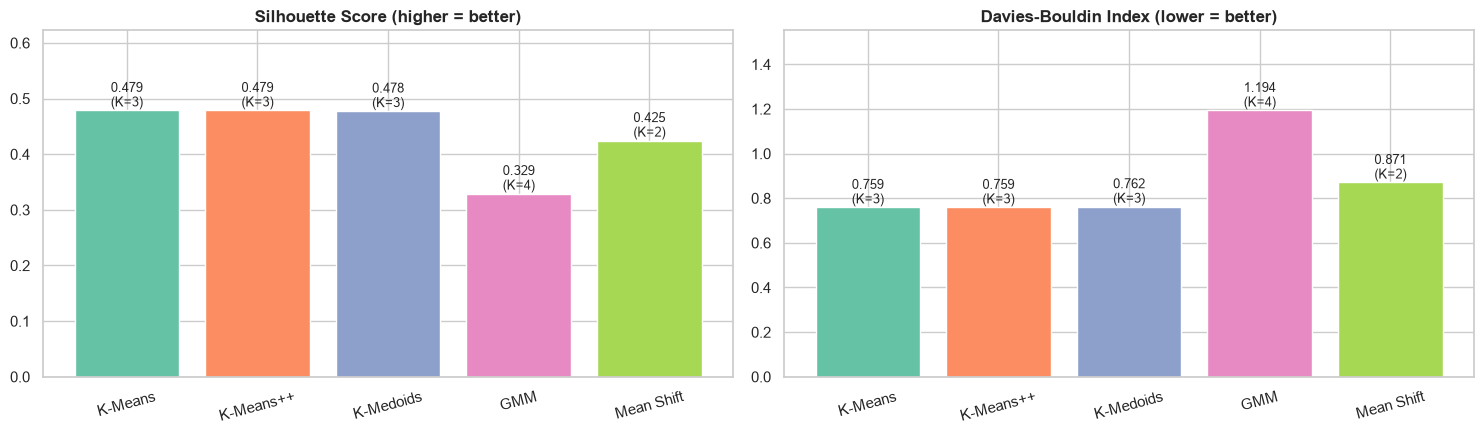

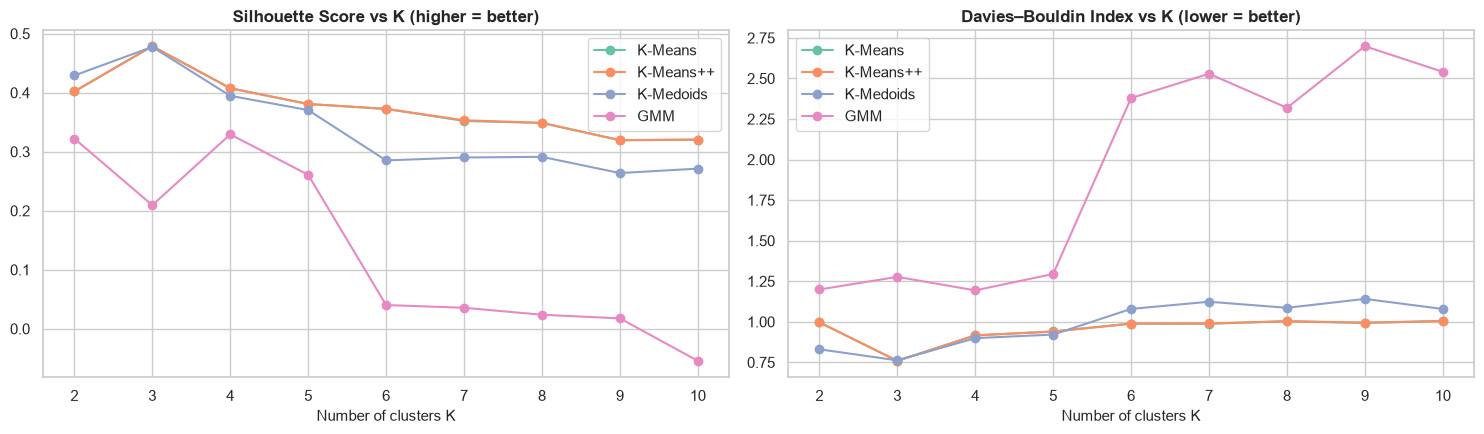

In [31]:
# =====================================================================
# 17.1  MASTER COMPARISON TABLE
# =====================================================================
MODEL_ORDER = ["K-Means", "K-Means++", "K-Medoids", "GMM", "Mean Shift"]
comparison_rows = []
for name in MODEL_ORDER:
    result = cluster_results[name]
    sizes = pd.Series(result["labels"]).value_counts()
    comparison_rows.append({
        "Model": name,
        "Number of Clusters": result["Number of Clusters"],
        "Silhouette Score": result["Silhouette Score"],
        "Davies-Bouldin Index": result["Davies-Bouldin Index"],
        "Number of Customers": len(result["labels"]),
        "Smallest Cluster": int(sizes.min()),
        "Largest Cluster (%)": 100 * sizes.max() / len(result["labels"]),
        "Setting": result["setting"],
    })
clustering_comparison = pd.DataFrame(comparison_rows)
banner("Clustering comparison (Our Reproduction Results)")
display(clustering_comparison.round(4))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
bar_colors = sns.color_palette("Set2", len(MODEL_ORDER))
for ax, metric, note in [(axes[0], "Silhouette Score", "higher = better"),
                         (axes[1], "Davies-Bouldin Index", "lower = better")]:
    values = clustering_comparison[metric]
    bars = ax.bar(clustering_comparison["Model"], values, color=bar_colors)
    for bar, v, k in zip(bars, values, clustering_comparison["Number of Clusters"]):
        ax.annotate("n/a" if pd.isna(v) else f"{v:.3f}\n(K={k})", (bar.get_x() + bar.get_width() / 2, 0 if pd.isna(v) else v),
                    ha="center", va="bottom", fontsize=9)
    ax.set_title(f"{metric} ({note})")
    ax.set_ylim(0, np.nanmax(values) * 1.3)
    ax.tick_params(axis="x", rotation=15)
fig.tight_layout()
save_fig(fig, "fig_17_metric_comparison")

# How the metrics change with K for the four K-based algorithms
fig, axes = plt.subplots(1, 2, figsize=(15, 4.5))
for name, color in zip(["K-Means", "K-Means++", "K-Medoids", "GMM"], bar_colors):
    sweep = cluster_results[name]["sweep"]
    axes[0].plot(sweep["K"], sweep["Silhouette Score"], "o-", color=color, label=name)
    axes[1].plot(sweep["K"], sweep["Davies-Bouldin Index"], "o-", color=color, label=name)
axes[0].set_title("Silhouette Score vs K (higher = better)")
axes[1].set_title("Davies–Bouldin Index vs K (lower = better)")
for ax in axes:
    ax.set_xlabel("Number of clusters K")
    ax.set_xticks(K_RANGE)
    ax.legend()
fig.tight_layout()
save_fig(fig, "fig_17_metrics_vs_k_all_models")

In [32]:
# =====================================================================
# 18.1  OBJECTIVE OBSERVATIONS (facts, not a ranking)
# =====================================================================
cc = clustering_comparison.set_index("Model")
best_silhouette, best_dbi = cc["Silhouette Score"].max(), cc["Davies-Bouldin Index"].min()
top_silhouette = cc.index[np.isclose(cc["Silhouette Score"], best_silhouette, rtol=0, atol=1e-6)].tolist()
top_dbi = cc.index[np.isclose(cc["Davies-Bouldin Index"], best_dbi, rtol=0, atol=1e-6)].tolist()
max_sil_model = " = ".join(top_silhouette)          # identical results are listed together
min_dbi_model = " = ".join(top_dbi)
print("Observations from OUR run (not a ranking):")
print(f"• Highest Silhouette Score: {max_sil_model} ({best_silhouette:.4f}, "
      f"{cc.loc[top_silhouette[0], 'Number of Clusters']} clusters).")
print(f"• Lowest Davies–Bouldin Index: {min_dbi_model} ({best_dbi:.4f}, "
      f"{cc.loc[top_dbi[0], 'Number of Clusters']} clusters).")
close = cc.index[(best_silhouette - cc["Silhouette Score"] <= 0.005) & ~cc.index.isin(top_silhouette)].tolist()
if close:
    print(f"• Within 0.005 of the highest Silhouette: {', '.join(close)} (practically equal).")
for name in MODEL_ORDER:
    print(f"• {name:<10}: {cc.loc[name, 'Number of Clusters']:>2} clusters, smallest cluster = {cc.loc[name, 'Smallest Cluster']:>4} "
          f"customers, largest cluster = {cc.loc[name, 'Largest Cluster (%)']:.1f}% of customers.")
print("\nSilhouette and Davies–Bouldin are two different criteria, and both prefer compact, well-separated groups.")
print("Business usefulness (interpretability, number of segments, stability) must be judged alongside them.")

Observations from OUR run (not a ranking):
• Highest Silhouette Score: K-Means = K-Means++ (0.4787, 3 clusters).
• Lowest Davies–Bouldin Index: K-Means = K-Means++ (0.7591, 3 clusters).
• Within 0.005 of the highest Silhouette: K-Medoids (practically equal).
• K-Means   :  3 clusters, smallest cluster =  828 customers, largest cluster = 52.9% of customers.
• K-Means++ :  3 clusters, smallest cluster =  828 customers, largest cluster = 52.9% of customers.
• K-Medoids :  3 clusters, smallest cluster =  849 customers, largest cluster = 52.4% of customers.
• GMM       :  4 clusters, smallest cluster =  650 customers, largest cluster = 32.8% of customers.
• Mean Shift:  2 clusters, smallest cluster = 1021 customers, largest cluster = 72.5% of customers.

Silhouette and Davies–Bouldin are two different criteria, and both prefer compact, well-separated groups.
Business usefulness (interpretability, number of segments, stability) must be judged alongside them.


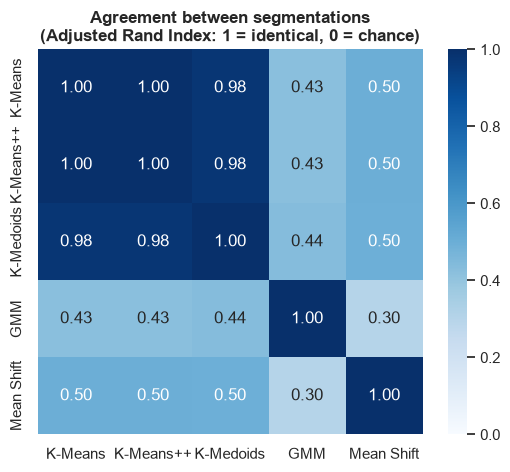

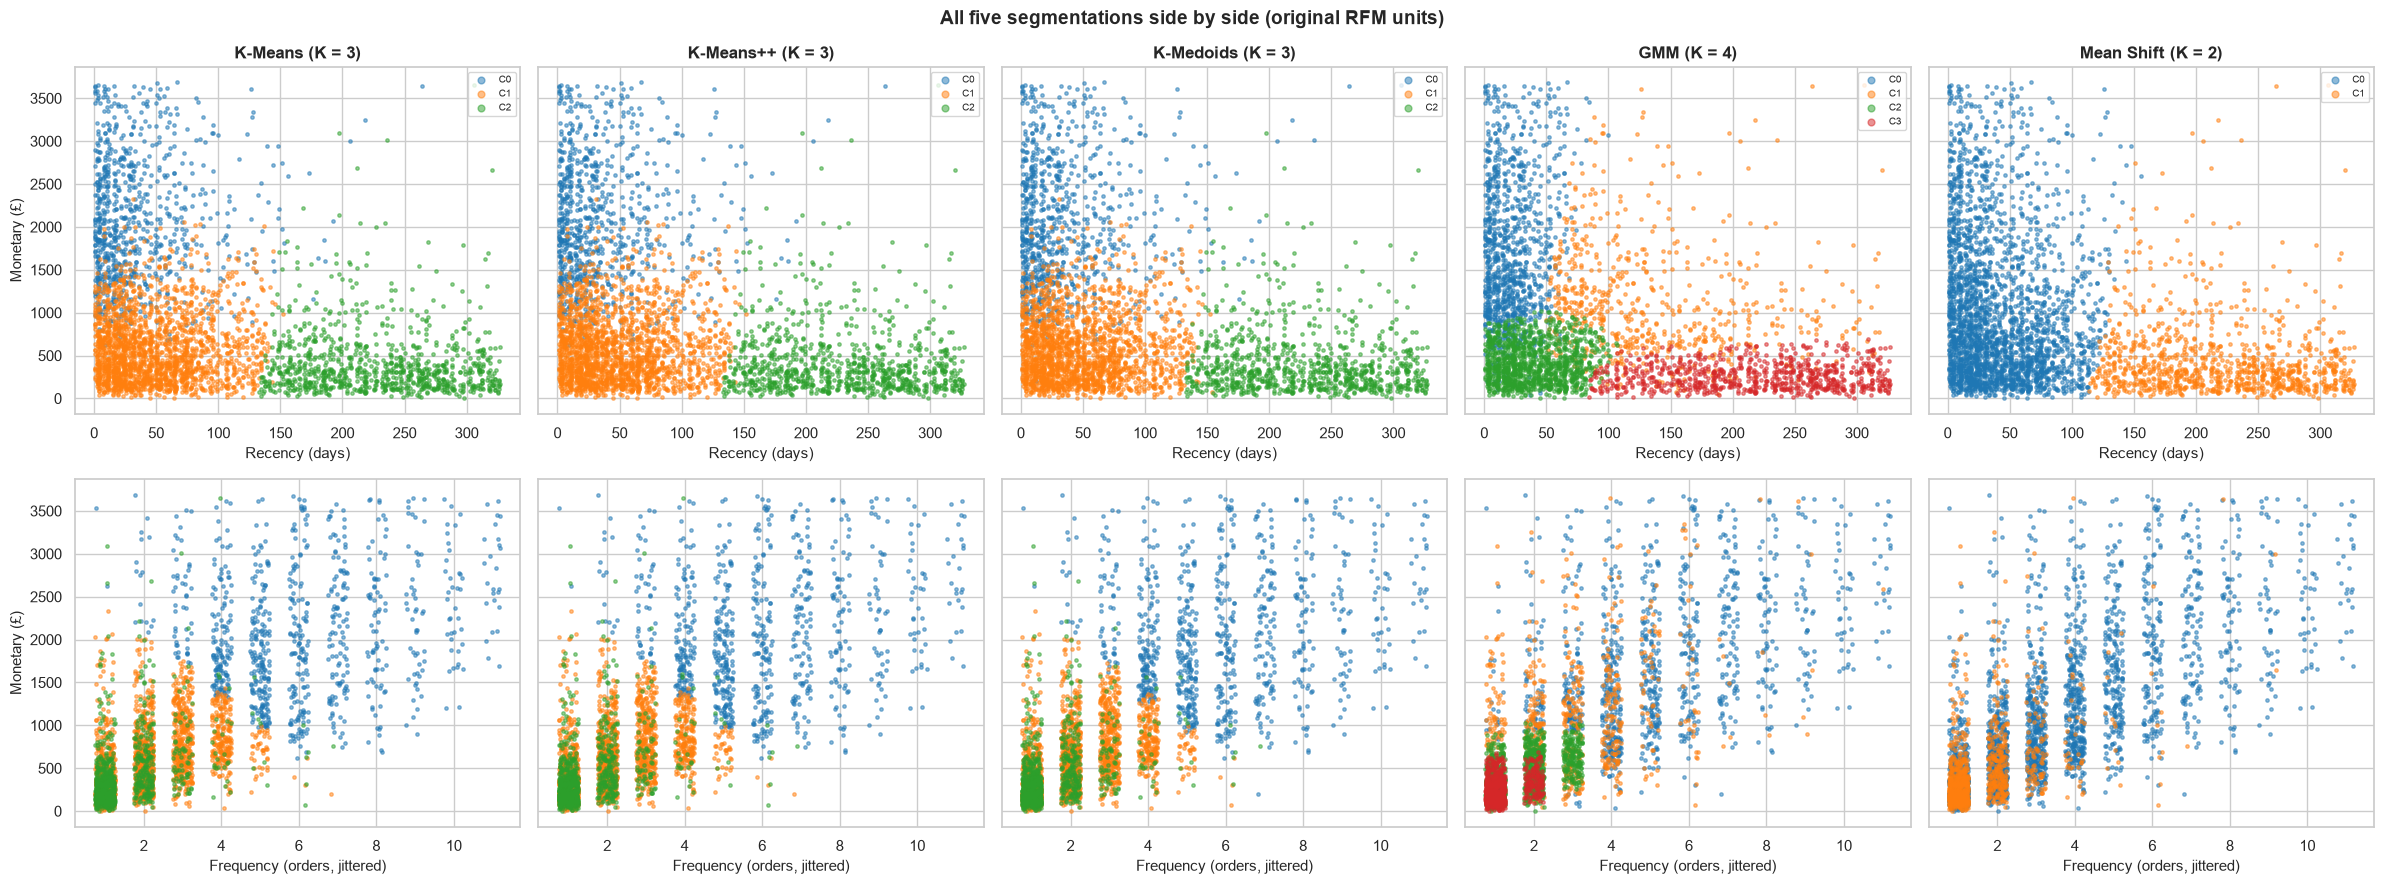

In [33]:
# =====================================================================
# 18.2  AGREEMENT BETWEEN SEGMENTATIONS (Adjusted Rand Index) + SIDE-BY-SIDE PLOTS
# =====================================================================
ari_matrix = pd.DataFrame(index=MODEL_ORDER, columns=MODEL_ORDER, dtype=float)
for a in MODEL_ORDER:
    for b in MODEL_ORDER:
        ari_matrix.loc[a, b] = adjusted_rand_score(cluster_results[a]["labels"], cluster_results[b]["labels"])
fig, ax = plt.subplots(figsize=(6.5, 5))
sns.heatmap(ari_matrix, annot=True, fmt=".2f", cmap="Blues", vmin=0, vmax=1, ax=ax, square=True)
ax.set_title("Agreement between segmentations\n(Adjusted Rand Index: 1 = identical, 0 = chance)")
save_fig(fig, "fig_18_ari_agreement")

rng = np.random.default_rng(RANDOM_STATE)
frequency_jittered = rfm_clean["Frequency"].to_numpy() + rng.uniform(-0.25, 0.25, len(rfm_clean))
fig, axes = plt.subplots(2, 5, figsize=(24, 9), sharey=True)
for j, name in enumerate(MODEL_ORDER):
    labels = cluster_results[name]["labels"]
    clusters = np.sort(np.unique(labels))
    for color, c in zip(cluster_palette(len(clusters)), clusters):
        mask = labels == c
        axes[0, j].scatter(rfm_clean["Recency"].to_numpy()[mask], rfm_clean["Monetary"].to_numpy()[mask], s=6, alpha=0.5, color=color, label=f"C{c}")
        axes[1, j].scatter(frequency_jittered[mask], rfm_clean["Monetary"].to_numpy()[mask], s=6, alpha=0.5, color=color)
    axes[0, j].set_title(f"{name} (K = {len(clusters)})")
    axes[0, j].set_xlabel("Recency (days)")
    axes[1, j].set_xlabel("Frequency (orders, jittered)")
    axes[0, j].legend(markerscale=2, fontsize=7, loc="upper right")
axes[0, 0].set_ylabel("Monetary (£)")
axes[1, 0].set_ylabel("Monetary (£)")
fig.suptitle("All five segmentations side by side (original RFM units)", fontweight="bold", fontsize=14)
fig.tight_layout()
save_fig(fig, "fig_18_all_algorithms_scatter")


Cluster profile: K-Means++ (3 clusters)


,Cluster,Customer Count,% of Customers,Mean Recency,Mean Frequency,Mean Monetary,Total Revenue,% of Revenue
0,0,828,22.32,35.00,6.04,2082.59,1724387.39,52.63
1,1,1964,52.94,49.28,2.10,589.64,1158054.86,35.34
2,2,918,24.74,227.64,1.53,429.47,394256.18,12.03


Overall means for reference: Recency = 90.2 days, Frequency = 2.83 orders, Monetary = £883.21


,Cluster,Recency level,Frequency level,Monetary level,Data-driven interpretation
0,0,Low,High,High,"recently active, frequent and high-spending pu..."
1,1,Low,Low,Low,"purchased recently, orders rarely and spends l..."
2,2,High,Low,Low,less recent and lower-engagement purchasing be...


Cluster 0: 828 customers (22.3%), mean Recency 35 days, Frequency 6.0, Monetary £2,083 → recently active, frequent and high-spending purchasing behaviour.
Cluster 1: 1,964 customers (52.9%), mean Recency 49 days, Frequency 2.1, Monetary £590 → purchased recently, orders rarely and spends little.
Cluster 2: 918 customers (24.7%), mean Recency 228 days, Frequency 1.5, Monetary £429 → less recent and lower-engagement purchasing behaviour.


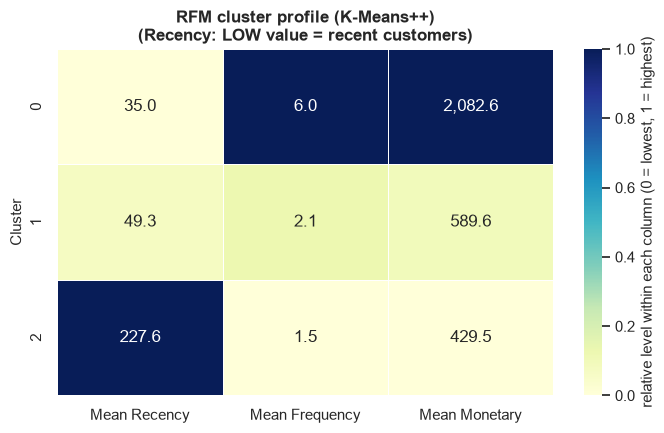

In [34]:
# =====================================================================
# 19.1  PROFILE OF THE PRIMARY SEGMENTATION
# =====================================================================
def profile_clusters(rfm_values, labels):
    """Customer count, share, mean R/F/M and total revenue for every cluster."""
    data = rfm_values[RFM_COLS].copy()
    data["Cluster"] = np.asarray(labels)
    profile = (data.groupby("Cluster")
               .agg(**{"Customer Count": ("Recency", "size"), "Mean Recency": ("Recency", "mean"),
                       "Mean Frequency": ("Frequency", "mean"), "Mean Monetary": ("Monetary", "mean"),
                       "Total Revenue": ("Monetary", "sum")})
               .reset_index())
    profile.insert(2, "% of Customers", 100 * profile["Customer Count"] / profile["Customer Count"].sum())
    profile["% of Revenue"] = 100 * profile["Total Revenue"] / profile["Total Revenue"].sum()
    return profile

RECENCY_TEXT = {"Low": "purchased recently", "Medium": "purchased moderately recently",
                "High": "has not purchased for a long time"}
FREQUENCY_TEXT = {"Low": "orders rarely", "Medium": "orders occasionally", "High": "orders frequently"}
MONETARY_TEXT = {"Low": "spends little", "Medium": "spends a moderate amount", "High": "spends a lot"}

def level(value, overall_mean, low=0.75, high=1.25):
    ratio = value / overall_mean
    return "Low" if ratio < low else ("High" if ratio > high else "Medium")

def interpret_clusters(profile, rfm_values):
    """Turn the numbers into plain-language descriptions (relative to the overall means)."""
    overall = rfm_values[RFM_COLS].mean()
    rows = []
    for _, row in profile.iterrows():
        r = level(row["Mean Recency"], overall["Recency"])
        f = level(row["Mean Frequency"], overall["Frequency"])
        m = level(row["Mean Monetary"], overall["Monetary"])
        if r == "Low" and f == "High" and m == "High":
            summary = "recently active, frequent and high-spending purchasing behaviour"
        elif r == "High" and f == "Low" and m == "Low":
            summary = "less recent and lower-engagement purchasing behaviour"
        else:
            summary = f"{RECENCY_TEXT[r]}, {FREQUENCY_TEXT[f]} and {MONETARY_TEXT[m]}"
        rows.append({"Cluster": int(row["Cluster"]), "Recency level": r, "Frequency level": f, "Monetary level": m,
                     "Data-driven interpretation": summary})
    return pd.DataFrame(rows)

primary_labels = cluster_results[PRIMARY_MODEL]["labels"]
cluster_profile = profile_clusters(rfm_clean, primary_labels)
cluster_interpretation = interpret_clusters(cluster_profile, rfm_clean)

banner(f"Cluster profile: {PRIMARY_MODEL} ({cluster_results[PRIMARY_MODEL]['Number of Clusters']} clusters)")
display(cluster_profile.round(2))
overall_means = rfm_clean[RFM_COLS].mean()
print(f"Overall means for reference: Recency = {overall_means['Recency']:.1f} days, "
      f"Frequency = {overall_means['Frequency']:.2f} orders, Monetary = £{overall_means['Monetary']:,.2f}")
display(cluster_interpretation)
for _, row in cluster_interpretation.merge(cluster_profile, on="Cluster").iterrows():
    print(f"Cluster {row['Cluster']}: {row['Customer Count']:,} customers ({row['% of Customers']:.1f}%), "
          f"mean Recency {row['Mean Recency']:.0f} days, Frequency {row['Mean Frequency']:.1f}, "
          f"Monetary £{row['Mean Monetary']:,.0f} → {row['Data-driven interpretation']}.")

# Heatmap: colour = relative level within each column, text = actual mean values
heat = cluster_profile.set_index("Cluster")[["Mean Recency", "Mean Frequency", "Mean Monetary"]]
colour_scale = (heat - heat.min()) / (heat.max() - heat.min()).replace(0, 1)
annotations = np.vectorize(lambda v: f"{v:,.1f}")(heat.to_numpy())
fig, ax = plt.subplots(figsize=(8, 0.9 * len(heat) + 1.8))
sns.heatmap(colour_scale, annot=annotations, fmt="", cmap="YlGnBu", ax=ax, linewidths=0.5,
            cbar_kws={"label": "relative level within each column (0 = lowest, 1 = highest)"})
ax.set_title(f"RFM cluster profile ({PRIMARY_MODEL})\n(Recency: LOW value = recent customers)")
ax.set_ylabel("Cluster")
save_fig(fig, "fig_19_profile_heatmap")

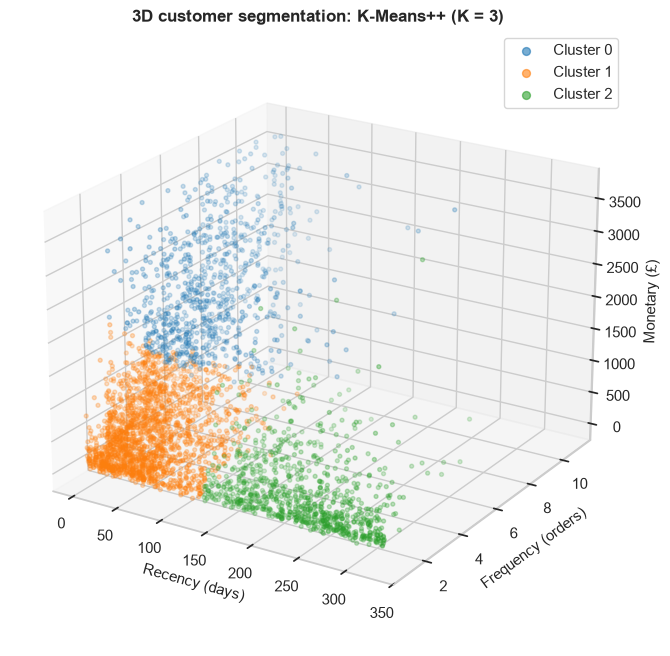

Profiles of all five segmentations (first rows):


,Model,Cluster,Customer Count,% of Customers,Mean Recency,Mean Frequency,Mean Monetary,Total Revenue,% of Revenue
0,K-Means,0,828,22.32,35.00,6.04,2082.59,1724387.39,52.63
1,K-Means,1,1964,52.94,49.28,2.10,589.64,1158054.86,35.34
2,K-Means,2,918,24.74,227.64,1.53,429.47,394256.18,12.03
3,K-Means++,0,828,22.32,35.00,6.04,2082.59,1724387.39,52.63
4,K-Means++,1,1964,52.94,49.28,2.10,589.64,1158054.86,35.34
5,K-Means++,2,918,24.74,227.64,1.53,429.47,394256.18,12.03
6,K-Medoids,0,849,22.88,35.58,5.99,2067.89,1755638.75,53.58
7,K-Medoids,1,1943,52.37,49.36,2.08,583.49,1133713.38,34.60
8,K-Medoids,2,918,24.74,227.28,1.51,421.95,387346.30,11.82
9,GMM,0,1041,28.06,22.38,5.29,1745.58,1817151.98,55.46


In [35]:
# =====================================================================
# 19.2  3D VIEW OF THE PRIMARY SEGMENTATION (X = Recency, Y = Frequency, Z = Monetary)
# =====================================================================
fig = plt.figure(figsize=(10, 8))
ax = fig.add_subplot(111, projection="3d")
clusters = np.sort(np.unique(primary_labels))
for color, c in zip(cluster_palette(len(clusters)), clusters):
    mask = primary_labels == c
    ax.scatter(rfm_clean.loc[mask, "Recency"], rfm_clean.loc[mask, "Frequency"], rfm_clean.loc[mask, "Monetary"],
               s=8, alpha=0.6, color=color, label=f"Cluster {c}")
ax.set_xlabel("Recency (days)")
ax.set_ylabel("Frequency (orders)")
ax.set_zlabel("Monetary (£)")
ax.set_title(f"3D customer segmentation: {PRIMARY_MODEL} (K = {len(clusters)})")
ax.view_init(elev=22, azim=-58)
ax.legend(markerscale=2)
save_fig(fig, "fig_19_3d_segments")

# Profiles of ALL five algorithms (saved in Section 28 for the report)
all_profiles = pd.concat([profile_clusters(rfm_clean, cluster_results[name]["labels"]).assign(Model=name)
                          for name in MODEL_ORDER], ignore_index=True)
all_profiles = all_profiles[["Model"] + [c for c in all_profiles.columns if c != "Model"]]
print("Profiles of all five segmentations (first rows):")
display(all_profiles.round(2).head(12))


CLV windows
Observation window : 2010-12-01 → 2011-08-31  (274 days)
Prediction window  : 2011-09-01 → 2011-12-09  (100 days)
✔ Last observation transaction (2011-08-31 17:16:00) < cutoff ≤ first prediction transaction (2011-09-01 08:25:00)
✔ Recency, Frequency and Monetary are computed from observation-window transactions only
✔ The target is computed from prediction-window transactions only and is never used as an input

Customers active in the observation window: 3,317
After the IQR rule on their observation-window R, F, M: 2,957 (10.9% removed)
Customers who buy again in the prediction window: 54.7%


,Recency,Frequency,Monetary,FutureGrossRevenue,FutureCancelledValue,CLV_Target
count,2957.00,2957.00,2957.00,2957.00,2957.00,2957.00
mean,99.79,2.28,704.18,473.21,-70.50,403.40
std,76.65,1.67,647.79,3386.95,3104.27,1230.96
min,0.00,1.00,2.90,0.00,-168469.60,0.00
25%,34.00,1.00,232.21,0.00,0.00,0.00
50%,83.00,2.00,462.58,133.68,0.00,129.50
75%,154.00,3.00,959.10,565.75,0.00,551.81
max,273.00,8.00,2999.41,168469.60,0.00,57100.67


Largest GROSS future revenues vs the NET target (after cancellations):


,CustomerID,Recency,Frequency,Monetary,FutureGrossRevenue,FutureCancelledValue,CLV_Target
2056,16446,105,1,2.90,168469.60,-168469.60,0.00
865,14096,1,1,21.84,65142.95,-8042.28,57100.67
1137,14607,161,1,495.00,15714.50,-5228.40,10486.10
1269,14866,5,4,1163.90,13226.00,-192.45,13033.55
1578,15482,65,4,1928.30,8951.46,-4486.24,4465.22


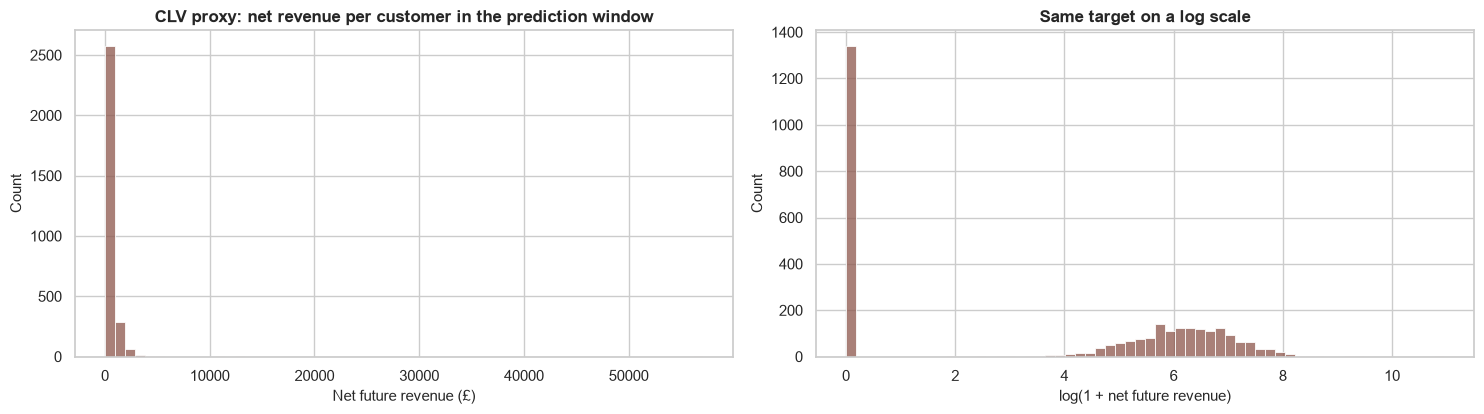

In [36]:
# =====================================================================
# 20.1  BUILD THE CLV DATASET (features before the cutoff, target after it)
# =====================================================================
cutoff = pd.Timestamp(CLV_CUTOFF_DATE)
data_start, data_end = df_clean["InvoiceDate"].min(), df_clean["InvoiceDate"].max()
observation_days = (cutoff - data_start.normalize()).days
prediction_days = (data_end.normalize() - cutoff).days + 1

def build_clv_dataset(transactions, cancellations, cutoff_date):
    """Features from the observation window; target = NET revenue in the prediction window."""
    observation = transactions[transactions["InvoiceDate"] < cutoff_date]
    prediction = transactions[transactions["InvoiceDate"] >= cutoff_date]
    future_cancellations = cancellations[cancellations["InvoiceDate"] >= cutoff_date]

    features = create_rfm(observation, snapshot_date=cutoff_date)            # ONLY pre-cutoff transactions
    gross = prediction.groupby("CustomerID")["Revenue"].sum()
    cancelled = ((future_cancellations["Quantity"] * future_cancellations["UnitPrice"])
                 .groupby(future_cancellations["CustomerID"]).sum())          # negative values
    data = features.copy()
    data["FutureGrossRevenue"] = data["CustomerID"].map(gross).fillna(0.0)
    data["FutureCancelledValue"] = data["CustomerID"].map(cancelled).fillna(0.0)
    data["CLV_Target"] = (data["FutureGrossRevenue"] + data["FutureCancelledValue"]).clip(lower=0)
    return data, observation, prediction

clv_all, observation_tx, prediction_tx = build_clv_dataset(df_clean, df_cancellations, cutoff)

banner("CLV windows")
print(f"Observation window : {data_start.date()} → {(cutoff - pd.Timedelta(days=1)).date()}  ({observation_days} days)")
print(f"Prediction window  : {cutoff.date()} → {data_end.date()}  ({prediction_days} days)")

# ---- Leakage checks ----
assert observation_tx["InvoiceDate"].max() < cutoff <= prediction_tx["InvoiceDate"].min()
print(f"✔ Last observation transaction ({observation_tx['InvoiceDate'].max()}) < cutoff ≤ first prediction "
      f"transaction ({prediction_tx['InvoiceDate'].min()})")
print("✔ Recency, Frequency and Monetary are computed from observation-window transactions only")
print("✔ The target is computed from prediction-window transactions only and is never used as an input")

# ---- Same outlier rule as the paper, applied to the observation-window RFM ----
clv_data, clv_iqr_bounds = remove_iqr_outliers(clv_all)
print(f"\nCustomers active in the observation window: {len(clv_all):,}")
print(f"After the IQR rule on their observation-window R, F, M: {len(clv_data):,} "
      f"({(len(clv_all) - len(clv_data)) / len(clv_all):.1%} removed)")
print(f"Customers who buy again in the prediction window: {(clv_data['CLV_Target'] > 0).mean():.1%}")
display(clv_data[RFM_COLS + ["FutureGrossRevenue", "FutureCancelledValue", "CLV_Target"]].describe().round(2))

print("Largest GROSS future revenues vs the NET target (after cancellations):")
display(clv_data.nlargest(5, "FutureGrossRevenue")[["CustomerID"] + RFM_COLS +
                                                   ["FutureGrossRevenue", "FutureCancelledValue", "CLV_Target"]].round(2))

fig, axes = plt.subplots(1, 2, figsize=(15, 4.3))
sns.histplot(clv_data["CLV_Target"], bins=60, ax=axes[0], color="#8c564b")
axes[0].set_title("CLV proxy: net revenue per customer in the prediction window")
axes[0].set_xlabel("Net future revenue (£)")
sns.histplot(np.log1p(clv_data["CLV_Target"]), bins=60, ax=axes[1], color="#8c564b")
axes[1].set_title("Same target on a log scale")
axes[1].set_xlabel("log(1 + net future revenue)")
fig.tight_layout()
save_fig(fig, "fig_20_clv_target_distribution")

In [37]:
# =====================================================================
# 20.2  TRAIN/TEST SPLIT + SEGMENT FEATURE (fitted on TRAINING customers only)
# =====================================================================
clv_train, clv_test = train_test_split(clv_data, test_size=TEST_SIZE, random_state=RANDOM_STATE)
clv_train, clv_test = clv_train.copy(), clv_test.copy()

clv_k = cluster_results[PRIMARY_MODEL]["Number of Clusters"]           # same K as the primary segmentation
clv_scaler = MinMaxScaler().fit(clv_train[RFM_COLS])                   # fitted on training customers only
clv_kmeans = KMeans(n_clusters=clv_k, init="k-means++", n_init=10, random_state=RANDOM_STATE)
clv_kmeans.fit(clv_scaler.transform(clv_train[RFM_COLS]))              # fitted on training customers only
clv_mapping = monetary_order_mapping(clv_kmeans.labels_, clv_train["Monetary"])
clv_train["Cluster"] = pd.Series(clv_kmeans.labels_).map(clv_mapping).to_numpy()
clv_test["Cluster"] = pd.Series(clv_kmeans.predict(clv_scaler.transform(clv_test[RFM_COLS]))).map(clv_mapping).to_numpy()

def make_clv_features(df):
    """Model inputs: observation-window R, F, M + one-hot K-Means++ segment. The target is NOT an input."""
    X = df[RFM_COLS].copy()
    for c in range(clv_k):
        X[f"Cluster_{c}"] = (df["Cluster"] == c).astype(int)
    return X

X_train, X_test = make_clv_features(clv_train), make_clv_features(clv_test)
y_train, y_test = clv_train["CLV_Target"], clv_test["CLV_Target"]
FEATURE_COLUMNS = list(X_train.columns)

print(f"Training customers: {len(X_train):,} | Test customers: {len(X_test):,} | random_state = {RANDOM_STATE}")
print("Model inputs:", FEATURE_COLUMNS)
assert "CLV_Target" not in FEATURE_COLUMNS and not any(col.startswith("Future") for col in FEATURE_COLUMNS)
print("✔ No future information among the model inputs")
print(f"✔ Min-Max scaler and K-Means++ (K = {clv_k}) were fitted on the {len(X_train):,} training customers only")
display(clv_train["Cluster"].value_counts().sort_index().rename_axis("Cluster").to_frame("Training customers"))
print("Example training rows (inputs + target):")
display(pd.concat([X_train.head(), y_train.head()], axis=1).round(2))

Training customers: 2,365 | Test customers: 592 | random_state = 42
Model inputs: ['Recency', 'Frequency', 'Monetary', 'Cluster_0', 'Cluster_1', 'Cluster_2']
✔ No future information among the model inputs
✔ Min-Max scaler and K-Means++ (K = 3) were fitted on the 2,365 training customers only


,Training customers
Cluster,
0,487
1,1135
2,743


Example training rows (inputs + target):


,Recency,Frequency,Monetary,Cluster_0,Cluster_1,Cluster_2,CLV_Target
1359,24,7,1234.76,1,0,0,867.78
1873,100,3,587.06,0,1,0,534.33
2517,50,1,393.31,0,1,0,573.91
1366,79,1,1109.53,0,1,0,0.00
2090,44,2,565.70,0,1,0,352.63



Random Forest Regressor (untuned, random_state = 42)


Random Forest (Untuned): MAE = £348.09 | MSE = 263,762.21 | RMSE = £513.58 | R² = 0.0160   [0.3 s]


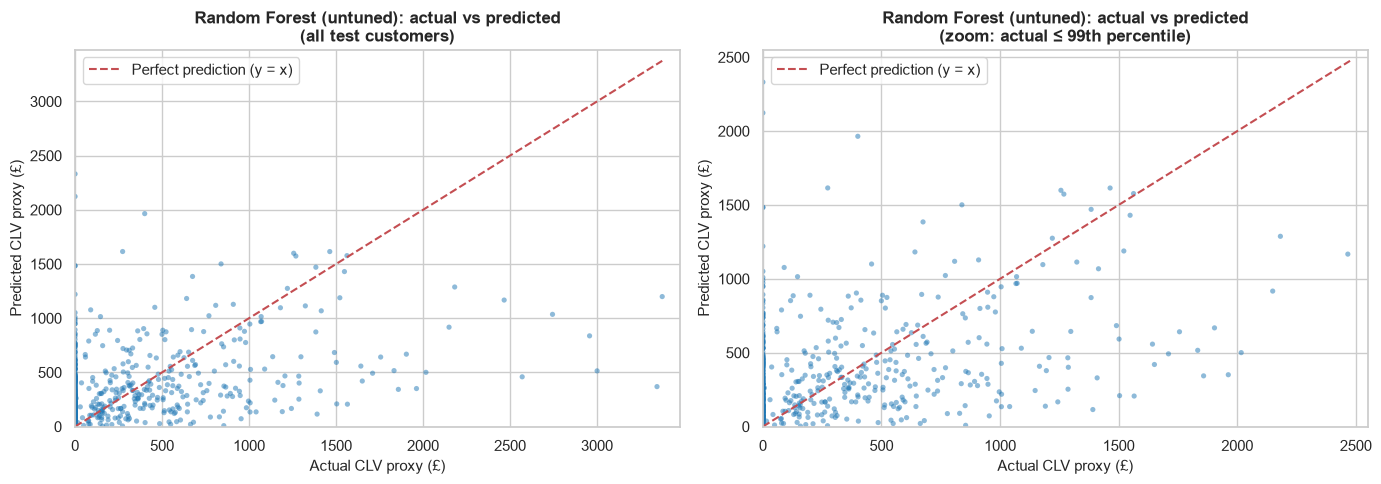

In [38]:
# =====================================================================
# 21.1  EVALUATION HELPERS + RANDOM FOREST (default settings)
# =====================================================================
clv_results = {}               # (model, "Tuned"/"Untuned") -> metrics  (re-running a cell overwrites, never duplicates)
clv_test_predictions = {}      # "Model (Tuned/Untuned)" -> predictions for the test customers

def regression_metrics(y_true, y_pred):
    mse = mean_squared_error(y_true, y_pred)
    return {"MAE": mean_absolute_error(y_true, y_pred), "MSE": mse, "RMSE": float(np.sqrt(mse)),
            "R²": r2_score(y_true, y_pred)}

def train_clv_models(models, tuned_label="Untuned", fit=True):
    """Fit (optionally) every model in {name: model} and evaluate it on the SAME test customers."""
    for name, model in models.items():
        start = time.time()
        if fit:
            model.fit(X_train, y_train)
        predictions = model.predict(X_test)
        metrics = regression_metrics(y_test, predictions)
        clv_results[(name, tuned_label)] = {"Model": name, "Tuned/Untuned": tuned_label, **metrics}
        clv_test_predictions[f"{name} ({tuned_label})"] = predictions
        print(f"{name} ({tuned_label}): MAE = £{metrics['MAE']:,.2f} | MSE = {metrics['MSE']:,.2f} | "
              f"RMSE = £{metrics['RMSE']:,.2f} | R² = {metrics['R²']:.4f}   [{time.time() - start:.1f} s]")
    return models

def plot_actual_vs_predicted(y_true, y_pred, title, file_name):
    """Left: all test customers. Right: zoom on customers whose actual value is ≤ the 99th percentile."""
    y_true, y_pred = np.asarray(y_true, dtype=float), np.asarray(y_pred, dtype=float)
    fig, axes = plt.subplots(1, 2, figsize=(14, 5))
    for ax, limit, subtitle in [(axes[0], max(y_true.max(), y_pred.max()), "all test customers"),
                                (axes[1], np.quantile(y_true, 0.99), "zoom: actual ≤ 99th percentile")]:
        mask = y_true <= limit
        ax.scatter(y_true[mask], y_pred[mask], s=14, alpha=0.5, color="#1f77b4", edgecolor="none")
        ax.plot([0, limit], [0, limit], "r--", label="Perfect prediction (y = x)")
        ax.set_xlim(0, limit * 1.03)
        ax.set_ylim(0, max(limit, y_pred[mask].max()) * 1.03)
        ax.set_title(f"{title}\n({subtitle})")
        ax.set_xlabel("Actual CLV proxy (£)")
        ax.set_ylabel("Predicted CLV proxy (£)")
        ax.legend(loc="upper left")
    fig.tight_layout()
    save_fig(fig, file_name)

banner("Random Forest Regressor (untuned, random_state = 42)")
rf_model = RandomForestRegressor(n_estimators=100, random_state=RANDOM_STATE, n_jobs=-1)
train_clv_models({"Random Forest": rf_model}, "Untuned")
plot_actual_vs_predicted(y_test, clv_test_predictions["Random Forest (Untuned)"],
                         "Random Forest (untuned): actual vs predicted", "fig_21_rf_actual_vs_predicted")


Gradient Boosting Regressor (untuned, random_state = 42)


Gradient Boosting (Untuned): MAE = £331.35 | MSE = 223,682.13 | RMSE = £472.95 | R² = 0.1655   [0.3 s]


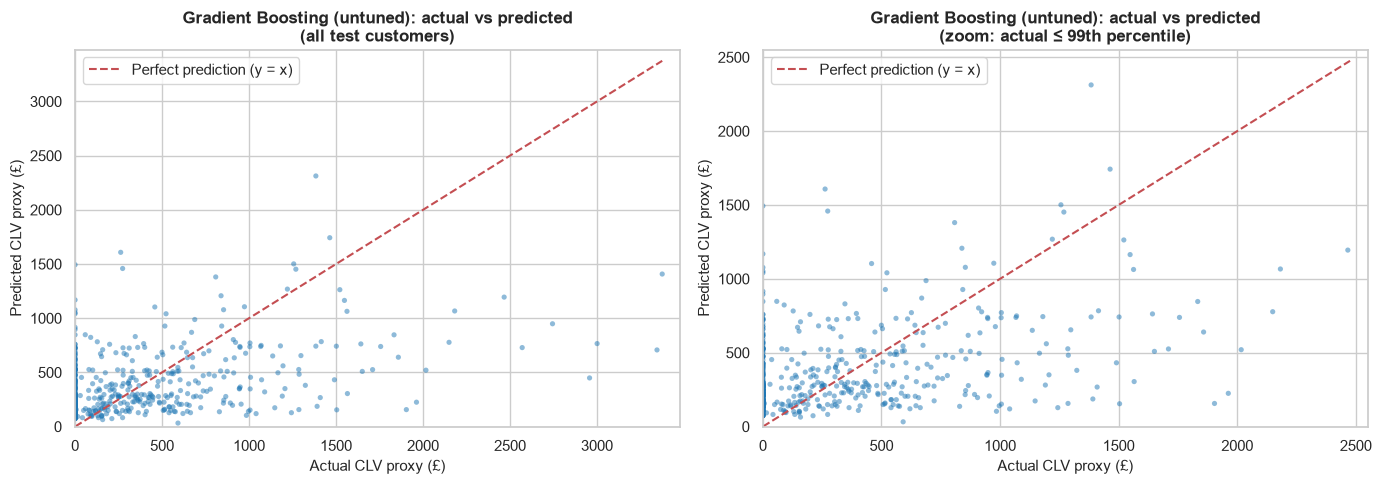

In [39]:
# =====================================================================
# 22.1  GRADIENT BOOSTING (default settings)
# =====================================================================
banner("Gradient Boosting Regressor (untuned, random_state = 42)")
gb_model = GradientBoostingRegressor(random_state=RANDOM_STATE)
train_clv_models({"Gradient Boosting": gb_model}, "Untuned")
plot_actual_vs_predicted(y_test, clv_test_predictions["Gradient Boosting (Untuned)"],
                         "Gradient Boosting (untuned): actual vs predicted", "fig_22_gb_actual_vs_predicted")


Hyperparameter tuning with RandomizedSearchCV

Tuning Random Forest: 20 random candidates × 5-fold CV = 100 model fits ...


   finished in 15 s
   Best parameters : {'max_depth': 16, 'max_features': 'log2', 'min_samples_leaf': 19, 'min_samples_split': 13, 'n_estimators': 154}
   Best CV score   : mean R² = 0.0983 over 5 folds (training customers only)


,rank_test_score,mean_test_score,std_test_score,params
7,1,0.0983,0.0610,"{'max_depth': 16, 'max_features': 'log2', 'min..."
12,2,0.0913,0.0562,"{'max_depth': 5, 'max_features': 'sqrt', 'min_..."
6,3,0.0829,0.0499,"{'max_depth': 3, 'max_features': 0.5, 'min_sam..."
10,4,0.0728,0.0532,"{'max_depth': None, 'max_features': 0.5, 'min_..."
14,5,0.0715,0.0525,"{'max_depth': 16, 'max_features': 1.0, 'min_sa..."



Tuning Gradient Boosting: 20 random candidates × 5-fold CV = 100 model fits ...


   finished in 10 s
   Best parameters : {'learning_rate': 0.1926, 'max_depth': 2, 'min_samples_leaf': 16, 'min_samples_split': 14, 'n_estimators': 387, 'subsample': 0.8159}
   Best CV score   : mean R² = 0.1134 over 5 folds (training customers only)


,rank_test_score,mean_test_score,std_test_score,params
11,1,0.1134,0.0689,"{'learning_rate': 0.19262268462637636, 'max_de..."
3,2,0.1010,0.0657,"{'learning_rate': 0.19852019626533135, 'max_de..."
12,3,0.0927,0.0531,"{'learning_rate': 0.12148272147613116, 'max_de..."
7,4,0.0910,0.0539,"{'learning_rate': 0.013033587921840697, 'max_d..."
4,5,0.0836,0.0591,"{'learning_rate': 0.1262520499972521, 'max_dep..."



Tuned models on the (untouched) test customers
Random Forest (Tuned): MAE = £342.17 | MSE = 228,545.90 | RMSE = £478.06 | R² = 0.1474   [0.1 s]
Gradient Boosting (Tuned): MAE = £332.35 | MSE = 220,795.65 | RMSE = £469.89 | R² = 0.1763   [0.0 s]


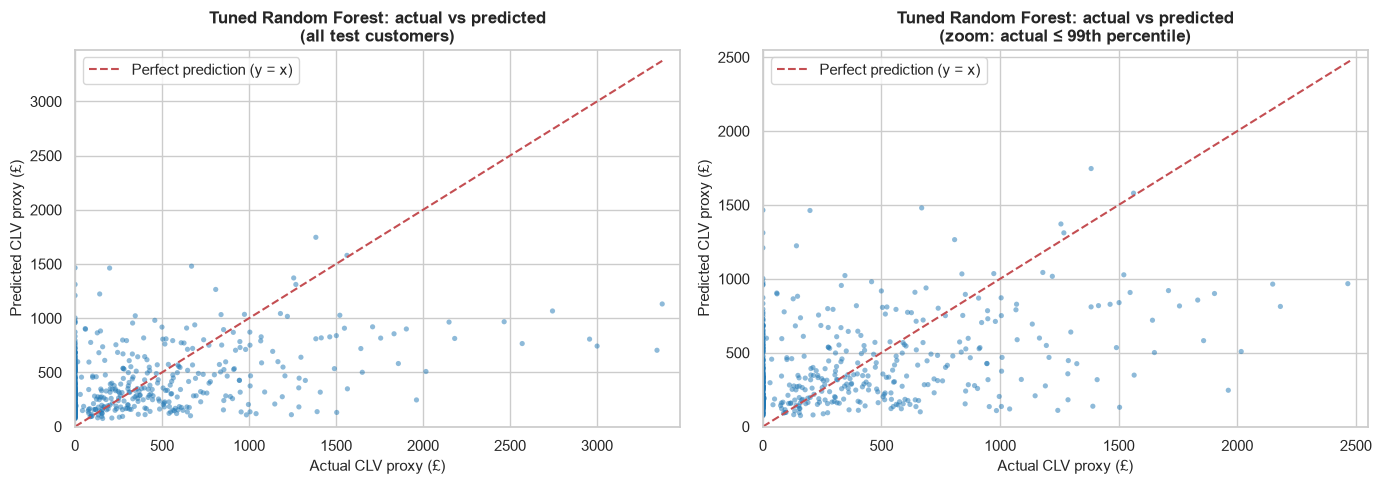

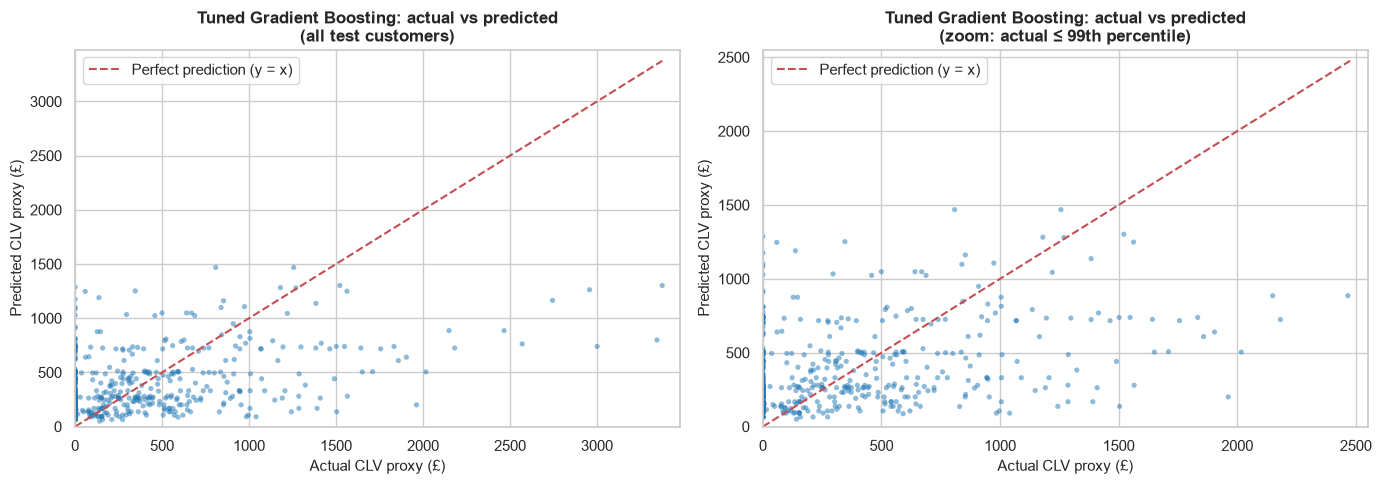

In [40]:
# =====================================================================
# 23.1  RANDOMIZEDSEARCHCV FOR RANDOM FOREST AND GRADIENT BOOSTING
# =====================================================================
cv_splitter = KFold(n_splits=CV_FOLDS, shuffle=True, random_state=RANDOM_STATE)

rf_param_distributions = {
    "n_estimators": randint(100, 501),
    "max_depth": [None, 3, 5, 8, 12, 16],
    "min_samples_split": randint(2, 21),
    "min_samples_leaf": randint(1, 21),
    "max_features": [1.0, "sqrt", "log2", 0.5],
}
gb_param_distributions = {
    "n_estimators": randint(50, 401),
    "learning_rate": uniform(0.01, 0.19),          # 0.01 … 0.20
    "max_depth": randint(2, 6),                    # 2 … 5
    "min_samples_split": randint(2, 21),
    "min_samples_leaf": randint(1, 21),
    "subsample": uniform(0.6, 0.4),                # 0.6 … 1.0
}

def tune_model(estimator, param_distributions, name):
    """RandomizedSearchCV on the training customers only; returns (search, best parameters)."""
    print(f"\nTuning {name}: {SEARCH_ITERATIONS} random candidates × {CV_FOLDS}-fold CV = "
          f"{SEARCH_ITERATIONS * CV_FOLDS} model fits ...")
    search = RandomizedSearchCV(estimator, param_distributions, n_iter=SEARCH_ITERATIONS, cv=cv_splitter,
                                scoring="r2", random_state=RANDOM_STATE, n_jobs=-1, refit=True)
    start = time.time()
    search.fit(X_train, y_train)
    best_params = {k: (round(float(v), 4) if isinstance(v, (float, np.floating)) else
                       int(v) if isinstance(v, (int, np.integer)) else v)
                   for k, v in search.best_params_.items()}
    print(f"   finished in {time.time() - start:.0f} s")
    print(f"   Best parameters : {best_params}")
    print(f"   Best CV score   : mean R² = {search.best_score_:.4f} over {CV_FOLDS} folds (training customers only)")
    top5 = (pd.DataFrame(search.cv_results_).sort_values("rank_test_score")
            .head(5)[["rank_test_score", "mean_test_score", "std_test_score", "params"]])
    display(top5.round(4))
    return search, best_params

banner("Hyperparameter tuning with RandomizedSearchCV")
rf_search, rf_best_params = tune_model(RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=1),
                                       rf_param_distributions, "Random Forest")
gb_search, gb_best_params = tune_model(GradientBoostingRegressor(random_state=RANDOM_STATE),
                                       gb_param_distributions, "Gradient Boosting")

banner("Tuned models on the (untouched) test customers")
tuned_models = train_clv_models({"Random Forest": rf_search.best_estimator_,
                                 "Gradient Boosting": gb_search.best_estimator_}, "Tuned", fit=False)
plot_actual_vs_predicted(y_test, clv_test_predictions["Random Forest (Tuned)"],
                         "Tuned Random Forest: actual vs predicted", "fig_23_tuned_rf_actual_vs_predicted")
plot_actual_vs_predicted(y_test, clv_test_predictions["Gradient Boosting (Tuned)"],
                         "Tuned Gradient Boosting: actual vs predicted", "fig_23_tuned_gb_actual_vs_predicted")


Final CLV model comparison (Our Reproduction Results, test customers)


,Model,Tuned/Untuned,MAE,MSE,RMSE,R²
0,Random Forest,Untuned,348.0891,263762.2145,513.5779,0.0160
1,Random Forest,Tuned,342.1673,228545.9016,478.0647,0.1474
2,Gradient Boosting,Untuned,331.3477,223682.1323,472.9505,0.1655
3,Gradient Boosting,Tuned,332.3482,220795.6539,469.8890,0.1763


Objective notes (what is lower/higher, not a ranking):
• Lowest MAE      : Gradient Boosting (Untuned), £331.35 average absolute error.
• Lowest RMSE/MSE : Gradient Boosting (Tuned), RMSE £469.89.
• Highest R²      : Gradient Boosting (Tuned), R² = 0.1763.
• Tuning Random Forest: MAE £348.09 → £342.17, RMSE £513.58 → £478.06, R² 0.0160 → 0.1474
• Tuning Gradient Boosting: MAE £331.35 → £332.35, RMSE £472.95 → £469.89, R² 0.1655 → 0.1763
• For reference: the average target in the test set is £330.60 (median £85.65).
R² = 0 would mean 'no better than predicting the average for every customer'. Future spending is noisy,
so moderate R² values are expected for an honest, leakage-free prediction.


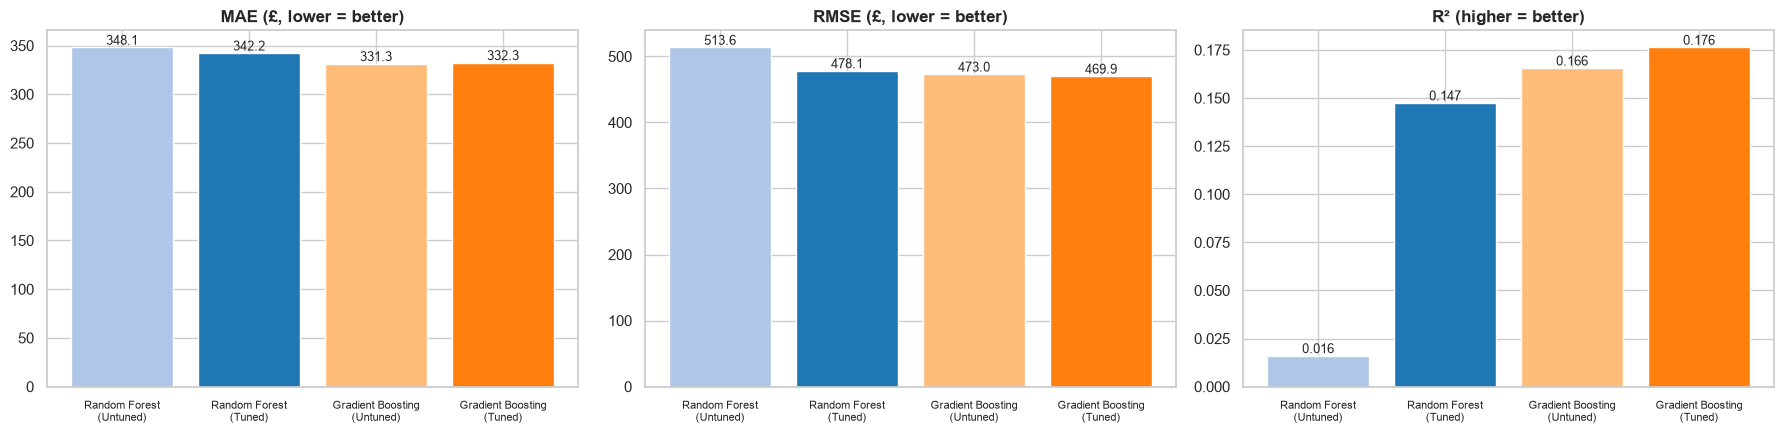

In [41]:
# =====================================================================
# 24.1  FINAL CLV TABLE + OBJECTIVE NOTES
# =====================================================================
CLV_ORDER = [("Random Forest", "Untuned"), ("Random Forest", "Tuned"),
             ("Gradient Boosting", "Untuned"), ("Gradient Boosting", "Tuned")]
clv_model_results = pd.DataFrame([clv_results[key] for key in CLV_ORDER])
banner("Final CLV model comparison (Our Reproduction Results, test customers)")
display(clv_model_results.round(4))

row_mae = clv_model_results.loc[clv_model_results["MAE"].idxmin()]
row_rmse = clv_model_results.loc[clv_model_results["RMSE"].idxmin()]
row_r2 = clv_model_results.loc[clv_model_results["R²"].idxmax()]
print("Objective notes (what is lower/higher, not a ranking):")
print(f"• Lowest MAE      : {row_mae['Model']} ({row_mae['Tuned/Untuned']}), £{row_mae['MAE']:,.2f} average absolute error.")
print(f"• Lowest RMSE/MSE : {row_rmse['Model']} ({row_rmse['Tuned/Untuned']}), RMSE £{row_rmse['RMSE']:,.2f}.")
print(f"• Highest R²      : {row_r2['Model']} ({row_r2['Tuned/Untuned']}), R² = {row_r2['R²']:.4f}.")
for model_name in ["Random Forest", "Gradient Boosting"]:
    before, after = clv_results[(model_name, "Untuned")], clv_results[(model_name, "Tuned")]
    print(f"• Tuning {model_name}: MAE £{before['MAE']:,.2f} → £{after['MAE']:,.2f}, "
          f"RMSE £{before['RMSE']:,.2f} → £{after['RMSE']:,.2f}, R² {before['R²']:.4f} → {after['R²']:.4f}")
print(f"• For reference: the average target in the test set is £{y_test.mean():,.2f} (median £{y_test.median():,.2f}).")
print("R² = 0 would mean 'no better than predicting the average for every customer'. Future spending is noisy,")
print("so moderate R² values are expected for an honest, leakage-free prediction.")

fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))
labels_ = [f"{m}\n({t})" for m, t in zip(clv_model_results["Model"], clv_model_results["Tuned/Untuned"])]
bar_colors = ["#aec7e8", "#1f77b4", "#ffbb78", "#ff7f0e"]
for ax, metric, note in [(axes[0], "MAE", "£, lower = better"), (axes[1], "RMSE", "£, lower = better"),
                         (axes[2], "R²", "higher = better")]:
    bars = ax.bar(labels_, clv_model_results[metric], color=bar_colors)
    for bar, v in zip(bars, clv_model_results[metric]):
        ax.annotate(f"{v:,.3f}" if metric == "R²" else f"{v:,.1f}", (bar.get_x() + bar.get_width() / 2, v),
                    ha="center", va="bottom", fontsize=9)
    ax.set_title(f"{metric} ({note})")
    ax.tick_params(axis="x", labelsize=8)
    ax.axhline(0, color="black", linewidth=0.8)
fig.tight_layout()
save_fig(fig, "fig_24_clv_model_comparison")

In [42]:
# =====================================================================
# 24.2  PAPER-STYLE CLV PER CLUSTER ("High"/"Low", analogue of the paper's Tables 29–31)
# =====================================================================
# The paper compares the predicted CLV of each cluster with its "historical CLV" and labels the cluster
# 'High' if predicted ≥ historical, otherwise 'Low'. The paper does not define "historical CLV". We use the
# observation-window revenue rescaled to the SAME length as the prediction window, so the two are comparable.
# As in the paper, the tuned Gradient Boosting predictions are used (this follows the paper; it is not a ranking).
per_customer = clv_test[["CustomerID", "Cluster"] + RFM_COLS + ["CLV_Target"]].copy()
per_customer["Historical revenue (same-length period)"] = per_customer["Monetary"] * prediction_days / observation_days
per_customer["Predicted CLV (Tuned GB)"] = clv_test_predictions["Gradient Boosting (Tuned)"]
per_customer["Predicted CLV (Tuned RF)"] = clv_test_predictions["Random Forest (Tuned)"]

cluster_clv = (per_customer.groupby("Cluster")
               .agg(**{"Test customers": ("CustomerID", "size"),
                       "Mean Recency": ("Recency", "mean"), "Mean Frequency": ("Frequency", "mean"),
                       "Mean Monetary": ("Monetary", "mean"),
                       "Historical revenue (same-length period)": ("Historical revenue (same-length period)", "mean"),
                       "Actual CLV proxy (mean)": ("CLV_Target", "mean"),
                       "Predicted CLV (Tuned GB)": ("Predicted CLV (Tuned GB)", "mean"),
                       "Predicted CLV (Tuned RF)": ("Predicted CLV (Tuned RF)", "mean")}))
cluster_clv["Paper-style CLV label (GB)"] = np.where(
    cluster_clv["Predicted CLV (Tuned GB)"] >= cluster_clv["Historical revenue (same-length period)"], "High", "Low")
print(f"Test customers by K-Means++ segment (segment model fitted on training customers; K = {clv_k}):")
display(cluster_clv.round(2))
print("Read this as: the segment's average predicted revenue for the next", prediction_days,
      "days compared with what it spent in an equally long period before the cutoff.")
print("Note: the prediction window contains the pre-Christmas peak (see the monthly revenue chart in Section 6),")
print("which raises future revenue for all segments.")

Test customers by K-Means++ segment (segment model fitted on training customers; K = 3):


,Test customers,Mean Recency,Mean Frequency,Mean Monetary,Historical revenue (same-length period),Actual CLV proxy (mean),Predicted CLV (Tuned GB),Predicted CLV (Tuned RF),Paper-style CLV label (GB)
Cluster,,,,,,,,,
0,97,40.91,5.02,1621.09,591.64,802.25,806.72,824.60,High
1,292,59.74,1.78,511.33,186.62,288.46,341.31,370.59,High
2,203,197.03,1.23,341.12,124.50,165.83,194.42,204.71,High


Read this as: the segment's average predicted revenue for the next 100 days compared with what it spent in an equally long period before the cutoff.
Note: the prediction window contains the pre-Christmas peak (see the monthly revenue chart in Section 6),
which raises future revenue for all segments.


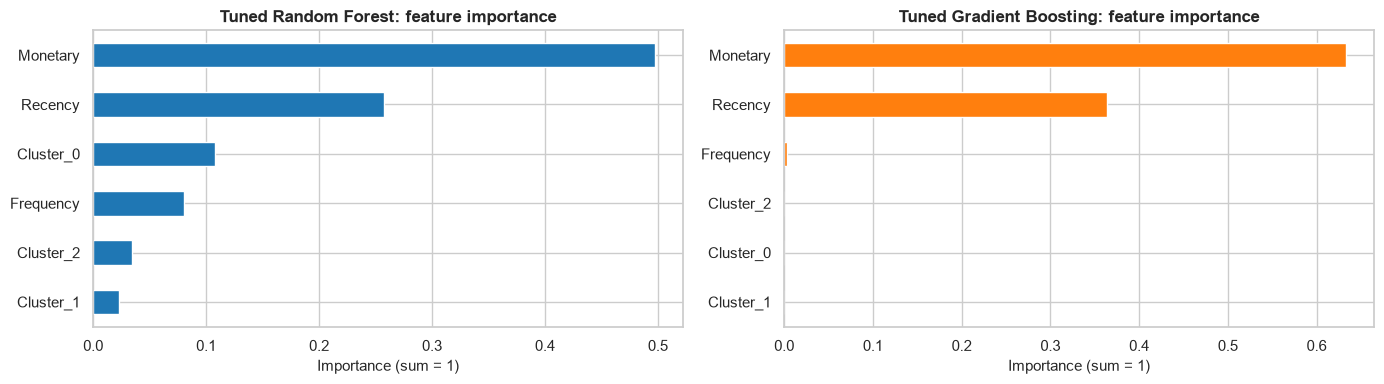

In [43]:
# =====================================================================
# 24.3  WHICH INPUTS DO THE TUNED MODELS USE? (impurity-based feature importance)
# =====================================================================
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
for ax, (name, model), color in zip(axes, tuned_models.items(), ["#1f77b4", "#ff7f0e"]):
    importance = pd.Series(model.feature_importances_, index=FEATURE_COLUMNS).sort_values()
    importance.plot(kind="barh", ax=ax, color=color)
    ax.set_title(f"Tuned {name}: feature importance")
    ax.set_xlabel("Importance (sum = 1)")
fig.tight_layout()
save_fig(fig, "fig_24_feature_importance")

In [44]:
# =====================================================================
# 25.1  FINAL TABLES 1–6
# =====================================================================
table1_dataset = pd.DataFrame([
    ("Raw rows", f"{len(df_raw):,}"),
    ("Raw columns", f"{df_raw.shape[1]}"),
    ("Raw unique customers (non-missing ID)", f"{df_raw['CustomerID'].nunique():,}"),
    ("Raw unique invoices", f"{df_raw['InvoiceNo'].astype(str).nunique():,}"),
    ("Raw unique products", f"{df_raw['StockCode'].astype(str).nunique():,}"),
    ("Countries", f"{df_raw['Country'].nunique()}"),
    ("Date range", f"{df_raw['InvoiceDate'].min().date()} to {df_raw['InvoiceDate'].max().date()}"),
    ("Rows after cleaning", f"{len(df_clean):,}"),
    ("Customers after cleaning", f"{df_clean['CustomerID'].nunique():,}"),
    ("Invoices after cleaning", f"{df_clean['InvoiceNo'].nunique():,}"),
    ("Total revenue after cleaning", f"£{df_clean['Revenue'].sum():,.2f}"),
    ("Customers after IQR outlier removal (clustered)", f"{len(rfm_clean):,}"),
    ("CLV customers (train / test)", f"{len(X_train):,} / {len(X_test):,}"),
], columns=["Statistic", "Value"])

table3_rfm = pd.concat({"Before outlier removal": rfm_raw[RFM_COLS].describe().T,
                        "After outlier removal": rfm_clean[RFM_COLS].describe().T})
table4_clustering = clustering_comparison[["Model", "Number of Clusters", "Silhouette Score", "Davies-Bouldin Index"]].rename(
    columns={"Model": "Algorithm", "Number of Clusters": "Clusters", "Silhouette Score": "Silhouette",
             "Davies-Bouldin Index": "Davies-Bouldin"})

for title, table in [("TABLE 1: Dataset statistics", table1_dataset),
                     ("TABLE 2: Preprocessing results", preprocessing_summary),
                     ("TABLE 3: RFM statistics", table3_rfm.round(2)),
                     ("TABLE 4: Clustering comparison", table4_clustering.round(4)),
                     (f"TABLE 5: Cluster profiles ({PRIMARY_MODEL})", cluster_profile.merge(cluster_interpretation, on="Cluster").round(2)),
                     ("TABLE 6: CLV model comparison", clv_model_results.round(4))]:
    banner(title)
    display(table)


TABLE 1: Dataset statistics


,Statistic,Value
0,Raw rows,"541,909"
1,Raw columns,8
2,Raw unique customers (non-missing ID),"4,372"
3,Raw unique invoices,"25,900"
4,Raw unique products,"4,070"
5,Countries,38
6,Date range,2010-12-01 to 2011-12-09
7,Rows after cleaning,"392,692"
8,Customers after cleaning,"4,338"
9,Invoices after cleaning,"18,532"



TABLE 2: Preprocessing results


,Step,Rows Remaining,Rows Removed,Customers,Invoices
0,0. Raw data,541909,0,4372,25900
1,1. Remove missing CustomerID,406829,135080,4372,22190
2,2. Convert InvoiceDate to datetime,406829,0,4372,22190
3,3. Remove cancelled invoices ('C...'),397924,8905,4339,18536
4,4. Keep Quantity > 0,397924,0,4339,18536
5,5. Keep UnitPrice > 0,397884,40,4338,18532
6,6. Remove exact duplicate rows,392692,5192,4338,18532



TABLE 3: RFM statistics


...

,Algorithm,Clusters,Silhouette,Davies-Bouldin
0,K-Means,3,0.4787,0.7591
1,K-Means++,3,0.4787,0.7591
2,K-Medoids,3,0.4775,0.7621
3,GMM,4,0.3294,1.1936
4,Mean Shift,2,0.4246,0.8706



TABLE 5: Cluster profiles (K-Means++)


,Cluster,Customer Count,% of Customers,Mean Recency,Mean Frequency,Mean Monetary,Total Revenue,% of Revenue,Recency level,Frequency level,Monetary level,Data-driven interpretation
0,0,828,22.32,35.00,6.04,2082.59,1724387.39,52.63,Low,High,High,"recently active, frequent and high-spending pu..."
1,1,1964,52.94,49.28,2.10,589.64,1158054.86,35.34,Low,Low,Low,"purchased recently, orders rarely and spends l..."
2,2,918,24.74,227.64,1.53,429.47,394256.18,12.03,High,Low,Low,less recent and lower-engagement purchasing be...



TABLE 6: CLV model comparison


,Model,Tuned/Untuned,MAE,MSE,RMSE,R²
0,Random Forest,Untuned,348.0891,263762.2145,513.5779,0.0160
1,Random Forest,Tuned,342.1673,228545.9016,478.0647,0.1474
2,Gradient Boosting,Untuned,331.3477,223682.1323,472.9505,0.1655
3,Gradient Boosting,Tuned,332.3482,220795.6539,469.8890,0.1763


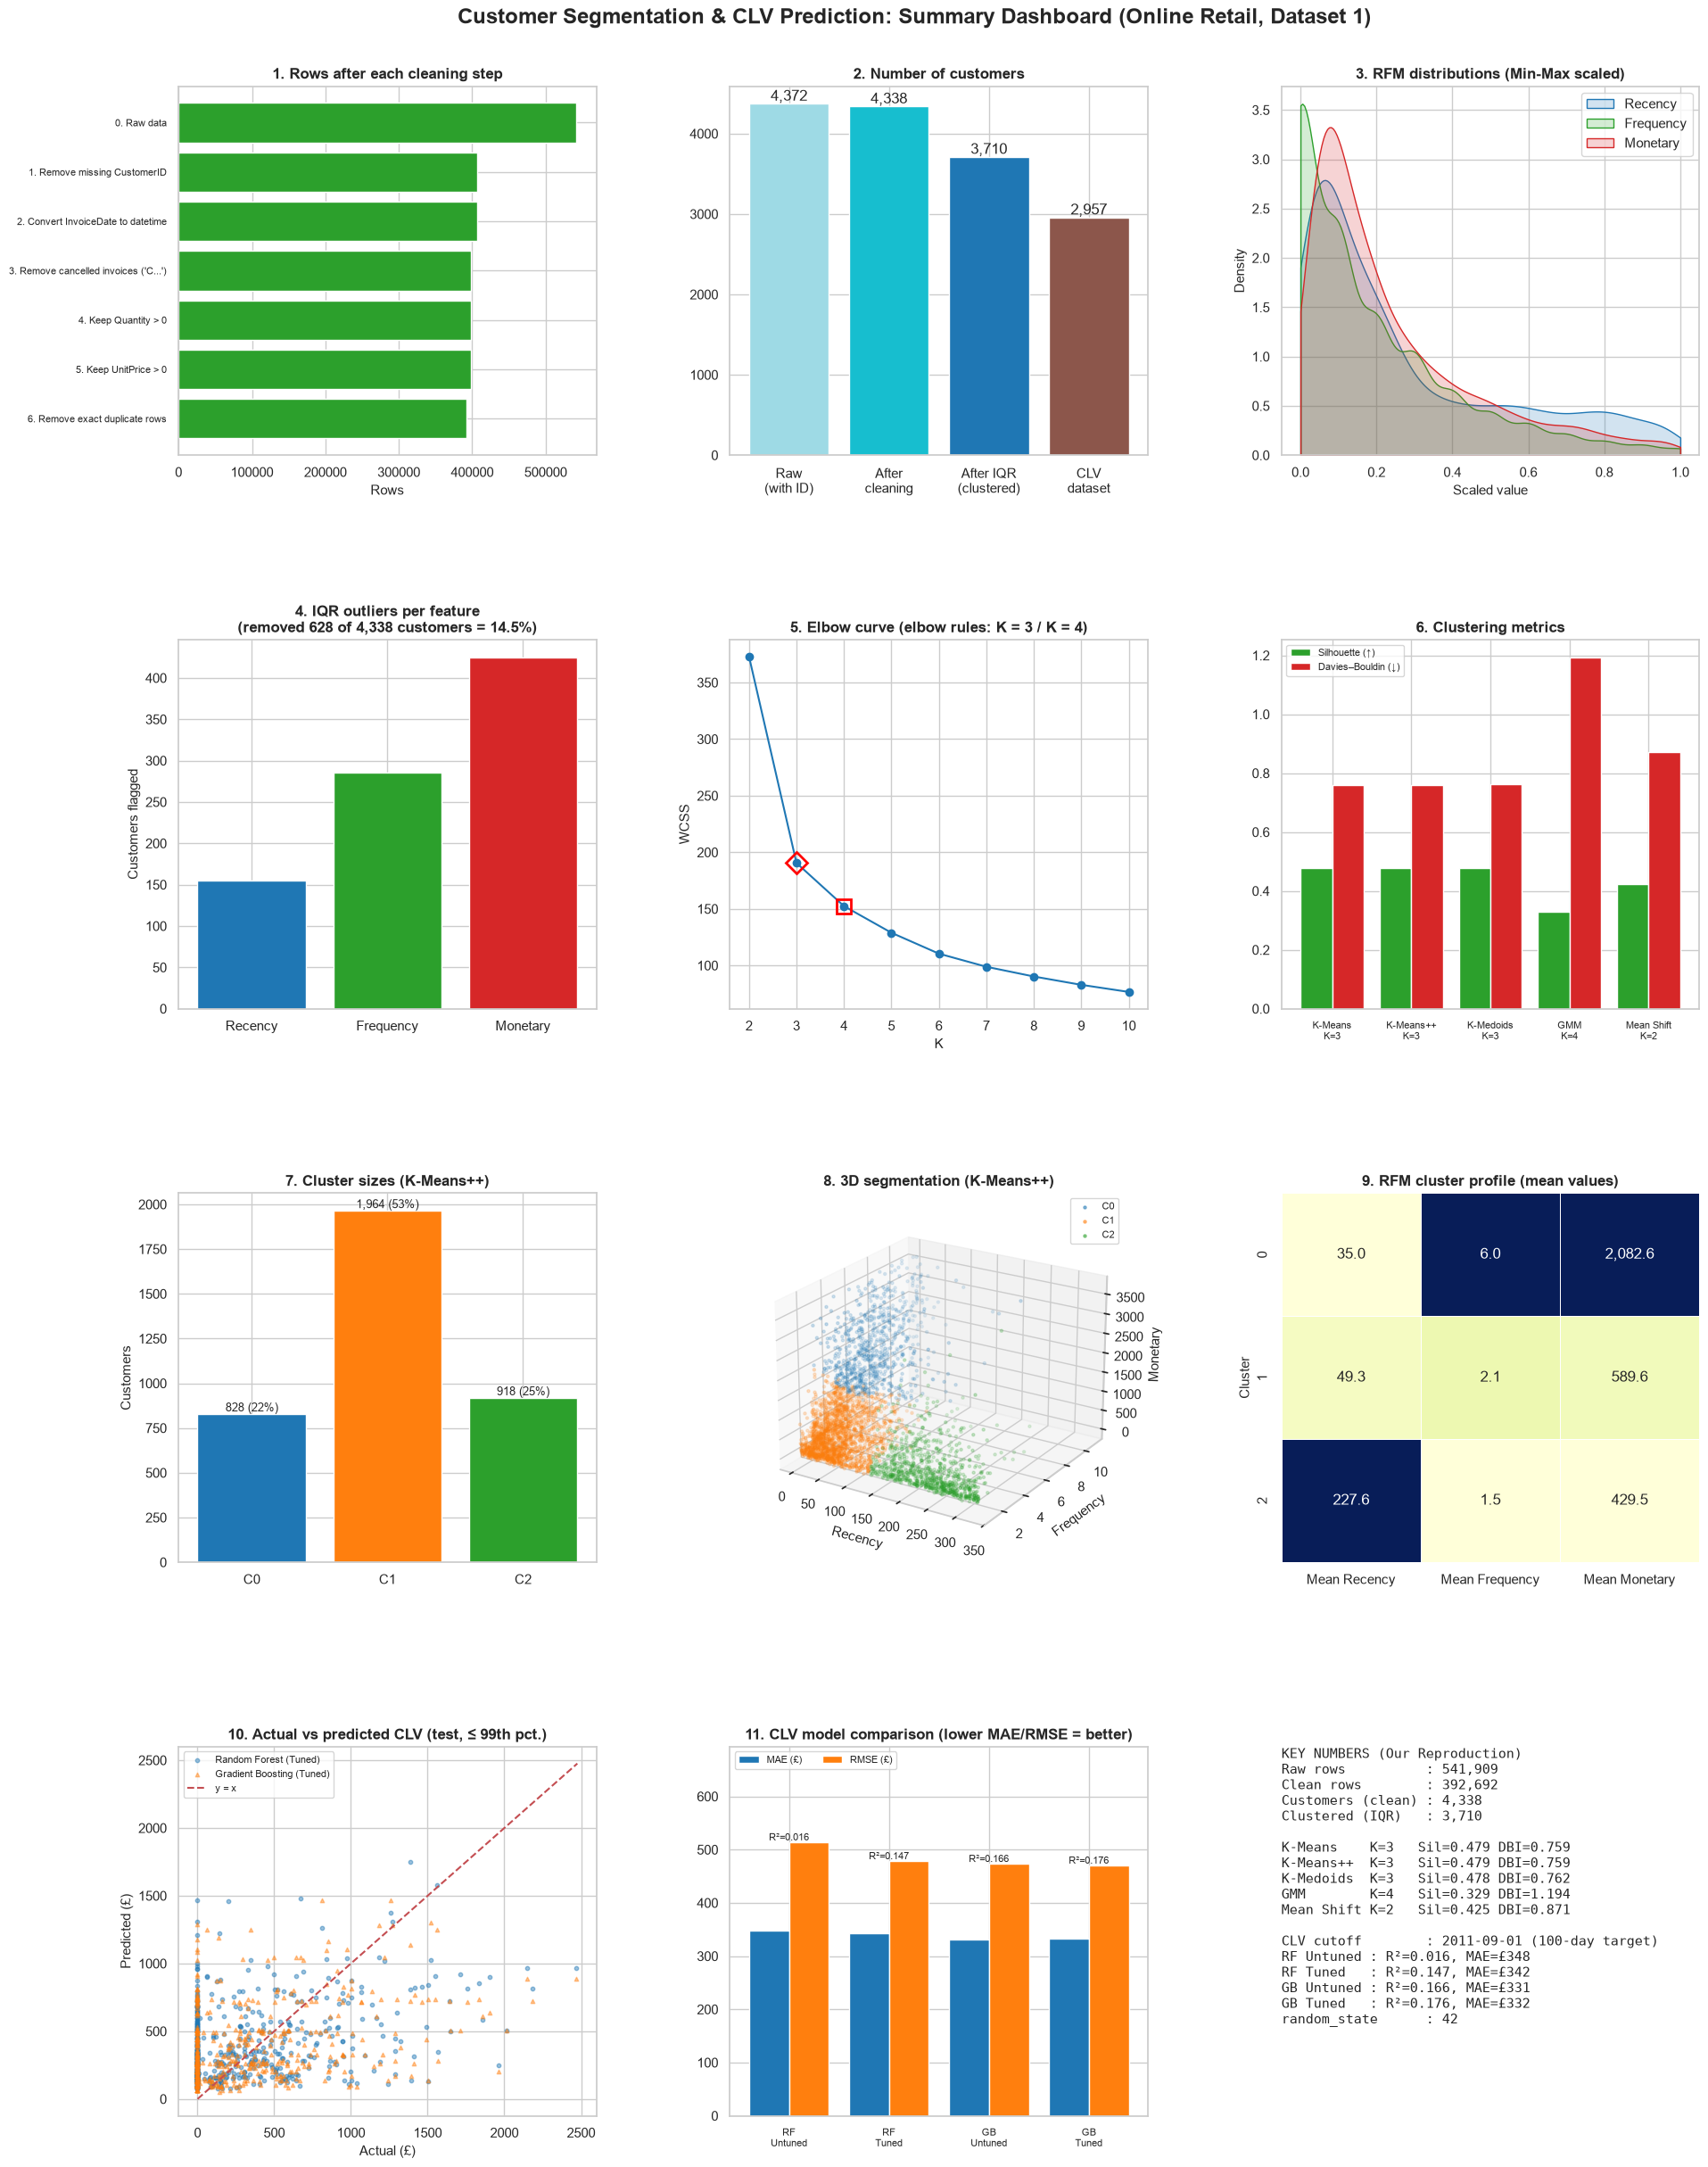

In [45]:
# =====================================================================
# 25.2  SUMMARY DASHBOARD (11 panels + key numbers)
# =====================================================================
fig = plt.figure(figsize=(22, 25))
grid = fig.add_gridspec(4, 3, hspace=0.5, wspace=0.32, top=0.95, bottom=0.04)
primary_k = cluster_results[PRIMARY_MODEL]["Number of Clusters"]
primary_palette = cluster_palette(primary_k)

# 1. Dataset size before/after cleaning
ax = fig.add_subplot(grid[0, 0])
ax.barh(preprocessing_summary["Step"], preprocessing_summary["Rows Remaining"], color="#2ca02c")
ax.invert_yaxis()
ax.set_title("1. Rows after each cleaning step")
ax.set_xlabel("Rows")
ax.tick_params(axis="y", labelsize=8)

# 2. Number of customers at each stage
ax = fig.add_subplot(grid[0, 1])
stages = {"Raw\n(with ID)": df_raw["CustomerID"].nunique(), "After\ncleaning": df_clean["CustomerID"].nunique(),
          "After IQR\n(clustered)": len(rfm_clean), "CLV\ndataset": len(clv_data)}
bars = ax.bar(list(stages), list(stages.values()), color=["#9edae5", "#17becf", "#1f77b4", "#8c564b"])
for bar, v in zip(bars, stages.values()):
    ax.annotate(f"{v:,}", (bar.get_x() + bar.get_width() / 2, v), ha="center", va="bottom")
ax.set_title("2. Number of customers")

# 3. RFM distributions (scaled, after outlier removal)
ax = fig.add_subplot(grid[0, 2])
for col in RFM_COLS:
    sns.kdeplot(rfm_scaled[col], ax=ax, label=col, color=colors[col], fill=True, alpha=0.2, cut=0)
ax.set_title("3. RFM distributions (Min-Max scaled)")
ax.set_xlabel("Scaled value")
ax.legend()

# 4. Outlier removal
ax = fig.add_subplot(grid[1, 0])
ax.bar(iqr_bounds.index, iqr_bounds["Outliers (customers)"], color=[colors[c] for c in iqr_bounds.index])
ax.set_title(f"4. IQR outliers per feature\n(removed {n_before - n_after:,} of {n_before:,} customers = "
             f"{(n_before - n_after) / n_before:.1%})")
ax.set_ylabel("Customers flagged")

# 5. Elbow curve
ax = fig.add_subplot(grid[1, 1])
ax.plot(elbow_table["K"], elbow_table["Inertia (WCSS)"], "o-", color="#1f77b4")
for k_mark, marker in [(elbow_k_distance, "s"), (elbow_k_bend, "D")]:
    ax.plot(k_mark, elbow_table.set_index("K").loc[k_mark, "Inertia (WCSS)"], marker, markersize=12,
            markerfacecolor="none", markeredgewidth=2, color="red")
ax.set_title(f"5. Elbow curve (elbow rules: K = {elbow_k_bend} / K = {elbow_k_distance})")
ax.set_xlabel("K")
ax.set_ylabel("WCSS")

# 6. Clustering metric comparison
ax = fig.add_subplot(grid[1, 2])
x = np.arange(len(MODEL_ORDER))
ax.bar(x - 0.2, clustering_comparison["Silhouette Score"], 0.4, label="Silhouette (↑)", color="#2ca02c")
ax.bar(x + 0.2, clustering_comparison["Davies-Bouldin Index"], 0.4, label="Davies–Bouldin (↓)", color="#d62728")
ax.set_xticks(x)
ax.set_xticklabels([f"{m}\nK={k}" for m, k in zip(MODEL_ORDER, clustering_comparison["Number of Clusters"])], fontsize=8)
ax.set_title("6. Clustering metrics")
ax.legend(fontsize=8)

# 7. Cluster sizes (primary segmentation)
ax = fig.add_subplot(grid[2, 0])
sizes = pd.Series(primary_labels).value_counts().sort_index()
ax.bar([f"C{c}" for c in sizes.index], sizes.values, color=primary_palette)
for i, v in enumerate(sizes.values):
    ax.text(i, v, f"{v:,} ({v / sizes.sum():.0%})", ha="center", va="bottom", fontsize=9)
ax.set_title(f"7. Cluster sizes ({PRIMARY_MODEL})")
ax.set_ylabel("Customers")

# 8. 3D segmentation
ax = fig.add_subplot(grid[2, 1], projection="3d")
for color, c in zip(primary_palette, sizes.index):
    mask = primary_labels == c
    ax.scatter(rfm_clean.loc[mask, "Recency"], rfm_clean.loc[mask, "Frequency"], rfm_clean.loc[mask, "Monetary"],
               s=5, alpha=0.5, color=color, label=f"C{c}")
ax.set_xlabel("Recency")
ax.set_ylabel("Frequency")
ax.set_zlabel("Monetary")
ax.view_init(elev=22, azim=-58)
ax.set_title(f"8. 3D segmentation ({PRIMARY_MODEL})")
ax.legend(fontsize=8)

# 9. RFM profile heatmap
ax = fig.add_subplot(grid[2, 2])
sns.heatmap(colour_scale, annot=annotations, fmt="", cmap="YlGnBu", ax=ax, cbar=False, linewidths=0.5)
ax.set_title("9. RFM cluster profile (mean values)")

# 10. Actual vs predicted CLV (tuned models, zoom to the 99th percentile)
ax = fig.add_subplot(grid[3, 0])
limit = np.quantile(y_test, 0.99)
for name, color, marker in [("Random Forest (Tuned)", "#1f77b4", "o"), ("Gradient Boosting (Tuned)", "#ff7f0e", "^")]:
    mask = y_test.to_numpy() <= limit
    ax.scatter(y_test.to_numpy()[mask], clv_test_predictions[name][mask], s=10, alpha=0.45, color=color,
               marker=marker, label=name)
ax.plot([0, limit], [0, limit], "r--", label="y = x")
ax.set_title("10. Actual vs predicted CLV (test, ≤ 99th pct.)")
ax.set_xlabel("Actual (£)")
ax.set_ylabel("Predicted (£)")
ax.legend(fontsize=8)

# 11. CLV model comparison
ax = fig.add_subplot(grid[3, 1])
x = np.arange(len(clv_model_results))
ax.bar(x - 0.2, clv_model_results["MAE"], 0.4, label="MAE (£)", color="#1f77b4")
ax.bar(x + 0.2, clv_model_results["RMSE"], 0.4, label="RMSE (£)", color="#ff7f0e")
for i, r2 in enumerate(clv_model_results["R²"]):
    ax.text(i, max(clv_model_results.loc[i, "MAE"], clv_model_results.loc[i, "RMSE"]), f"R²={r2:.3f}",
            ha="center", va="bottom", fontsize=8)
ax.set_xticks(x)
ax.set_xticklabels([f"{m.replace('Gradient Boosting', 'GB').replace('Random Forest', 'RF')}\n{t}"
                    for m, t in zip(clv_model_results["Model"], clv_model_results["Tuned/Untuned"])], fontsize=8)
ax.set_ylim(0, clv_model_results[["MAE", "RMSE"]].to_numpy().max() * 1.35)
ax.set_title("11. CLV model comparison (lower MAE/RMSE = better)")
ax.legend(fontsize=8, loc="upper left", ncol=2)

# 12. Key numbers
ax = fig.add_subplot(grid[3, 2])
ax.axis("off")
short_name = {"Random Forest": "RF", "Gradient Boosting": "GB"}
key_text = "\n".join([
    "KEY NUMBERS (Our Reproduction)",
    f"Raw rows          : {len(df_raw):,}",
    f"Clean rows        : {len(df_clean):,}",
    f"Customers (clean) : {df_clean['CustomerID'].nunique():,}",
    f"Clustered (IQR)   : {len(rfm_clean):,}",
    "",
    *[f"{m:<11}K={cluster_results[m]['Number of Clusters']:<3} Sil={cluster_results[m]['Silhouette Score']:.3f} "
      f"DBI={cluster_results[m]['Davies-Bouldin Index']:.3f}" for m in MODEL_ORDER],
    "",
    f"CLV cutoff        : {cutoff.date()} ({prediction_days}-day target)",
    *[f"{short_name[m]} {t:<8}: R²={clv_results[(m, t)]['R²']:.3f}, MAE=£{clv_results[(m, t)]['MAE']:,.0f}"
      for m, t in CLV_ORDER],
    f"random_state      : {RANDOM_STATE}",
])
ax.text(0, 1, key_text, va="top", ha="left", family="monospace", fontsize=10.5)
fig.suptitle("Customer Segmentation & CLV Prediction: Summary Dashboard (Online Retail, Dataset 1)",
             fontsize=17, fontweight="bold", y=0.985)
save_fig(fig, "fig_25_dashboard")


Clustering: Reference Paper Result vs Our Reproduction Result (Dataset 1)


,Model,Paper K range tested,Paper K,Paper Silhouette,Paper Davies-Bouldin,Our K range tested,Our K,Our Silhouette,Our Davies-Bouldin,Our K nearest paper K,Our Silhouette at paper K,Our Davies-Bouldin at paper K
0,K-Means,4 only (Table 25),4,0.5012,0.7481,2–10,3,0.4787,0.7591,4,0.4076,0.9162
1,K-Means++,4–10 (Table 4),4,0.5012,0.7481,2–10,3,0.4787,0.7591,4,0.4076,0.9162
2,K-Medoids,6–10 (Table 5),7,0.3894,0.9561,2–10,3,0.4775,0.7621,7,0.2902,1.1235
3,GMM,8–10 (Table 6),8,0.0452,2.6394,2–10,4,0.3294,1.1936,8,0.0238,2.3188
4,Mean Shift,one setting (Table 7),5,0.4027,1.3553,6 bandwidths,2,0.4246,0.8706,6,0.4003,1.3230


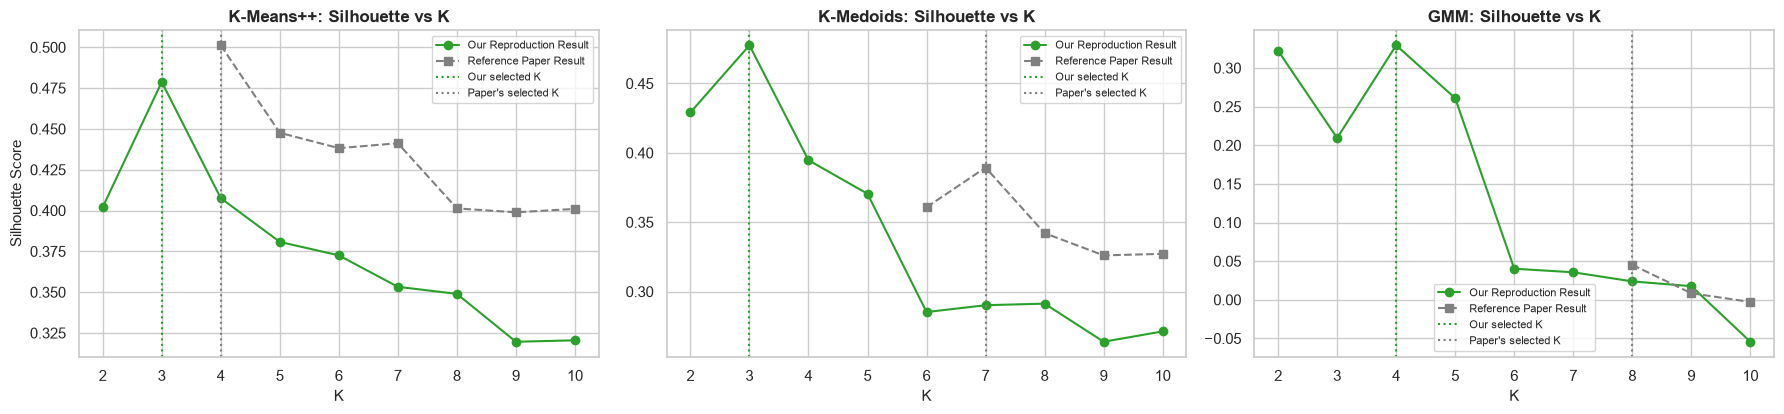

In [46]:
# =====================================================================
# 26.1  CLUSTERING: Reference Paper Result vs Our Reproduction Result
# =====================================================================
PAPER_K_RANGE = {"K-Means": "4 only (Table 25)", "K-Means++": "4–10 (Table 4)", "K-Medoids": "6–10 (Table 5)",
                 "GMM": "8–10 (Table 6)", "Mean Shift": "one setting (Table 7)"}
paper_idx = PAPER_CLUSTERING.set_index("Model")
clustering_vs_paper_rows = []
for name in MODEL_ORDER:
    paper_k = int(paper_idx.loc[name, "Paper K"])
    ours = cluster_results[name]
    if name == "Mean Shift":        # no K parameter: use our bandwidth setting whose cluster count is closest to the paper's
        row = meanshift_search.iloc[(meanshift_search["Number of Clusters"] - paper_k).abs().argmin()]
        k_at, sil_at, dbi_at = int(row["Number of Clusters"]), row["Silhouette Score"], row["Davies-Bouldin Index"]
        our_range = f"{len(MEANSHIFT_QUANTILES)} bandwidths"
    else:
        row = ours["sweep"].set_index("K").loc[paper_k]
        k_at, sil_at, dbi_at = paper_k, row["Silhouette Score"], row["Davies-Bouldin Index"]
        our_range = f"{K_RANGE[0]}–{K_RANGE[-1]}"
    clustering_vs_paper_rows.append({
        "Model": name,
        "Paper K range tested": PAPER_K_RANGE[name],
        "Paper K": paper_k,
        "Paper Silhouette": paper_idx.loc[name, "Paper Silhouette"],
        "Paper Davies-Bouldin": paper_idx.loc[name, "Paper Davies-Bouldin"],
        "Our K range tested": our_range,
        "Our K": ours["Number of Clusters"],
        "Our Silhouette": ours["Silhouette Score"],
        "Our Davies-Bouldin": ours["Davies-Bouldin Index"],
        "Our K nearest paper K": k_at,
        "Our Silhouette at paper K": sil_at,
        "Our Davies-Bouldin at paper K": dbi_at,
    })
clustering_vs_paper = pd.DataFrame(clustering_vs_paper_rows)
banner("Clustering: Reference Paper Result vs Our Reproduction Result (Dataset 1)")
display(clustering_vs_paper.round(4))

# Silhouette vs K: our full sweep vs the paper's reported points
fig, axes = plt.subplots(1, 3, figsize=(18, 4.3))
for ax, name in zip(axes, ["K-Means++", "K-Medoids", "GMM"]):
    sweep = cluster_results[name]["sweep"]
    paper_points = PAPER_K_TABLES[name]
    ax.plot(sweep["K"], sweep["Silhouette Score"], "o-", color="#2ca02c", label="Our Reproduction Result")
    ax.plot(sorted(paper_points), [paper_points[k][0] for k in sorted(paper_points)], "s--", color="gray",
            label="Reference Paper Result")
    ax.axvline(cluster_results[name]["Number of Clusters"], color="#2ca02c", linestyle=":", label="Our selected K")
    ax.axvline(int(paper_idx.loc[name, "Paper K"]), color="gray", linestyle=":", label="Paper's selected K")
    ax.set_title(f"{name}: Silhouette vs K")
    ax.set_xlabel("K")
    ax.set_xticks(K_RANGE)
    ax.legend(fontsize=8, loc="best")
axes[0].set_ylabel("Silhouette Score")
fig.tight_layout()
save_fig(fig, "fig_26_paper_vs_ours_silhouette")

In [47]:
# =====================================================================
# 26.2  CLV MODELS: Reference Paper Result vs Our Reproduction Result
# =====================================================================
clv_vs_paper = PAPER_CLV.merge(clv_model_results[["Model", "Tuned/Untuned", "MAE", "MSE", "RMSE", "R²"]],
                               on=["Model", "Tuned/Untuned"])
clv_vs_paper = clv_vs_paper.rename(columns={"MAE": "Our MAE", "MSE": "Our MSE", "RMSE": "Our RMSE", "R²": "Our R²"})
clv_vs_paper = clv_vs_paper[["Model", "Tuned/Untuned", "Paper MAE", "Our MAE", "Paper MSE", "Our MSE", "Our RMSE",
                             "Paper R²", "Our R²"]]
banner("CLV prediction: Reference Paper Result (Table 16) vs Our Reproduction Result")
display(clv_vs_paper.round(4))
print("⚠ These numbers are NOT directly comparable: the paper's CLV target is not specified, while ours is net")
print("  future revenue predicted only from information available before the cutoff (no leakage).")


CLV prediction: Reference Paper Result (Table 16) vs Our Reproduction Result


,Model,Tuned/Untuned,Paper MAE,Our MAE,Paper MSE,Our MSE,Our RMSE,Paper R²,Our R²
0,Random Forest,Untuned,2.3903,348.0891,243.4673,263762.2145,513.5779,0.9999,0.0160
1,Random Forest,Tuned,2.4558,342.1673,348.9028,228545.9016,478.0647,0.9999,0.1474
2,Gradient Boosting,Untuned,15.5569,331.3477,831.1362,223682.1323,472.9505,0.9998,0.1655
3,Gradient Boosting,Tuned,2.4212,332.3482,11.9509,220795.6539,469.8890,0.9999,0.1763


⚠ These numbers are NOT directly comparable: the paper's CLV target is not specified, while ours is net
  future revenue predicted only from information available before the cutoff (no leakage).


In [48]:
# =====================================================================
# 26.3  COMPONENT-BY-COMPONENT COMPARISON + DOCUMENTED DIFFERENCES
# =====================================================================
def metrics_text(name):
    r = cluster_results[name]
    return f"K = {r['Number of Clusters']}, Silhouette {r['Silhouette Score']:.4f}, DBI {r['Davies-Bouldin Index']:.4f}"

def clv_text(model_name):
    u, t = clv_results[(model_name, "Untuned")], clv_results[(model_name, "Tuned")]
    return (f"Untuned: MAE {u['MAE']:.2f}, MSE {u['MSE']:,.0f}, R² {u['R²']:.4f}. "
            f"Tuned: MAE {t['MAE']:.2f}, MSE {t['MSE']:,.0f}, R² {t['R²']:.4f}.")

paper_vs_ours = pd.DataFrame([
    ("Dataset",
     "Two Kaggle datasets. Dataset 1 (Online Retail): 1,067,372 rows, columns Invoice/Price/Customer ID; "
     "4,382 missing Descriptions and 243,007 missing Customer IDs (Fig. 1). Dataset 2: Superstore (9,994 rows).",
     f"Dataset 1 only: '{data_path.name}', {len(df_raw):,} rows ({df_raw['InvoiceDate'].min().date()} to "
     f"{df_raw['InvoiceDate'].max().date()}); {int(df_raw['Description'].isna().sum()):,} missing Descriptions and "
     f"{int(df_raw['CustomerID'].isna().sum()):,} missing CustomerIDs. Dataset 2 unavailable, so not reproduced."),
    ("Preprocessing",
     "Drop rows with NaN, convert the invoice date, exclude cancelled transactions, keep non-negative Quantity and Price.",
     f"Same steps (missing CustomerID, 'C' invoices, Quantity > 0, UnitPrice > 0) + exact-duplicate removal "
     f"({'on' if REMOVE_DUPLICATES else 'off'}) → {len(df_clean):,} rows, {df_clean['CustomerID'].nunique():,} customers."),
    ("RFM",
     "Recency, Frequency, Monetary per customer (Fig. 4).",
     f"Recency = days since last purchase (snapshot = last date + 1 day), Frequency = unique invoices, "
     f"Monetary = total revenue → {len(rfm_raw):,} customers."),
    ("Outlier removal",
     "IQR rule (Q1 − 1.5·IQR, Q3 + 1.5·IQR) on R, F, M; Fig. 8 shows 5,777 customers after preprocessing.",
     f"Same rule on all three features at once: {len(rfm_raw):,} → {len(rfm_clean):,} customers "
     f"({(len(rfm_raw) - len(rfm_clean)) / len(rfm_raw):.1%} removed)."),
    ("Normalization", "Min-Max normalisation to [0, 1].", "MinMaxScaler to [0, 1] (min = 0 and max = 1 verified)."),
    ("Elbow Method",
     "K-Means elbow → K = 4 (Fig. 10); K-Medoids elbow → K = 6 (Fig. 12).",
     f"K-Means WCSS for K = 2–10: sharpest bend at K = {elbow_k_bend}, max-distance rule K = {elbow_k_distance}; "
     "K-Medoids cost curve also shown."),
    ("K-Means", "K = 4, Silhouette 0.5012, DBI 0.7481 (Table 25).", metrics_text("K-Means") + " (init='random')."),
    ("K-Means++", "K = 4 (tested K = 4–10), Silhouette 0.5012, DBI 0.7481.", metrics_text("K-Means++") + "."),
    ("K-Medoids", "K = 7 (tested K = 6–10), Silhouette 0.3894, DBI 0.9561.",
     metrics_text("K-Medoids") + f" (PAM; {KMEDOIDS_BACKEND})."),
    ("GMM", "K = 8 (tested K = 8–10), Silhouette 0.0452, DBI 2.6394.", metrics_text("GMM") + "."),
    ("Mean Shift", "5 clusters, Silhouette 0.4027, DBI 1.3553 (bandwidth not reported).",
     metrics_text("Mean Shift") + f" (bandwidth {meanshift_bandwidth:.3f})."),
    ("Silhouette Score", "Higher = better; main criterion for choosing K.",
     "Same criterion (scikit-learn, Euclidean distance on scaled RFM)."),
    ("Davies-Bouldin Index", "Lower = better; secondary criterion.", "Same (scikit-learn)."),
    ("Random Forest", "Untuned: MAE 2.3903, MSE 243.4673, R² 0.9999. Tuned: MAE 2.4558, MSE 348.9028, R² 0.9999.",
     clv_text("Random Forest")),
    ("Gradient Boosting", "Untuned: MAE 15.5569, MSE 831.1362, R² 0.9998. Tuned: MAE 2.4212, MSE 11.9509, R² 0.9999.",
     clv_text("Gradient Boosting")),
    ("Hyperparameter tuning", "RandomizedSearchCV (search space and iterations not reported).",
     f"RandomizedSearchCV: {SEARCH_ITERATIONS} candidates × {CV_FOLDS}-fold CV, scoring = R², random_state = {RANDOM_STATE}."),
    ("CLV",
     "Target construction not specified; tuned Gradient Boosting used for the final High/Low CLV per cluster.",
     f"Operational CLV proxy = net revenue in the {prediction_days} days from {cutoff.date()}, predicted from "
     f"pre-cutoff RFM + K-Means++ segment (leakage-safe). Paper-style High/Low table in Section 24.2."),
], columns=["Component", "Reference Paper", "Our Reproduction"])
banner("Component-by-component comparison")
with pd.option_context("display.max_colwidth", None):
    display(paper_vs_ours)

paper_k_scores = {name: clustering_vs_paper.set_index("Model").loc[name] for name in ["K-Means++", "K-Medoids", "GMM"]}
clv_r2_values = clv_model_results["R²"]
documented_differences = [
    f"Dataset version: the paper reports {PAPER['dataset_rows']:,} rows and {PAPER['missing_customer_id']:,} missing Customer IDs; "
    f"our file has {len(df_raw):,} rows and {int(df_raw['CustomerID'].isna().sum()):,}. The paper's figures and column names "
    "(Invoice, Price, Customer ID) match the larger 2009–2011 'Online Retail II' version of this data.",
    f"Customers after preprocessing: the paper's Fig. 8 shows {PAPER['customers_after_preprocessing']:,}; we cluster {len(rfm_clean):,} "
    f"customers after applying the IQR rule to all three features (from {len(rfm_raw):,}).",
    "K ranges: the paper's Silhouette/DBI tables start at K = 4 (K-Means++), K = 6 (K-Medoids) and K = 8 (GMM). "
    f"We evaluate K = {K_RANGE[0]}–{K_RANGE[-1]}, so a smaller K is selected whenever it scores better.",
    "At the paper's K values our scores are: " + "; ".join(
        f"{name} K={int(v['Paper K'])}: Silhouette {v['Our Silhouette at paper K']:.4f} vs paper {v['Paper Silhouette']:.4f}"
        for name, v in paper_k_scores.items()) + ".",
    "GMM: at larger K, several components collapse onto single Frequency values (Section 15.2), which explains a very low "
    "Silhouette. The paper reports the same pattern (0.0452 at K = 8).",
    f"Inertia values are not comparable between studies: they grow with the number of customers and depend on the scaling "
    f"(the paper's Fig. 10 shows about 9,800 at K = 2; ours is {elbow_table.loc[0, 'Inertia (WCSS)']:.0f} for {len(rfm_clean):,} "
    "customers in [0, 1]³).",
    f"CLV: the paper reports R² ≈ 0.9999 for every model with an unspecified target. Our leakage-safe future-revenue "
    f"target gives R² between {clv_r2_values.min():.3f} and {clv_r2_values.max():.3f}. They measure different things and "
    "must not be compared as if they were the same task.",
    "Recency wording: the paper sometimes describes high-Recency clusters as 'recent'. Here Recency is always days since "
    "the last purchase, so LOW Recency = recent.",
]
banner("Documented differences between the paper and our reproduction")
for i, text in enumerate(documented_differences, 1):
    print(f"{i}. {text}")


Component-by-component comparison


,Component,Reference Paper,Our Reproduction
0,Dataset,"Two Kaggle datasets. Dataset 1 (Online Retail): 1,067,372 rows, columns Invoice/Price/Customer ID; 4,382 missing Descriptions and 243,007 missing Customer IDs (Fig. 1). Dataset 2: Superstore (9,994 rows).","Dataset 1 only: 'Online Retail.xlsx', 541,909 rows (2010-12-01 to 2011-12-09); 1,454 missing Descriptions and 135,080 missing CustomerIDs. Dataset 2 unavailable, so not reproduced."
1,Preprocessing,"Drop rows with NaN, convert the invoice date, exclude cancelled transactions, keep non-negative Quantity and Price.","Same steps (missing CustomerID, 'C' invoices, Quantity > 0, UnitPrice > 0) + exact-duplicate removal (on) → 392,692 rows, 4,338 customers."
2,RFM,"Recency, Frequency, Monetary per customer (Fig. 4).","Recency = days since last purchase (snapshot = last date + 1 day), Frequency = unique invoices, Monetary = total revenue → 4,338 customers."
3,Outlier removal,"IQR rule (Q1 − 1.5·IQR, Q3 + 1.5·IQR) on R, F, M; Fig. 8 shows 5,777 customers after preprocessing.","Same rule on all three features at once: 4,338 → 3,710 customers (14.5% removed)."
4,Normalization,"Min-Max normalisation to [0, 1].","MinMaxScaler to [0, 1] (min = 0 and max = 1 verified)."
5,Elbow Method,K-Means elbow → K = 4 (Fig. 10); K-Medoids elbow → K = 6 (Fig. 12).,"K-Means WCSS for K = 2–10: sharpest bend at K = 3, max-distance rule K = 4; K-Medoids cost curve also shown."
6,K-Means,"K = 4, Silhouette 0.5012, DBI 0.7481 (Table 25).","K = 3, Silhouette 0.4787, DBI 0.7591 (init='random')."
7,K-Means++,"K = 4 (tested K = 4–10), Silhouette 0.5012, DBI 0.7481.","K = 3, Silhouette 0.4787, DBI 0.7591."
8,K-Medoids,"K = 7 (tested K = 6–10), Silhouette 0.3894, DBI 0.9561.","K = 3, Silhouette 0.4775, DBI 0.7621 (PAM; built-in PAM (SimpleKMedoids))."
9,GMM,"K = 8 (tested K = 8–10), Silhouette 0.0452, DBI 2.6394.","K = 4, Silhouette 0.3294, DBI 1.1936."



Documented differences between the paper and our reproduction
1. Dataset version: the paper reports 1,067,372 rows and 243,007 missing Customer IDs; our file has 541,909 rows and 135,080. The paper's figures and column names (Invoice, Price, Customer ID) match the larger 2009–2011 'Online Retail II' version of this data.
2. Customers after preprocessing: the paper's Fig. 8 shows 5,777; we cluster 3,710 customers after applying the IQR rule to all three features (from 4,338).
3. K ranges: the paper's Silhouette/DBI tables start at K = 4 (K-Means++), K = 6 (K-Medoids) and K = 8 (GMM). We evaluate K = 2–10, so a smaller K is selected whenever it scores better.
4. At the paper's K values our scores are: K-Means++ K=4: Silhouette 0.4076 vs paper 0.5012; K-Medoids K=7: Silhouette 0.2902 vs paper 0.3894; GMM K=8: Silhouette 0.0238 vs paper 0.0452.
5. GMM: at larger K, several components collapse onto single Frequency values (Section 15.2), which explains a very low Silhouette. The paper repo

In [49]:
# =====================================================================
# 26.4  ILLUSTRATION ONLY: in-period "CLV" target (target leakage), NOT one of our results
# =====================================================================
leaky = rfm_clean[RFM_COLS].copy()
leaky["Cluster"] = cluster_results["K-Means++"]["labels"]
average_order_value = leaky["Monetary"] / leaky["Frequency"]
leaky_target = average_order_value * leaky["Frequency"]        # = historical Monetary: computed from the inputs
leaky_X = leaky[RFM_COLS].copy()
for c in sorted(leaky["Cluster"].unique()):
    leaky_X[f"Cluster_{c}"] = (leaky["Cluster"] == c).astype(int)
lx_train, lx_test, ly_train, ly_test = train_test_split(leaky_X, leaky_target, test_size=TEST_SIZE,
                                                        random_state=RANDOM_STATE)
illustration_rows = []
for name, model in [("Random Forest", RandomForestRegressor(random_state=RANDOM_STATE, n_jobs=-1)),
                    ("Gradient Boosting", GradientBoostingRegressor(random_state=RANDOM_STATE))]:
    model.fit(lx_train, ly_train)
    illustration_rows.append({"Model (untuned)": name, **regression_metrics(ly_test, model.predict(lx_test))})
illustration_table = pd.DataFrame(illustration_rows)
banner("ILLUSTRATION ONLY: leaky in-period target (not comparable, not our result)")
display(illustration_table.round(4))
print(f"With a target that can be computed from the inputs, R² = {illustration_table['R²'].min():.4f} to "
      f"{illustration_table['R²'].max():.4f} (the paper's Table 16 reports 0.9998 to 0.9999).")
print("Such scores measure how well a model re-computes a known quantity, not how well it forecasts future value.")
print("Our main CLV models (Sections 20–24) avoid this by predicting FUTURE revenue from past behaviour only.")


ILLUSTRATION ONLY: leaky in-period target (not comparable, not our result)


,Model (untuned),MAE,MSE,RMSE,R²
0,Random Forest,0.6752,2.1716,1.4737,1.0000
1,Gradient Boosting,4.4501,37.7407,6.1433,0.9999


With a target that can be computed from the inputs, R² = 0.9999 to 1.0000 (the paper's Table 16 reports 0.9998 to 0.9999).
Such scores measure how well a model re-computes a known quantity, not how well it forecasts future value.
Our main CLV models (Sections 20–24) avoid this by predicting FUTURE revenue from past behaviour only.


In [50]:
# =====================================================================
# 27.1  DATA-DRIVEN CONCLUSION
# =====================================================================
lines = []
lines.append(f"1. DATA: {len(df_raw):,} raw transactions → {len(df_clean):,} after the paper's cleaning steps "
             f"({df_clean['CustomerID'].nunique():,} customers, £{df_clean['Revenue'].sum():,.0f} revenue).")
lines.append(f"2. RFM + IQR + MIN-MAX: {len(rfm_raw):,} customers → {len(rfm_clean):,} after IQR outlier removal "
             f"({(len(rfm_raw) - len(rfm_clean)) / len(rfm_raw):.1%} removed); R, F, M scaled to [0, 1].")
lines.append(f"3. ELBOW: the K-Means WCSS curve bends at K = {elbow_k_bend} (sharpest bend) and K = {elbow_k_distance} "
             "(max-distance rule); the final K values come from the Silhouette Score and Davies–Bouldin Index.")
lines.append("4. CLUSTERING (Our Reproduction Results):")
for name in MODEL_ORDER:
    r = cluster_results[name]
    lines.append(f"   • {name:<10}: {r['Number of Clusters']} clusters, Silhouette = {r['Silhouette Score']:.4f}, "
                 f"Davies–Bouldin = {r['Davies-Bouldin Index']:.4f}  [{r['setting']}]")
lines.append(f"   Highest Silhouette in this run: {max_sil_model}; lowest Davies–Bouldin: {min_dbi_model}. "
             "These are reported facts, not a ranking. K-Means and K-Means++ agree with ARI = "
             f"{adjusted_rand_score(cluster_results['K-Means']['labels'], cluster_results['K-Means++']['labels']):.3f}.")
lines.append(f"5. SEGMENTS ({PRIMARY_MODEL}, K = {cluster_results[PRIMARY_MODEL]['Number of Clusters']}):")
for _, row in cluster_interpretation.merge(cluster_profile, on="Cluster").iterrows():
    lines.append(f"   • Cluster {row['Cluster']}: {row['% of Customers']:.1f}% of customers, {row['% of Revenue']:.1f}% of "
                 f"revenue; mean R = {row['Mean Recency']:.0f} days, F = {row['Mean Frequency']:.1f}, "
                 f"M = £{row['Mean Monetary']:,.0f} → {row['Data-driven interpretation']}.")
lines.append(f"6. CLV (operational proxy = net revenue in the {prediction_days} days after {cutoff.date()}, leakage-safe):")
for model_name, tuned in CLV_ORDER:
    m = clv_results[(model_name, tuned)]
    lines.append(f"   • {model_name} ({tuned}): MAE £{m['MAE']:,.2f}, RMSE £{m['RMSE']:,.2f}, R² {m['R²']:.4f}")
lines.append("   Future spending is noisy and heavy-tailed, so an honest out-of-time prediction explains only part of its "
             "variance. This is the main difference from the paper's near-perfect R² values.")
lines.append("7. REPRODUCTION: the paper's methodology was re-implemented step by step on Dataset 1. Our numbers differ from "
             "the paper's for the documented reasons in Section 26 (dataset version, preprocessing, K range, CLV target).")
conclusion_text = "\n".join(lines)
banner("CONCLUSION (generated from this run's results)")
print(conclusion_text)


CONCLUSION (generated from this run's results)
1. DATA: 541,909 raw transactions → 392,692 after the paper's cleaning steps (4,338 customers, £8,887,209 revenue).
2. RFM + IQR + MIN-MAX: 4,338 customers → 3,710 after IQR outlier removal (14.5% removed); R, F, M scaled to [0, 1].
3. ELBOW: the K-Means WCSS curve bends at K = 3 (sharpest bend) and K = 4 (max-distance rule); the final K values come from the Silhouette Score and Davies–Bouldin Index.
4. CLUSTERING (Our Reproduction Results):
   • K-Means   : 3 clusters, Silhouette = 0.4787, Davies–Bouldin = 0.7591  [K = 3, init='random', n_init=10]
   • K-Means++ : 3 clusters, Silhouette = 0.4787, Davies–Bouldin = 0.7591  [K = 3, init='k-means++', n_init=10]
   • K-Medoids : 3 clusters, Silhouette = 0.4775, Davies–Bouldin = 0.7621  [K = 3, PAM (BUILD + SWAP), backend: built-in PAM (SimpleKMedoids)]
   • GMM       : 4 clusters, Silhouette = 0.3294, Davies–Bouldin = 1.1936  [K = 4, covariance='full']
   • Mean Shift: 2 clusters, Silhouette 

In [51]:
# =====================================================================
# 28.1  SAVE CSV FILES + ZIP (+ automatic download in Colab)
# =====================================================================
saved_files = []

def save_csv(df, file_name, index=False):
    path = OUTPUT_DIR / file_name
    df.to_csv(path, index=index)
    saved_files.append(path)
    print(f"✔ {file_name:<42} {len(df):>9,} rows")

banner("Saving results")
# --- the 8 requested files ---
save_csv(df_clean, "cleaned_transactions.csv")
save_csv(rfm_raw, "rfm_raw.csv")
save_csv(rfm_clean, "rfm_clean.csv")
save_csv(rfm_scaled, "rfm_scaled.csv")
save_csv(clustering_comparison, "clustering_comparison.csv")
save_csv(cluster_profile.merge(cluster_interpretation, on="Cluster"), "cluster_profiles.csv")
save_csv(clv_model_results, "clv_model_results.csv")
clv_predictions = clv_test[["CustomerID", "Cluster"] + RFM_COLS + ["CLV_Target"]].rename(
    columns={"Cluster": "Segment (K-Means++ fitted on train)", "CLV_Target": "Actual CLV proxy (net future revenue)"})
for label, predictions in clv_test_predictions.items():
    clv_predictions[f"Predicted: {label}"] = predictions
save_csv(clv_predictions, "clv_predictions.csv")

# --- extra files useful for the report ---
save_csv(preprocessing_summary, "preprocessing_summary.csv")
save_csv(pd.concat([cluster_results[m]["sweep"].assign(Model=m) for m in ["K-Means", "K-Means++", "K-Medoids", "GMM"]],
                   ignore_index=True), "k_selection_all_models.csv")
save_csv(meanshift_search, "meanshift_bandwidth_search.csv")
save_csv(all_profiles, "cluster_profiles_all_algorithms.csv")
save_csv(clustering_vs_paper, "paper_vs_ours_clustering.csv")
save_csv(clv_vs_paper, "paper_vs_ours_clv.csv")
save_csv(paper_vs_ours, "paper_vs_ours_components.csv")
save_csv(cluster_clv.reset_index(), "paper_style_clv_per_cluster.csv")
save_csv(pd.DataFrame([{"Model": "Random Forest", "Best parameters": json.dumps(rf_best_params, default=str),
                        "Best CV R²": rf_search.best_score_},
                       {"Model": "Gradient Boosting", "Best parameters": json.dumps(gb_best_params, default=str),
                        "Best CV R²": gb_search.best_score_}]), "clv_best_hyperparameters.csv")
(OUTPUT_DIR / "conclusion.txt").write_text(conclusion_text, encoding="utf-8")
saved_files.append(OUTPUT_DIR / "conclusion.txt")

zip_path = Path("customer_segmentation_clv_results.zip")
with zipfile.ZipFile(zip_path, "w", compression=zipfile.ZIP_DEFLATED) as zf:
    for path in saved_files:
        zf.write(path, arcname=f"results/{path.name}")
    for figure_path in sorted(FIG_DIR.glob("*.png")):
        zf.write(figure_path, arcname=f"figures/{figure_path.name}")
print(f"\nZIP file: {zip_path.resolve()} ({zip_path.stat().st_size / 1e6:.1f} MB, "
      f"{len(saved_files)} result files + {len(list(FIG_DIR.glob('*.png')))} figures)")

try:
    from google.colab import files
    files.download(str(zip_path))
    print("Download started (check your browser's downloads).")
except ImportError:
    print("Not running in Google Colab: the files are in the 'outputs' folder and the ZIP is next to this notebook.")


Saving results


✔ cleaned_transactions.csv                     392,692 rows
✔ rfm_raw.csv                                    4,338 rows
✔ rfm_clean.csv                                  3,710 rows
✔ rfm_scaled.csv                                 3,710 rows
✔ clustering_comparison.csv                          5 rows
✔ cluster_profiles.csv                               3 rows
✔ clv_model_results.csv                              4 rows
✔ clv_predictions.csv                              592 rows
✔ preprocessing_summary.csv                          7 rows
✔ k_selection_all_models.csv                        36 rows
✔ meanshift_bandwidth_search.csv                     6 rows
✔ cluster_profiles_all_algorithms.csv               15 rows
✔ paper_vs_ours_clustering.csv                       5 rows
✔ paper_vs_ours_clv.csv                              4 rows
✔ paper_vs_ours_components.csv                      17 rows
✔ paper_style_clv_per_cluster.csv                    3 rows
✔ clv_best_hyperparameters.csv          


ZIP file: C:\Users\HP\AppData\Local\Temp\claude\C--Users-HP-Desktop-BNP\13500b59-68c3-4ed9-a4ad-c76a2e95f22c\scratchpad\nb\run4\customer_segmentation_clv_results.zip (17.2 MB, 18 result files + 36 figures)
Not running in Google Colab: the files are in the 'outputs' folder and the ZIP is next to this notebook.


In [52]:
# =====================================================================
# C. FINAL COMPARISON TABLES (re-displayed from the results above)
# =====================================================================
banner("C1. Clustering comparison (Our Reproduction Results)")
display(table4_clustering.round(4))
banner("C2. Clustering: Reference Paper Result vs Our Reproduction Result")
display(clustering_vs_paper[["Model", "Paper K", "Paper Silhouette", "Paper Davies-Bouldin", "Our K", "Our Silhouette",
                             "Our Davies-Bouldin", "Our Silhouette at paper K", "Our Davies-Bouldin at paper K"]].round(4))
banner("C3. CLV models (Our Reproduction Results)")
display(clv_model_results.round(4))
banner("C4. CLV: Reference Paper Result vs Our Reproduction Result (different targets, not directly comparable)")
display(clv_vs_paper.round(4))
banner("D. FINAL CONCLUSION (generated from this run)")
print(conclusion_text)


C1. Clustering comparison (Our Reproduction Results)


,Algorithm,Clusters,Silhouette,Davies-Bouldin
0,K-Means,3,0.4787,0.7591
1,K-Means++,3,0.4787,0.7591
2,K-Medoids,3,0.4775,0.7621
3,GMM,4,0.3294,1.1936
4,Mean Shift,2,0.4246,0.8706



C2. Clustering: Reference Paper Result vs Our Reproduction Result


,Model,Paper K,Paper Silhouette,Paper Davies-Bouldin,Our K,Our Silhouette,Our Davies-Bouldin,Our Silhouette at paper K,Our Davies-Bouldin at paper K
0,K-Means,4,0.5012,0.7481,3,0.4787,0.7591,0.4076,0.9162
1,K-Means++,4,0.5012,0.7481,3,0.4787,0.7591,0.4076,0.9162
2,K-Medoids,7,0.3894,0.9561,3,0.4775,0.7621,0.2902,1.1235
3,GMM,8,0.0452,2.6394,4,0.3294,1.1936,0.0238,2.3188
4,Mean Shift,5,0.4027,1.3553,2,0.4246,0.8706,0.4003,1.3230



C3. CLV models (Our Reproduction Results)


,Model,Tuned/Untuned,MAE,MSE,RMSE,R²
0,Random Forest,Untuned,348.0891,263762.2145,513.5779,0.0160
1,Random Forest,Tuned,342.1673,228545.9016,478.0647,0.1474
2,Gradient Boosting,Untuned,331.3477,223682.1323,472.9505,0.1655
3,Gradient Boosting,Tuned,332.3482,220795.6539,469.8890,0.1763



C4. CLV: Reference Paper Result vs Our Reproduction Result (different targets, not directly comparable)


,Model,Tuned/Untuned,Paper MAE,Our MAE,Paper MSE,Our MSE,Our RMSE,Paper R²,Our R²
0,Random Forest,Untuned,2.3903,348.0891,243.4673,263762.2145,513.5779,0.9999,0.0160
1,Random Forest,Tuned,2.4558,342.1673,348.9028,228545.9016,478.0647,0.9999,0.1474
2,Gradient Boosting,Untuned,15.5569,331.3477,831.1362,223682.1323,472.9505,0.9998,0.1655
3,Gradient Boosting,Tuned,2.4212,332.3482,11.9509,220795.6539,469.8890,0.9999,0.1763



D. FINAL CONCLUSION (generated from this run)
1. DATA: 541,909 raw transactions → 392,692 after the paper's cleaning steps (4,338 customers, £8,887,209 revenue).
2. RFM + IQR + MIN-MAX: 4,338 customers → 3,710 after IQR outlier removal (14.5% removed); R, F, M scaled to [0, 1].
3. ELBOW: the K-Means WCSS curve bends at K = 3 (sharpest bend) and K = 4 (max-distance rule); the final K values come from the Silhouette Score and Davies–Bouldin Index.
4. CLUSTERING (Our Reproduction Results):
   • K-Means   : 3 clusters, Silhouette = 0.4787, Davies–Bouldin = 0.7591  [K = 3, init='random', n_init=10]
   • K-Means++ : 3 clusters, Silhouette = 0.4787, Davies–Bouldin = 0.7591  [K = 3, init='k-means++', n_init=10]
   • K-Medoids : 3 clusters, Silhouette = 0.4775, Davies–Bouldin = 0.7621  [K = 3, PAM (BUILD + SWAP), backend: built-in PAM (SimpleKMedoids)]
   • GMM       : 4 clusters, Silhouette = 0.3294, Davies–Bouldin = 1.1936  [K = 4, covariance='full']
   • Mean Shift: 2 clusters, Silhouette =